# MSI5001 — Airline Sentiment Clustering: Research Implementation

**Research question:** How do data preparation, feature engineering, text representation and clustering algorithm choices influence sentiment cluster quality and interpretability?

**Research sequence:** Dataset audit → minimal preprocessing → lexical and semantic representations → three clustering algorithms → internal and external validation → scaling and weighting → hyperparameter sensitivity → human annotation audit → supplementary sentiment-specialised RoBERTa → evaluation coverage audit.

**Interpretation protocol:** Each experimental stage documents the question, frozen assignments, relevant metrics, limitations and implications. Use original tweet examples to illustrate errors; do not treat reference labels or unanimous model outputs as infallible.

**Reproducibility status:** Structurally reviewed and syntax checked; **not** independently executed end-to-end in this environment. The original uploaded notebook remains unchanged.

# MSI5001 | Airline sentiment clustering — Stage 1
**Purpose:** Audit the raw data, understand what each field means, explore language patterns, and prepare a clean *working copy* without touching the original.

**Assignment safeguard:** `airline_sentiment` and `sentiment_confidence` are **not clustering inputs**. Label distribution is inspected here for descriptive auditing only. Once clustering begins, labels stay isolated until post-hoc evaluation.

**Learning approach:** Run cells in order; read the question after each section and record your interpretation.

**Project data:** `Tweets (1).xlsx` (14,639 rows in the supplied file).

## Environment and execution guidance

This notebook was developed in VS Code/Jupyter. Run cells sequentially after configuring the dataset path in the next setup cell. Some later experiments use cached embeddings, frozen assignments, external model downloads and significant CPU/RAM; a full fresh-kernel run requires those dependencies. The original reference sentiment is used for audit and post-clustering evaluation, not to fit unsupervised clusters.

**Submission note:** Preserve the source Excel file, external model checkpoint details and the `outputs/` directory or document downloadable sources in `links.txt`. Large files must follow the assignment's 10 MB per-file rule.

In [6]:
%pip -q install openpyxl scikit-learn
import re, os, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display
pd.set_option('display.max_colwidth', 160)
print('pandas:', pd.__version__)

Note: you may need to restart the kernel to use updated packages.
pandas: 3.0.5



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1 | Load and inspect the source

Set `MSI5001_DATASET` as an environment variable pointing to the original `Tweets (1).xlsx`, or place that file alongside the notebook. The source file must not be modified.

In [7]:

# ============================================================
# DATASET LOADING — MSI5001 AIRLINE TWEETS
# ============================================================

from pathlib import Path
import pandas as pd
from IPython.display import display

# Original dataset location used in the working notebook
file_path = Path(
    r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation"
    r"\MSI5001\MSI5001_Project\Project Documents"
    r"\Tweets (1).xlsx"
)

# Fallback: dataset in the same folder as the notebook
if not file_path.is_file():
    local_path = Path("Tweets (1).xlsx")
    if local_path.is_file():
        file_path = local_path
    else:
        raise FileNotFoundError(
            f"Cannot find Tweets (1).xlsx. Checked: {file_path}"
        )

# Keep SOURCE consistent for later stages
SOURCE = file_path

# Load original Excel dataset
df_raw = pd.read_excel(file_path, engine="openpyxl")

assert len(df_raw) == 14639, (
    f"Unexpected dataset size: {len(df_raw)}"
)

print("Dataset loaded successfully!")
print("File:", file_path)
print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())

display(df_raw.head(5))


Dataset loaded successfully!
File: C:\Users\mxtan\Documents\NUS MSc AI & Innovation\MSI5001\MSI5001_Project\Project Documents\Tweets (1).xlsx
Shape: (14639, 3)
Columns: ['airline_sentiment', 'sentiment_confidence', 'text']


,airline_sentiment,sentiment_confidence,text
0,neutral,1.0000,@VirginAmerica What @dhepburn said.
1,positive,0.3486,@VirginAmerica plus you've added commercials to the experience... tacky.
2,neutral,0.6837,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,negative,1.0000,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse"
4,negative,1.0000,@VirginAmerica and it's a really big bad thing about it


**Understand:** A row is a tweet. `text` is our raw input; `airline_sentiment` is a provided evaluation label; `sentiment_confidence` is confidence in that provided label, **not** a 0–100 sentiment-intensity rating. The README forbids the latter two fields from entering clustering.

## 2 | Data quality checks
A *missing value* is absent data; a *duplicate* may be repeated text or a repeated record. We quantify before deleting anything.

In [8]:
print('Missing values by column:')
display(df_raw.isna().sum().to_frame('missing'))
print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
print('Repeated text values:', int(df_raw['text'].duplicated().sum()))
print('Blank or whitespace-only texts:', int(df_raw['text'].fillna('').astype(str).str.strip().eq('').sum()))
print('Confidence range:', df_raw['sentiment_confidence'].min(), df_raw['sentiment_confidence'].max())
print('Text length summary:')
display(df_raw['text'].fillna('').astype(str).str.len().describe().to_frame('characters'))

Missing values by column:


,missing
airline_sentiment,0
sentiment_confidence,0
text,0


Exact duplicate rows: 99
Repeated text values: 213
Blank or whitespace-only texts: 0
Confidence range: 0.335 1.0
Text length summary:


,characters
count,14639.000000
mean,103.827037
std,36.273584
min,12.000000
25%,77.000000
50%,114.000000
75%,136.000000
max,186.000000


**Think:** If two rows have the same text but different confidence scores, should we automatically delete one? Not without investigating. Duplicate removal changes sample weighting and potentially airline rankings.

## 3 | Describe the provided labels (AUDIT ONLY)
We inspect label balance so we understand the dataset's limitations. **Do not feed this information into the clustering algorithm or tune model choices against it.**

,tweets,share_pct
airline_sentiment,,
negative,9178,62.70
neutral,3099,21.17
positive,2362,16.13


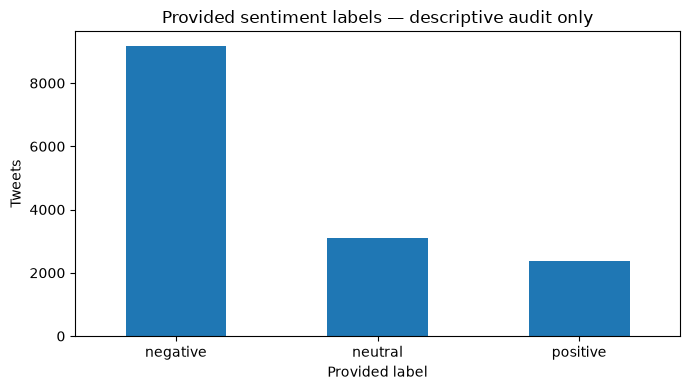

In [9]:
label_counts = df_raw['airline_sentiment'].value_counts(dropna=False)
label_share = (label_counts / len(df_raw) * 100).round(2)
display(pd.DataFrame({'tweets':label_counts,'share_pct':label_share}))
ax=label_counts.plot(kind='bar',title='Provided sentiment labels — descriptive audit only',figsize=(7,4))
ax.set_xlabel('Provided label'); ax.set_ylabel('Tweets');plt.xticks(rotation=0);plt.tight_layout();plt.show()

**Think:** The supplied data are negative-heavy. A clustering solution can score well on *purity* even if all three clusters are mostly negative. Later we'll inspect cluster composition, ARI and NMI, not purity alone.

In [10]:

# STAGE 1A — DUPLICATE AUDIT

import pandas as pd
from pathlib import Path
from IPython.display import display

# Use a raw string (r"...") for Windows paths
file_path = Path(
    r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation\MSI5001\MSI5001_Project\Project Documents\Tweets (1).xlsx"
)

# Verify file exists before loading
if not file_path.is_file():
    raise FileNotFoundError(f"File not found: {file_path}")

# Load dataset
df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# Create audit copy
audit = df.copy()
audit["text_key"] = audit["text"].astype(str).str.strip()

# Count duplicates
exact_duplicates = audit.duplicated(
    subset=[
        "airline_sentiment",
        "sentiment_confidence",
        "text"
    ]
).sum()

text_duplicates = audit.duplicated(
    subset=["text_key"]
).sum()

# Group tweets with identical text
duplicate_groups = (
    audit.groupby("text_key")
    .agg(
        occurrences=("text_key", "size"),
        unique_labels=("airline_sentiment", "nunique"),
        unique_confidences=("sentiment_confidence", "nunique")
    )
)

duplicate_groups = duplicate_groups[
    duplicate_groups["occurrences"] > 1
].sort_values("occurrences", ascending=False)

print("\nDUPLICATE AUDIT SUMMARY")
print("Exact duplicate rows:", exact_duplicates)
print("Repeated text rows:", text_duplicates)
print("Unique repeated-text groups:", len(duplicate_groups))

print(
    "Groups with conflicting labels:",
    (duplicate_groups["unique_labels"] > 1).sum()
)

print(
    "Groups with differing confidence scores:",
    (duplicate_groups["unique_confidences"] > 1).sum()
)

display(duplicate_groups.head(15))

# Examine identical tweets with conflicting labels
conflicts = duplicate_groups[
    duplicate_groups["unique_labels"] > 1
].index

display(
    audit[audit["text_key"].isin(conflicts)]
    [["text", "airline_sentiment", "sentiment_confidence"]]
    .sort_values("text")
    .head(30)
)


Dataset loaded successfully!
Shape: (14639, 3)
Columns: ['airline_sentiment', 'sentiment_confidence', 'text']

DUPLICATE AUDIT SUMMARY
Exact duplicate rows: 99
Repeated text rows: 213
Unique repeated-text groups: 187
Groups with conflicting labels: 25
Groups with differing confidence scores: 98


,occurrences,unique_labels,unique_confidences
text_key,,,
@united thanks,6,2,4
@SouthwestAir sent,5,1,3
@AmericanAir thanks,5,1,3
@JetBlue thanks!,5,1,4
@AmericanAir thank you!,4,1,3
@united thank you!,4,1,3
@USAirways YOU ARE THE BEST!!! FOLLOW ME PLEASE;)🙏🙏🙏✌️✌️✌️🙏🙏🙏,3,1,1
@united Thanks!,3,1,3
@USAirways thanks,3,1,3


,text,airline_sentiment,sentiment_confidence
11961,@AmericanAir - keeping AA up in the Air! My crew chief cousin Alex Espinosa in DFW! http://t.co/0HXLNvZknP,neutral,1.0000
12122,@AmericanAir - keeping AA up in the Air! My crew chief cousin Alex Espinosa in DFW! http://t.co/0HXLNvZknP,positive,0.6710
12129,@AmericanAir @Clarkey_19 we done it with 1 truck... No biggie 😄,positive,1.0000
11968,@AmericanAir @Clarkey_19 we done it with 1 truck... No biggie 😄,neutral,1.0000
11938,"@AmericanAir @RobertDwyer AA doesnt charge any fees to change award tickets as long as the origin, destination &amp; award type remains the same",positive,0.6752
12099,"@AmericanAir @RobertDwyer AA doesnt charge any fees to change award tickets as long as the origin, destination &amp; award type remains the same",neutral,0.6808
12046,"@AmericanAir Believe me, I understand. Flight #2955. Was originally booked for Sunday. Flight was Cancelled Flighted and rescheduled for today.",negative,0.6369
11885,"@AmericanAir Believe me, I understand. Flight #2955. Was originally booked for Sunday. Flight was Cancelled Flighted and rescheduled for today.",positive,0.6604
12079,@AmericanAir I don't think you should help him at all based on his behavior. The voucher and cot seem like enough lol 😃,neutral,0.6709
11918,@AmericanAir I don't think you should help him at all based on his behavior. The voucher and cot seem like enough lol 😃,positive,0.7012


In [11]:

# Create a deduplicated modelling dataset
# Do not use sentiment labels to select records.

df_original = df.copy()

df_original["text_key"] = (
    df_original["text"].astype(str).str.strip()
)

# Keep one occurrence of each identical tweet text
df_unique = (
    df_original
    .drop_duplicates(subset=["text_key"], keep="first")
    .copy()
)

# Preserve original row identifiers for later mapping
df_unique["original_row_id"] = df_unique.index

print("Original rows:", len(df_original))
print("Unique text rows:", len(df_unique))
print("Rows excluded:", len(df_original) - len(df_unique))

# The model will receive text only.
# Sentiment labels and confidence remain separately available.
df_model = df_unique[["original_row_id", "text"]].copy()

display(df_model.head())


Original rows: 14639
Unique text rows: 14426
Rows excluded: 213


,original_row_id,text
0,0,@VirginAmerica What @dhepburn said.
1,1,@VirginAmerica plus you've added commercials to the experience... tacky.
2,2,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse"
4,4,@VirginAmerica and it's a really big bad thing about it


In [12]:

# STAGE 1B: NUMERICAL EXPRESSION AUDIT
# Objective: Identify numerical patterns that may convey sentiment.

import pandas as pd
import re

# Use the original dataset, before removing duplicates
numeric_audit = df.copy()

# Define numerical patterns to investigate
patterns = {
    "fraction_like": r"\b\d{1,3}\s*/\s*\d{1,3}\b",

    "percentage": r"\b\d+(?:\.\d+)?\s*%",

    "out_of_rating": r"\b\d+\s+out\s+of\s+\d+\b",

    "star_rating": r"\b\d+(?:\.\d+)?\s*stars?\b",

    "duration": (
        r"\b\d+(?:\.\d+)?\s*"
        r"(?:hours?|hrs?|minutes?|mins?)\b"
    ),

    "currency": r"\$\s*\d+(?:\.\d+)?"
}

# Count tweets containing each pattern
results = []

for feature, pattern in patterns.items():
    numeric_audit[feature] = (
        numeric_audit["text"]
        .str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
    )

    count = numeric_audit[feature].sum()

    results.append({
        "Feature": feature,
        "Tweets detected": int(count),
        "Percentage (%)": round(count / len(df) * 100, 2)
    })

summary = pd.DataFrame(results)

print("NUMERICAL EXPRESSION SUMMARY")
display(summary)

# Show actual tweets containing each pattern
for feature in patterns.keys():

    print("\n" + "=" * 65)
    print("FEATURE:", feature.upper())
    print("=" * 65)

    examples = numeric_audit.loc[
        numeric_audit[feature], "text"
    ].head(15)

    if len(examples) == 0:
        print("No matching tweets found.")

    else:
        for i, tweet in enumerate(examples, 1):
            print(f"{i}. {tweet}\n")


NUMERICAL EXPRESSION SUMMARY


,Feature,Tweets detected,Percentage (%)
0,fraction_like,196,1.34
1,percentage,25,0.17
2,out_of_rating,3,0.02
3,star_rating,1,0.01
4,duration,1456,9.95
5,currency,287,1.96



FEATURE: FRACTION_LIKE
1. @VirginAmerica plz help me win my bid upgrade for my flight 2/27 LAX---&gt;SEA!!!  🍷👍💺✈️

2. @VirginAmerica Flight 0736 DAL to DCA 2/24 2:10pm. Tried to check in could not. Status please.

3. @VirginAmerica our flight into lga was Cancelled Flighted. We're stuck in Dallas. I called to reschedule, told I could get a flight for today...(1/2)

4. @VirginAmerica my group got their Cancelled Flightlation fees waived but I can't because my ticket is booked for 2/18? Your reps were no help either 😡

5. @united #worst2unitedflightsever UA 236 LAS to IAD 2/24 mechanical problems again - took off - had to land for fix - delayed again #wtfodds!

6. @united #worst2unitedflightsever UA1429 IAD to LAS 2/19 mechanical problems - switched aircraft delayed 3.5 hours!

7. @united to speak to a real person to get this resolved politely and efficiently. (2/2)

8. @united I hadn't filed a refund claim as I was told there was no charge by your DM. This is disputed by my bank, henc

In [13]:

# Stage 1C: Context-aware numerical feature audit

import re
import pandas as pd

duration_pattern = re.compile(
    r"\b\d+(?:\.\d+)?\s*"
    r"(?:hours?|hrs?|minutes?|mins?)\b",
    re.IGNORECASE
)

delay_terms = {
    "delay", "delayed", "late",
    "wait", "waiting", "hold",
    "stuck"
}

def extract_duration_context(text):
    text = str(text)

    matches = list(duration_pattern.finditer(text))

    if not matches:
        return pd.Series({
            "has_duration": 0,
            "has_delay_context": 0,
            "duration_examples": ""
        })

    has_delay_context = 0

    for match in matches:
        # Extract up to 50 characters around the duration
        start = max(0, match.start() - 50)
        end = min(len(text), match.end() + 50)

        context = text[start:end].lower()

        # Check whole-word matches to avoid false positives
        if any(
            re.search(r"\b" + re.escape(term) + r"\b", context)
            for term in delay_terms
        ):
            has_delay_context = 1
            break

    return pd.Series({
        "has_duration": 1,
        "has_delay_context": has_delay_context,
        "duration_examples": ", ".join(
            m.group() for m in matches
        )
    })

# Apply to original tweets
duration_features = df["text"].apply(
    extract_duration_context
)

df_duration = pd.concat(
    [df[["text"]], duration_features],
    axis=1
)

print("Tweets containing durations:",
      df_duration["has_duration"].sum())

print("Tweets containing durations near delay-related terms:",
      df_duration["has_delay_context"].sum())

display(
    df_duration[
        df_duration["has_delay_context"] == 1
    ].head(20)
)


Tweets containing durations: 1456
Tweets containing durations near delay-related terms: 830


,text,has_duration,has_delay_context,duration_examples
66,"@VirginAmerica Hi, Virgin! I'm on hold for 40-50 minutes -- are there any earlier flights from LA to NYC tonight; earlier than 11:50pm?",1,1,50 minutes
121,@VirginAmerica I like the customer service but a 40 min delay just for connecting passengers seems too long. VA370,1,1,40 min
125,@VirginAmerica i need to change my flight thats scheduled in 9 hours and 120 min wait time on phone. Im calling intern. Help!!,1,1,"9 hours, 120 min"
156,@VirginAmerica having problems Flight Booking Problems on the web site. keeps giving me an error and to contact by phone. phone is 30 minute wait.,1,1,30 minute
158,"@VirginAmerica I rang, but there is a wait for 35 minutes!! I can book the same ticket through a vendor, fix your site",1,1,35 minutes
209,@VirginAmerica flight 404 delayed 2 hours in LA due to mechanical problems. Handle like pros but you could have tossed us a free drink.,1,1,2 hours
449,@VirginAmerica I have lots of flights to book and your site it not working!!!! I've been on the phone waiting for over 10 minutes..........,1,1,10 minutes
559,@united A measly $50 e-certificate is not how you appreciate loyal customers after they wait 3hrs on the tarmac during UA1116. #unacceptable,1,1,3hrs
563,@united - Why can't I get a boarding pass for my Austrian Airlines codeshare flight. Rebook incls a 6 hour layover &amp; I am stuck outside sec,1,1,6 hour
574,"@united in addition, my first flight was delayed an hour and I'm arriving at my destination 8 hrs Late Flight.",1,1,8 hrs


## 4 | Text features worth preserving
We are measuring candidate patterns, **not assuming they indicate positive or negative sentiment**. Counts may overlap: a tweet can contain a URL and hashtag.

C:\Users\mxtan\AppData\Local\Temp\ipykernel_30520\4019244154.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  feature_flags[name]=texts.str.contains(pattern,case=False,regex=True)


,tweets,share_pct
Mention,14639,100.00
Negation (selected),4517,30.86
Hashtag,2355,16.09
Contrast (selected),1468,10.03
URL,1173,8.01
Repeated !,605,4.13
Repeated ?,282,1.93
Fraction-like number,199,1.36
Elongated letters,117,0.80
Percentage,25,0.17


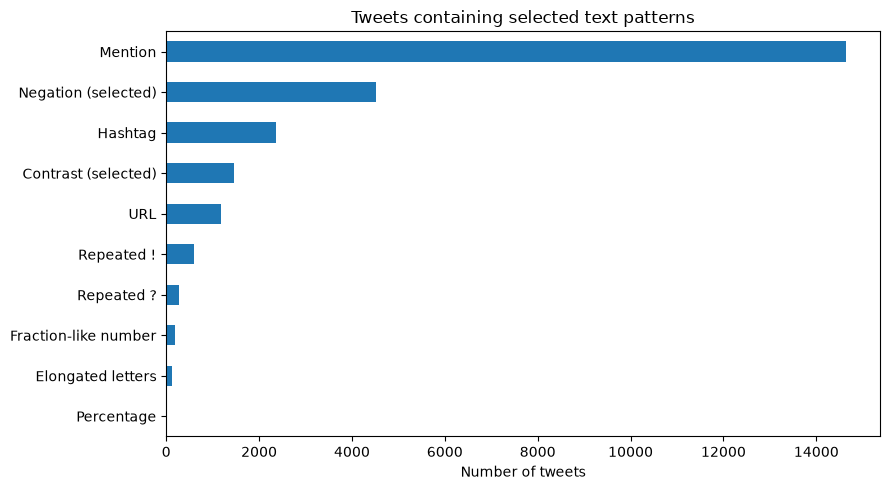

In [14]:
texts = df_raw['text'].fillna('').astype(str)
patterns = {
    'URL':r'https?://\S+|www\.\S+',
    'Hashtag':r'(?<!\w)#[A-Za-z0-9_]+',
    'Mention':r'(?<!\w)@[A-Za-z0-9_]+',
    'Negation (selected)':r"\b(?:not|no|never|nothing|cannot|can't|couldn't|don't|doesn't|didn't|won't|isn't|wasn't)\b",
    'Contrast (selected)':r'\b(?:but|however|although|though|yet)\b',
    'Repeated !':r'!{2,}',
    'Repeated ?':r'\?{2,}',
    'Fraction-like number':r'\b\d+\s*/\s*\d+\b',
    'Percentage':r'\b\d+(?:\.\d+)?\s*%',
    'Elongated letters':r'([A-Za-z])\1{2,}',
}
feature_flags=pd.DataFrame(index=df_raw.index)
for name,pattern in patterns.items():
    feature_flags[name]=texts.str.contains(pattern,case=False,regex=True)
feature_counts=feature_flags.sum().sort_values(ascending=False)
display(pd.DataFrame({'tweets':feature_counts,'share_pct':(100*feature_counts/len(df_raw)).round(2)}))
feature_counts.sort_values().plot(kind='barh',figsize=(9,5),title='Tweets containing selected text patterns')
plt.xlabel('Number of tweets');plt.tight_layout();plt.show()

In [15]:

# STAGE 1D: TEXT ARTEFACT AUDIT

import pandas as pd

artefacts = {
    "Cancelled Flighted": r"\bCancelled Flighted\b",
    "Cancelled Flightlation": r"\bCancelled Flightlation\b",
    "Flight Booking Problems": r"\bFlight Booking Problems\b",
    "Late Flight": r"\bLate Flight\b"
}

results = []

for name, pattern in artefacts.items():
    matches = df["text"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

    results.append({
        "Artefact": name,
        "Tweets detected": int(matches.sum()),
        "Share (%)": round(matches.mean() * 100, 2)
    })

    print(f"\n--- {name} ---")
    for tweet in df.loc[matches, "text"].head(5):
        print(tweet)

artefact_summary = pd.DataFrame(results)

print("\nARTEFACT AUDIT SUMMARY")
display(artefact_summary)



--- Cancelled Flighted ---
@VirginAmerica our flight into lga was Cancelled Flighted. We're stuck in Dallas. I called to reschedule, told I could get a flight for today...(1/2)
@VirginAmerica you stink. Flight Cancelled Flighted from PSP to JFK and no notification or ability to rebook #disappointed.  #expected better
@VirginAmerica You guys charged me $100 to reschedule a flight that was then Cancelled Flighted and are now refusing to refund it. What's the deal?
@united Cancelled Flighted our flight, didn't rebook us on added flight, now have to drive from a Denver to KC....thanks!
@united checking to see why flight 3466 (atl-ord) got Cancelled Flighted?

--- Cancelled Flightlation ---
@VirginAmerica Because we never rec'd Cancelled Flightlation notice we were left w no options to fly out of PS. Driving to LA for a red eye Mon w kids
@VirginAmerica my group got their Cancelled Flightlation fees waived but I can't because my ticket is booked for 2/18? Your reps were no help either 😡
@u

,Artefact,Tweets detected,Share (%)
0,Cancelled Flighted,217,1.48
1,Cancelled Flightlation,34,0.23
2,Flight Booking Problems,88,0.60
3,Late Flight,238,1.63


Notebook section	Purpose	Status
Section 1–3	Dataset loading, quality checks and sentiment distribution	Completed
Section 3A	Duplicate audit	Completed
Section 3B	Numerical expression audit	Completed
Section 3C	Context-aware duration detection	Completed
Section 4	Language-pattern frequency analysis	Completed
Section 4A (new)	Text Artefact Audit	Run next
Section 5	Representative tweet inspection	Completed

**Caution:** `8/10` may mean a rating, date, or flight frequency. `100%` may express certainty rather than satisfaction. Regex flags are **candidate matches**, not verified interpretations.

## 5 | Review actual examples without choosing rules from labels
Below, sample tweets are selected **only using text patterns**. We deliberately do not show sentiment labels alongside them. This keeps our EDA focused on linguistic phenomena.

In [16]:
for name in ['Negation (selected)','Contrast (selected)','Fraction-like number','Elongated letters']:
    print('\n###',name)
    examples = texts.loc[feature_flags[name]].head(5)
    for ix,t in examples.items():print(f'{ix}: {t[:240]}')


### Negation (selected)
2: @VirginAmerica I didn't today... Must mean I need to take another trip!
5: @VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.
it's really the only bad thing about flying VA
8: @virginamerica Well, I didn't…but NOW I DO! :-D
16: @VirginAmerica So excited for my first cross country flight LAX to MCO I've heard nothing but great things about Virgin America. #29DaysToGo
17: @VirginAmerica  I flew from NYC to SFO last week and couldn't fully sit in my seat due to two large gentleman on either side of me. HELP!

### Contrast (selected)
8: @virginamerica Well, I didn't…but NOW I DO! :-D
12: @VirginAmerica This is such a great deal! Already thinking about my 2nd trip to @Australia &amp; I haven't even gone on my 1st trip yet! ;p
16: @VirginAmerica So excited for my first cross country flight LAX to MCO I've heard nothing but great things about Virgin America. #29DaysToGo
29: @VirginAmerica hi! I just bked a cool birthday trip wi

**Discuss:** Find examples where `not`, `never` or `but` cannot be interpreted by a simple keyword rule. Record 2–3 examples to discuss with the team. Don't claim these are representative until we quantify them.

## 6 | Airline identity: metadata, not a sentiment signal
The spreadsheet has no explicit airline column. We can extract **candidate** airline handles for later business analysis. Some tweets mention more than one airline or use variant names. We keep unknown/multiple cases explicit and do not put the airline ID into the primary sentiment-clustering input.

In [17]:
airline_handles={
 'Virgin America':r'@virginamerica\b',
 'United':r'@united\b',
 'Southwest':r'@southwestair\b',
 'Delta':r'@delta\b',
 'US Airways':r'@usairways\b',
 'American':r'@americanair\b',
}
def airline_candidate(t):
    hits=[name for name,pat in airline_handles.items() if re.search(pat,t,re.I)]
    return hits[0] if len(hits)==1 else ('Multiple' if hits else 'Unknown')
airline_candidate_col=texts.apply(airline_candidate)
display(airline_candidate_col.value_counts().to_frame('tweets'))
print('WARNING: This is handle-based extraction, not a validated airline ground truth.')

,tweets
text,
United,3769
US Airways,2733
American,2669
Southwest,2386
Unknown,2203
Virgin America,497
Multiple,380
Delta,2


**Important:** Airline ranking must account for the number of tweets per airline, ambiguity of airline attribution, dataset sampling bias, and cluster-to-sentiment alignment. A count of negative tweets alone rewards/disadvantages airlines with different tweet volumes.

## 7 | Create a minimally transformed working copy
We preserve the original text and extract candidate metadata. For now, we **do not** strip negation, emojis, punctuation or hashtags. Preprocessing is an experiment in Stage 2, not a foregone conclusion.

In [18]:
work = pd.DataFrame({
    'tweet_id':np.arange(len(df_raw)),
    'text_original':texts,
    'text_minimal':texts.str.replace(r'https?://\S+|www\.\S+',' URL ',regex=True).str.replace(r'\s+',' ',regex=True).str.strip(),
    'airline_candidate':airline_candidate_col,
})
# Labels kept separately and will NOT be joined to model inputs.
labels_held_out=df_raw[['airline_sentiment','sentiment_confidence']].copy()
labels_held_out.index=work['tweet_id']
assert 'airline_sentiment' not in work.columns
assert 'sentiment_confidence' not in work.columns
display(work.head(5))
print('Working data shape:',work.shape)

,tweet_id,text_original,text_minimal,airline_candidate
0,0,@VirginAmerica What @dhepburn said.,@VirginAmerica What @dhepburn said.,Virgin America
1,1,@VirginAmerica plus you've added commercials to the experience... tacky.,@VirginAmerica plus you've added commercials to the experience... tacky.,Virgin America
2,2,@VirginAmerica I didn't today... Must mean I need to take another trip!,@VirginAmerica I didn't today... Must mean I need to take another trip!,Virgin America
3,3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse","@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",Virgin America
4,4,@VirginAmerica and it's a really big bad thing about it,@VirginAmerica and it's a really big bad thing about it,Virgin America


Working data shape: (14639, 4)


In [19]:

# Find all pandas DataFrames currently in memory

import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(
            f"{name}: {obj.shape} | "
            f"Columns: {obj.columns.tolist()}"
        )


df_raw: (14639, 3) | Columns: ['airline_sentiment', 'sentiment_confidence', 'text']
df: (14639, 3) | Columns: ['airline_sentiment', 'sentiment_confidence', 'text']
audit: (14639, 4) | Columns: ['airline_sentiment', 'sentiment_confidence', 'text', 'text_key']
duplicate_groups: (187, 3) | Columns: ['occurrences', 'unique_labels', 'unique_confidences']
df_original: (14639, 4) | Columns: ['airline_sentiment', 'sentiment_confidence', 'text', 'text_key']
df_unique: (14426, 5) | Columns: ['airline_sentiment', 'sentiment_confidence', 'text', 'text_key', 'original_row_id']
df_model: (14426, 2) | Columns: ['original_row_id', 'text']
numeric_audit: (14639, 9) | Columns: ['airline_sentiment', 'sentiment_confidence', 'text', 'fraction_like', 'percentage', 'out_of_rating', 'star_rating', 'duration', 'currency']
summary: (6, 3) | Columns: ['Feature', 'Tweets detected', 'Percentage (%)']
duration_features: (14639, 3) | Columns: ['has_duration', 'has_delay_context', 'duration_examples']
df_duration: (1

In [20]:

# STAGE 2A — PREPARE MODELLING DATASET
# Locate the Section 7 DataFrame automatically.

required_columns = {
    "tweet_id",
    "text_original",
    "text_minimal",
    "airline_candidate"
}

candidates = [
    (name, obj)
    for name, obj in list(globals().items())
    if isinstance(obj, pd.DataFrame)
    and required_columns.issubset(obj.columns)
]

print("Matching DataFrames:",
      [name for name, _ in candidates])

if len(candidates) != 1:
    raise ValueError(
        "Expected exactly one matching DataFrame. "
        "Check the variable names printed above."
    )

source_name, source_df = candidates[0]
print("Using:", source_name)

df_stage2 = source_df.copy()

# Create a text key without using sentiment labels.
df_stage2["text_key"] = (
    df_stage2["text_original"]
    .astype(str)
    .str.strip()
)

# Retain one record per unique original tweet.
df_stage2 = df_stage2.drop_duplicates(
    subset=["text_key"],
    keep="first"
).copy()

print("\nOriginal rows:", len(source_df))
print("Modelling rows:", len(df_stage2))
print("Repeated-text rows excluded:",
      len(source_df) - len(df_stage2))

display(df_stage2.head())


Matching DataFrames: ['work']
Using: work

Original rows: 14639
Modelling rows: 14426
Repeated-text rows excluded: 213


,tweet_id,text_original,text_minimal,airline_candidate,text_key
0,0,@VirginAmerica What @dhepburn said.,@VirginAmerica What @dhepburn said.,Virgin America,@VirginAmerica What @dhepburn said.
1,1,@VirginAmerica plus you've added commercials to the experience... tacky.,@VirginAmerica plus you've added commercials to the experience... tacky.,Virgin America,@VirginAmerica plus you've added commercials to the experience... tacky.
2,2,@VirginAmerica I didn't today... Must mean I need to take another trip!,@VirginAmerica I didn't today... Must mean I need to take another trip!,Virgin America,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse","@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",Virgin America,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse"
4,4,@VirginAmerica and it's a really big bad thing about it,@VirginAmerica and it's a really big bad thing about it,Virgin America,@VirginAmerica and it's a really big bad thing about it


In [21]:

# STAGE 2B — MINIMAL TEXT CLEANING

import re
import html

airline_names = re.compile(
    r"\b(?:Virgin\s*America|American\s+Airlines|"
    r"US\s*Airways|Southwest\s+Airlines|"
    r"United\s+Airlines|JetBlue|SouthwestAir)\b",
    flags=re.IGNORECASE
)

airline_handles = re.compile(
    r"@(?:VirginAmerica|AmericanAir|USAirways|"
    r"SouthwestAir|United|JetBlue)\b",
    flags=re.IGNORECASE
)

def clean_minimal(text):
    text = html.unescape(str(text))

    # Mask URLs before other text processing
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " URL ",
        text
    )

    # Mask recognised airline handles
    text = airline_handles.sub(" AIRLINE ", text)

    # Mask remaining Twitter mentions
    text = re.sub(r"@\w+", " USER ", text)

    # Mask explicit airline names
    text = airline_names.sub(" AIRLINE ", text)

    # Normalise whitespace only
    text = re.sub(r"\s+", " ", text).strip()

    return text

df_stage2["clean_text"] = (
    df_stage2["text_original"].apply(clean_minimal)
)

print("Rows:", len(df_stage2))
print("Empty cleaned tweets:",
      df_stage2["clean_text"].eq("").sum())

display(
    df_stage2[["text_original", "clean_text"]].head(10)
)


Rows: 14426
Empty cleaned tweets: 0


,text_original,clean_text
0,@VirginAmerica What @dhepburn said.,AIRLINE What USER said.
1,@VirginAmerica plus you've added commercials to the experience... tacky.,AIRLINE plus you've added commercials to the experience... tacky.
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,AIRLINE I didn't today... Must mean I need to take another trip!
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse","AIRLINE it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse"
4,@VirginAmerica and it's a really big bad thing about it,AIRLINE and it's a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,AIRLINE seriously would pay $30 a flight for seats that didn't have this playing. it's really the only bad thing about flying VA
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)","AIRLINE yes, nearly every time I fly VX this “ear worm” won’t go away :)"
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP","AIRLINE Really missed a prime opportunity for Men Without Hats parody, there. URL"
8,"@virginamerica Well, I didn't…but NOW I DO! :-D","AIRLINE Well, I didn't…but NOW I DO! :-D"
9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.","AIRLINE it was amazing, and arrived an hour early. You're too good to me."


## 8 | Export Stage 1 audit files
`stage1_working_text.csv` contains no sentiment labels. `stage1_audit_summary.csv` contains aggregate pattern counts. The original XLSX stays untouched.

In [22]:
work.to_csv('stage1_working_text.csv',index=False)
audit_summary=pd.DataFrame({'feature':feature_counts.index,'tweets':feature_counts.values,'share_pct':(feature_counts.values/len(df_raw)*100).round(2)})
audit_summary.to_csv('stage1_audit_summary.csv',index=False)
print('Saved stage1_working_text.csv and stage1_audit_summary.csv')
# Uncomment when you want to download:
# files.download('stage1_working_text.csv')
# files.download('stage1_audit_summary.csv')

Saved stage1_working_text.csv and stage1_audit_summary.csv


In [23]:

# SAVE STAGE 2 PREPROCESSED DATASET

output_file = "MSI5001_stage2_minimal_cleaned.csv"

df_stage2.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", output_file)
print("Rows:", len(df_stage2))
print("Columns:", df_stage2.columns.tolist())


Saved: MSI5001_stage2_minimal_cleaned.csv
Rows: 14426
Columns: ['tweet_id', 'text_original', 'text_minimal', 'airline_candidate', 'text_key', 'clean_text']


## 9 | Preview evaluation maths (toy data — not actual model results)
These calculations are included so the evaluation vocabulary is not mysterious. We'll repeat them on real cluster assignments in Stage 4/5.

- **Silhouette:** for each point, compare average within-cluster distance `a` and nearest-other-cluster average distance `b`: `(b-a)/max(a,b)`; average over points. Values range from -1 to 1.
- **Stability:** compare cluster assignments from multiple seeds using ARI **between two clusterings**, without any sentiment labels.
- **Purity:** sum the most common true sentiment count in each cluster, divided by total tweets.
- **ARI:** chance-adjusted similarity between two partitions; can be negative, with 1 indicating identical partitions.
- **NMI:** normalised shared information between cluster and true sentiment assignments; ranges from 0 to 1.
- **Composition:** percentage breakdown of true sentiments inside each cluster.

**Rule:** external metrics are for post-hoc evaluation only; they must not drive selection/tuning of an unsupervised pipeline.

Internal silhouette: 0.746
Stability ARI (seed 1 vs seed 2; no labels): 1.0
Post-hoc ARI (toy ground truth): 1.0
Post-hoc NMI (toy ground truth): 1.0


toy_truth,0,1,2
cluster,,,
0,50,0,0
1,0,50,0
2,0,0,50


Post-hoc purity: 1.0
Cluster composition (% within each cluster):


toy_truth,0,1,2
cluster,,,
0,100.0,0.0,0.0
1,0.0,100.0,0.0
2,0.0,0.0,100.0


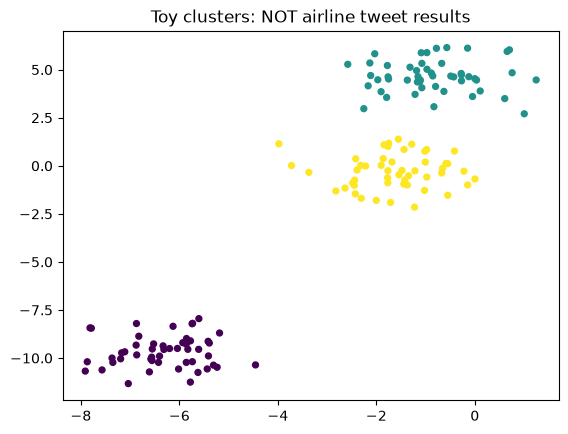

In [24]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
X_toy, true_toy = make_blobs(n_samples=150,centers=3,cluster_std=0.9,random_state=11)
km_a=KMeans(n_clusters=3,n_init=10,random_state=1).fit(X_toy)
km_b=KMeans(n_clusters=3,n_init=10,random_state=2).fit(X_toy)
cluster_a=km_a.labels_; cluster_b=km_b.labels_
print('Internal silhouette:',round(silhouette_score(X_toy,cluster_a),3))
print('Stability ARI (seed 1 vs seed 2; no labels):',round(adjusted_rand_score(cluster_a,cluster_b),3))
print('Post-hoc ARI (toy ground truth):',round(adjusted_rand_score(true_toy,cluster_a),3))
print('Post-hoc NMI (toy ground truth):',round(normalized_mutual_info_score(true_toy,cluster_a),3))
ct=pd.crosstab(pd.Series(cluster_a,name='cluster'),pd.Series(true_toy,name='toy_truth'))
display(ct)
purity=ct.max(axis=1).sum()/ct.values.sum()
print('Post-hoc purity:',round(purity,3))
print('Cluster composition (% within each cluster):')
display((ct.div(ct.sum(axis=1),axis=0)*100).round(1))
plt.scatter(X_toy[:,0],X_toy[:,1],c=cluster_a,s=18)
plt.title('Toy clusters: NOT airline tweet results');plt.show()

## 10 | Reflection and checkpoint
Before Stage 2, write short answers:
1. Why are sentiment labels unavailable to the clustering model?
2. Why should we retain `text_original`?
3. Give one reason not to remove `not`, `never`, emojis or punctuation indiscriminately.
4. What is the difference between internal silhouette and post-hoc purity?
5. What could make an airline ranking misleading?

**Next stage:** controlled cleaning variants; tokenisation; TF-IDF (unigrams/bigrams); basic K-Means. We will then compare with VADER and embeddings as separate experiments.

**Academic integrity:** declare AI assistance in the project report and retain relevant chat history, per the project handout.

# STAGE 3 — NLP REPRESENTATION
## Experiment E0: TF-IDF Unigrams
Objective: Establish a label-free lexical baseline
before testing bigrams and other NLP representations.

Step 3A — Verify our modelling dataset

In [25]:

# STAGE 3A — VERIFY INPUT DATA

import pandas as pd
import numpy as np

# Check that Stage 2 was executed
assert "df_stage2" in globals(), (
    "df_stage2 not found. Run Stage 2A and 2B first."
)

assert "clean_text" in df_stage2.columns, (
    "Cleaned text missing. Run Stage 2B first."
)

assert len(df_stage2) == 14426, (
    "Unexpected number of modelling rows."
)

assert df_stage2["clean_text"].notna().all()

# Create our modelling input
texts = df_stage2["clean_text"].astype(str).reset_index(drop=True)

print("Modelling tweets:", len(texts))
print("Empty tweets:", texts.str.strip().eq("").sum())
print("Unique original tweet IDs:",
      df_stage2["tweet_id"].nunique())

print("\nFirst three cleaned tweets:")
for tweet in texts.head(3):
    print("-", tweet)


Modelling tweets: 14426
Empty tweets: 0
Unique original tweet IDs: 14426

First three cleaned tweets:
- AIRLINE What USER said.
- AIRLINE plus you've added commercials to the experience... tacky.
- AIRLINE I didn't today... Must mean I need to take another trip!


#Step 3B — Understand tokenisation
Before TF-IDF calculates any weights, it needs to identify words.

Run this demonstration:

In [26]:

# STAGE 3B — TOKENISATION DEMONSTRATION

from sklearn.feature_extraction.text import TfidfVectorizer

sample = "AIRLINE The flight was NOT good!!! 😡"

demo_vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w\w+\b"
)

tokens = demo_vectorizer.build_analyzer()(sample)

print("Original:", sample)
print("Tokens:", tokens)


Original: AIRLINE The flight was NOT good!!! 😡
Tokens: ['airline', 'the', 'flight', 'was', 'not', 'good']


In [27]:

!pip -q install emoji



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:

# STAGE 3B-1: EMOJI TOKENISATION DEMONSTRATION

import emoji
from sklearn.feature_extraction.text import TfidfVectorizer

sample = "AIRLINE Amazing service 😍✈️ but delayed 😡"

# Original TF-IDF tokenisation
vectorizer = TfidfVectorizer(lowercase=True)

original_tokens = vectorizer.build_analyzer()(sample)

# Convert emojis into descriptive text
emoji_text = emoji.demojize(
    sample,
    delimiters=(" ", " ")
)

# Replace underscores with spaces for readable tokens
emoji_text = emoji_text.replace("_", " ")

converted_tokens = vectorizer.build_analyzer()(emoji_text)

print("Original tweet:")
print(sample)

print("\nTokens without emoji conversion:")
print(original_tokens)

print("\nTweet after emoji conversion:")
print(emoji_text)

print("\nTokens after emoji conversion:")
print(converted_tokens)


Original tweet:
AIRLINE Amazing service 😍✈️ but delayed 😡

Tokens without emoji conversion:
['airline', 'amazing', 'service', 'but', 'delayed']

Tweet after emoji conversion:
AIRLINE Amazing service  smiling face with heart-eyes  airplane  but delayed  enraged face 

Tokens after emoji conversion:
['airline', 'amazing', 'service', 'smiling', 'face', 'with', 'heart', 'eyes', 'airplane', 'but', 'delayed', 'enraged', 'face']


# Stage 3C — E0: TF-IDF Unigram Vectorisation

Step 3C — Generate TF-IDF vectors

In [29]:

# STAGE 3C — EXPERIMENT E0: TF-IDF UNIGRAMS

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Confirm our Stage 2 dataset is available
assert "df_stage2" in globals(), "Run Stage 2 first."
assert "clean_text" in df_stage2.columns

# Prepare text input
texts = (
    df_stage2["clean_text"]
    .fillna("")
    .astype(str)
    .reset_index(drop=True)
)

# Configure TF-IDF
tfidf_e0 = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    norm="l2",
    stop_words=None
)

# Fit vocabulary and transform tweets
X_e0 = tfidf_e0.fit_transform(texts)

# Inspect feature coverage
active_features = np.asarray(
    (X_e0 != 0).sum(axis=1)
).ravel()

print("Tweets:", X_e0.shape[0])
print("Vocabulary features:", X_e0.shape[1])
print("Non-zero matrix entries:", X_e0.nnz)
print("Average active features per tweet:",
      round(active_features.mean(), 2))
print("Zero-feature tweets:",
      int((active_features == 0).sum()))


Tweets: 14426
Vocabulary features: 6121
Non-zero matrix entries: 206336
Average active features per tweet: 14.3
Zero-feature tweets: 16


#Stage 3D: Inspect TF-IDF weights
Once Stage 3C runs successfully, insert a new code cell:

In [30]:

# STAGE 3D — INSPECT TF-IDF UNIGRAM WEIGHTS

import numpy as np

feature_names = tfidf_e0.get_feature_names_out()

for i in range(5):
    row = X_e0.getrow(i)

    order = np.argsort(row.data)[::-1][:8]

    top_terms = [
        (
            feature_names[row.indices[j]],
            round(float(row.data[j]), 4)
        )
        for j in order
    ]

    print(f"\nTweet {i}:")
    print(texts.iloc[i])
    print("Top weighted terms:", top_terms)



Tweet 0:
AIRLINE What USER said.
Top weighted terms: [('said', 0.7195), ('what', 0.5181), ('user', 0.4624)]

Tweet 1:
AIRLINE plus you've added commercials to the experience... tacky.
Top weighted terms: [('commercials', 0.5632), ('added', 0.4915), ('plus', 0.4252), ('experience', 0.3448), ('ve', 0.2898), ('you', 0.1553), ('the', 0.138), ('to', 0.1198)]

Tweet 2:
AIRLINE I didn't today... Must mean I need to take another trip!
Top weighted terms: [('must', 0.4499), ('mean', 0.4232), ('didn', 0.341), ('trip', 0.3394), ('take', 0.324), ('another', 0.3235), ('today', 0.2935), ('need', 0.2779)]

Tweet 3:
AIRLINE it's really aggressive to blast obnoxious "entertainment" in your guests' faces & they have little recourse
Top weighted terms: [('obnoxious', 0.3631), ('blast', 0.3631), ('faces', 0.3521), ('aggressive', 0.3521), ('guests', 0.3435), ('recourse', 0.3365), ('entertainment', 0.2804), ('little', 0.2447)]

Tweet 4:
AIRLINE and it's a really big bad thing about it
Top weighted terms: [

#Stage 3E — Vocabulary audit

In [31]:

# STAGE 3E — TF-IDF VOCABULARY AUDIT

import pandas as pd

terms = tfidf_e0.get_feature_names_out()

document_frequency = np.asarray(
    (X_e0 > 0).sum(axis=0)
).ravel()

vocab_audit = pd.DataFrame({
    "term": terms,
    "tweets_containing_term": document_frequency
})

print("Top 20 most widely occurring represented terms:")
display(
    vocab_audit.sort_values(
        "tweets_containing_term",
        ascending=False
    ).head(20)
)

print("\nPlaceholder and negation checks:")

for term in ["airline", "user", "url", "not", "never"]:
    if term in tfidf_e0.vocabulary_:
        idx = tfidf_e0.vocabulary_[term]
        print(
            term, ":",
            document_frequency[idx],
            "tweets"
        )
    else:
        print(term, ": not in vocabulary")


Top 20 most widely occurring represented terms:


,term,tweets_containing_term
5549,to,6257
5465,the,4732
6094,you,3628
2495,for,3560
3906,on,3378
2434,flight,3340
694,and,3295
3723,my,2789
3130,is,2542
2999,in,2323



Placeholder and negation checks:
airline : not in vocabulary
user : 1205 tweets
url : 1163 tweets
not : 1469 tweets
never : 312 tweets


#Stage 3F — Inspect zero-feature tweets

In [32]:

# STAGE 3F — INSPECT ZERO-FEATURE TWEETS

import numpy as np
import pandas as pd

zero_indices = np.where(active_features == 0)[0]

zero_tweets = pd.DataFrame({
    "tweet_id": df_stage2["tweet_id"].to_numpy()[zero_indices],
    "original_text": df_stage2["text_original"].to_numpy()[zero_indices],
    "clean_text": texts.iloc[zero_indices].to_numpy()
})

print("Zero-feature tweets:", len(zero_tweets))

display(zero_tweets)


Zero-feature tweets: 16


,tweet_id,original_text,clean_text
0,240,@virginamerica spruce moose!,AIRLINE spruce moose!
1,1105,@united noooooooooooooooooooooope.,AIRLINE noooooooooooooooooooooope.
2,1915,@united I6EP18,AIRLINE I6EP18
3,2099,"@united Freakin""","AIRLINE Freakin"""
4,2185,@united U blow,AIRLINE U blow
5,4110,@united Classic,AIRLINE Classic
6,4879,@SouthwestAir gimme,AIRLINE gimme
7,6515,@SouthwestAir Awwweesssooomee!,AIRLINE Awwweesssooomee!
8,6678,@SouthwestAir F5R3ZZ,AIRLINE F5R3ZZ
9,7192,@JetBlue Gerne :),AIRLINE Gerne :)


#Step 4A — Fit K-Means

In [33]:

# STAGE 4A — E0: K-MEANS CLUSTERING

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# Confirm TF-IDF output exists
assert X_e0.shape[0] == len(texts)
assert X_e0.shape[0] == len(df_stage2)

# Configure K-Means
kmeans_e0 = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=42
)

# Fit the model and assign each tweet to a cluster
clusters_e0 = kmeans_e0.fit_predict(X_e0)

# Store results without changing the original data
results_e0 = df_stage2[
    ["tweet_id", "text_original", "clean_text"]
].copy().reset_index(drop=True)

results_e0["cluster"] = clusters_e0

print("K-Means clustering completed!")
print("Number of clusters:", len(np.unique(clusters_e0)))
print("Iterations to convergence:", kmeans_e0.n_iter_)
print("Inertia:", round(kmeans_e0.inertia_, 4))

print("\nCluster sizes:")
cluster_sizes = (
    results_e0["cluster"]
    .value_counts()
    .sort_index()
)

display(pd.DataFrame({
    "tweets": cluster_sizes,
    "share_pct": (cluster_sizes / len(results_e0) * 100).round(2)
}))

assert len(results_e0) == 14426
assert results_e0["cluster"].notna().all()


K-Means clustering completed!
Number of clusters: 3
Iterations to convergence: 50
Inertia: 13894.8246

Cluster sizes:


,tweets,share_pct
cluster,,
0,9995,69.28
1,3869,26.82
2,562,3.90


#Step 4B — Inspect what the clusters contain

In [34]:

# STAGE 4B — CLUSTER INTERPRETATION

from sklearn.metrics import pairwise_distances

distances = pairwise_distances(
    X_e0,
    kmeans_e0.cluster_centers_,
    metric="euclidean"
)

rng = np.random.default_rng(42)

for cluster in range(3):

    print("\n" + "=" * 65)
    print(f"CLUSTER {cluster}")
    print("=" * 65)

    indices = np.where(clusters_e0 == cluster)[0]

    # Nearest to centroid
    nearest = indices[
        np.argsort(distances[indices, cluster])[:5]
    ]

    print("\n5 CENTROID-NEAREST TWEETS:")
    for idx in nearest:
        print("-", results_e0.iloc[idx]["text_original"])

    # Random sample from the cluster
    sample_size = min(5, len(indices))

    sampled = rng.choice(
        indices,
        size=sample_size,
        replace=False
    )

    print("\n5 RANDOMLY SAMPLED TWEETS:")
    for idx in sampled:
        print("-", results_e0.iloc[idx]["text_original"])



CLUSTER 0

5 CENTROID-NEAREST TWEETS:
- @JetBlue flite454
- @AmericanAir amen!
- @united Classic
- @united Freakin"
- @AmericanAir American Airlines.

5 RANDOMLY SAMPLED TWEETS:
- @USAirways thanks! Made it safely! http://t.co/KCqeBEej7S
- @SouthwestAir heard you are saving 30k a year on fuel not carrying around those skymall's #ripskymall
- @USAirways  Instead, the miles are credited to an account that i did not open
-- My request to merge the accounts is denied
- @united would love help getting there today. In #EWR now. Will take any airline and connections. Thx
- @SouthwestAir would you be willing to help me surprise my bestfriend with tickets to go see @Imaginedragons? #DestinationDragons Gracias!

CLUSTER 1

5 CENTROID-NEAREST TWEETS:
- @SouthwestAir been on hold for an hour. I need to rebook my flight that was Cancelled Flighted! #help
- @JetBlue flight 2008
- @united flight 5431
- @united Flight 280
- @SouthwestAir flight # 317

5 RANDOMLY SAMPLED TWEETS:
- @AmericanAir most ho

#Step 4C — Identify prominent vocabulary by cluster

In [35]:

# STAGE 4C — TOP TF-IDF TERMS PER CLUSTER

terms = tfidf_e0.get_feature_names_out()

for cluster in range(3):

    centroid = kmeans_e0.cluster_centers_[cluster]

    top_indices = np.argsort(
        centroid
    )[::-1][:15]

    print(f"\nCLUSTER {cluster} — TOP TERMS")

    for idx in top_indices:
        print(
            f"{terms[idx]:20s}",
            round(float(centroid[idx]), 4)
        )



CLUSTER 0 — TOP TERMS
to                   0.0417
the                  0.0403
you                  0.0357
and                  0.027
is                   0.0258
for                  0.0248
it                   0.0247
in                   0.0237
thanks               0.0221
user                 0.0214
your                 0.0209
of                   0.0206
my                   0.0204
me                   0.0197
that                 0.0193

CLUSTER 1 — TOP TERMS
flight               0.1044
on                   0.0627
to                   0.0619
my                   0.047
for                  0.0466
cancelled            0.0423
the                  0.0395
and                  0.0351
hold                 0.0296
is                   0.0281
was                  0.028
flightled            0.0272
been                 0.0257
get                  0.024
hours                0.0234

CLUSTER 2 — TOP TERMS
thank                0.2822
you                  0.1757
fleek                0.1158
fleet      

#Stage 4D — Centroid geometry and zero-vector audit

In [36]:

# STAGE 4D — INVESTIGATE CENTROID GEOMETRY

import numpy as np
import pandas as pd

# Calculate centroid norms
centroid_norms = np.linalg.norm(
    kmeans_e0.cluster_centers_,
    axis=1
)

# Identify zero-feature tweets
row_norms = np.sqrt(
    X_e0.multiply(X_e0).sum(axis=1)
).A1

zero_mask = row_norms == 0

print("CENTROID NORMS")
for k, norm in enumerate(centroid_norms):
    print(f"Cluster {k}: {norm:.6f}")

print("\nZERO-FEATURE TWEET ASSIGNMENTS")

zero_audit = results_e0.loc[
    zero_mask,
    ["tweet_id", "text_original", "cluster"]
].copy()

display(zero_audit)

print("\nZero-feature tweets per cluster:")
display(
    zero_audit["cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster centroid distance summary:")

from sklearn.metrics import pairwise_distances

D = pairwise_distances(
    X_e0,
    kmeans_e0.cluster_centers_,
    metric="euclidean"
)

for k in range(3):
    indices = np.where(clusters_e0 == k)[0]

    print(
        f"Cluster {k}: "
        f"min={D[indices, k].min():.4f}, "
        f"median={np.median(D[indices, k]):.4f}, "
        f"max={D[indices, k].max():.4f}"
    )


CENTROID NORMS
Cluster 0: 0.149873
Cluster 1: 0.225626
Cluster 2: 0.408339

ZERO-FEATURE TWEET ASSIGNMENTS


,tweet_id,text_original,cluster
240,240,@virginamerica spruce moose!,0
1103,1105,@united noooooooooooooooooooooope.,0
1911,1915,@united I6EP18,0
2093,2099,"@united Freakin""",0
2179,2185,@united U blow,0
4094,4110,@united Classic,0
4860,4879,@SouthwestAir gimme,0
6486,6515,@SouthwestAir Awwweesssooomee!,0
6649,6678,@SouthwestAir F5R3ZZ,0
7162,7192,@JetBlue Gerne :),0



Zero-feature tweets per cluster:


cluster
0    16
Name: count, dtype: int64


Cluster centroid distance summary:
Cluster 0: min=0.1499, median=0.9887, max=1.0111
Cluster 1: min=0.9099, median=0.9758, max=1.0039
Cluster 2: min=0.7089, median=0.9282, max=1.0019


#Stage 4E — Representative tweets excluding zero vectors

In [37]:

# STAGE 4E — IMPROVED REPRESENTATIVE TWEET INSPECTION

import numpy as np
from sklearn.metrics import pairwise_distances

# Use the existing fitted E0 model.
# Do not refit or change cluster assignments.

row_norms = np.sqrt(
    X_e0.multiply(X_e0).sum(axis=1)
).A1

D = pairwise_distances(
    X_e0,
    kmeans_e0.cluster_centers_,
    metric="euclidean"
)

for k in range(3):

    indices = np.where(
        (clusters_e0 == k) &
        (row_norms > 0)
    )[0]

    nearest = indices[
        np.argsort(D[indices, k])[:8]
    ]

    print("\n" + "=" * 65)
    print(f"CLUSTER {k} — NEAREST NONZERO TWEETS")
    print("=" * 65)

    for idx in nearest:
        print(
            f"Distance={D[idx, k]:.4f} | "
            f"{results_e0.iloc[idx]['text_original']}"
        )



CLUSTER 0 — NEAREST NONZERO TWEETS
Distance=0.9498 | @AmericanAir Thanks for doing that but now it's telling me to go to the airport and check in with an agent-what's up? http://t.co/PfseNJk5Pw
Distance=0.9547 | @SouthwestAir When are you going to be flying in and out of Nashville? The Deicer is in. Are you short on planes and is it tomorrow morning?
Distance=0.9571 | @JetBlue I'm not sure if you can do anything to help me with that, but if you can that'd be great.
Distance=0.9580 | @SouthwestAir, you're really going to let @delta and @virginamerica get the best of you? http://t.co/vUdWJm1lYB
Distance=0.9594 | @JetBlue thanks for help. Can't wait to travel with! And get out of the snow.
Distance=0.9597 | @USAirways your lack of customer service has shined. I need you to step up and get my lost baggage to delta. So they can return it to me.
Distance=0.9597 | @SouthwestAir looks like you are up and running for the day. Still can't get through on the phone. Can you follow so I can dm you

#Stage 5A: Internal clustering evaluation

In [38]:

# STAGE 5A — INTERNAL EVALUATION: SILHOUETTE

import numpy as np
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)

sample_size = 2000

# Stratified sampling by discovered cluster,
# without using sentiment labels.
sample_indices = []

for k in range(3):
    idx = np.where(clusters_e0 == k)[0]

    n_k = max(
        2,
        round(sample_size * len(idx) / len(clusters_e0))
    )

    selected = rng.choice(
        idx,
        size=min(n_k, len(idx)),
        replace=False
    )

    sample_indices.extend(selected)

sample_indices = np.array(sample_indices)

X_sample = X_e0[sample_indices]
labels_sample = clusters_e0[sample_indices]

score = silhouette_score(
    X_sample,
    labels_sample,
    metric="euclidean"
)

print("Sampled tweets:", len(sample_indices))
print("Silhouette Score:", round(score, 6))


Sampled tweets: 2000
Silhouette Score: 0.004358


#Stage 5B: Stability evaluation - Stability across random seeds

In [39]:

# STAGE 5B — K-MEANS STABILITY ACROSS SEEDS

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

seeds = [42, 101, 202, 303, 404]

cluster_runs = {}

for seed in seeds:

    model = KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        max_iter=300,
        random_state=seed
    )

    assignments = model.fit_predict(X_e0)

    cluster_runs[seed] = assignments

    print(
        f"Seed {seed}: "
        f"Inertia={model.inertia_:.4f}, "
        f"Sizes={np.bincount(assignments)}"
    )

# Pairwise ARI between runs
stability_results = []

for seed_a, seed_b in combinations(seeds, 2):

    ari = adjusted_rand_score(
        cluster_runs[seed_a],
        cluster_runs[seed_b]
    )

    stability_results.append({
        "seed_a": seed_a,
        "seed_b": seed_b,
        "stability_ari": ari
    })

stability_df = pd.DataFrame(stability_results)

print("\nSTABILITY RESULTS")
display(stability_df)

print(
    "\nMean stability ARI:",
    round(stability_df["stability_ari"].mean(), 4)
)

print(
    "Minimum stability ARI:",
    round(stability_df["stability_ari"].min(), 4)
)


Seed 42: Inertia=13894.8246, Sizes=[9995 3869  562]
Seed 101: Inertia=13894.8279, Sizes=[  562 10006  3858]
Seed 202: Inertia=13894.8247, Sizes=[ 3861   562 10003]
Seed 303: Inertia=13894.7931, Sizes=[  465  3870 10091]
Seed 404: Inertia=13894.8271, Sizes=[9953  562 3911]

STABILITY RESULTS


,seed_a,seed_b,stability_ari
0,42,101,0.995422
1,42,202,0.996768
2,42,303,0.903327
3,42,404,0.987112
4,101,202,0.995960
5,101,303,0.903045
6,101,404,0.983101
7,202,303,0.903310
8,202,404,0.984437
9,303,404,0.897242



Mean stability ARI: 0.955
Minimum stability ARI: 0.8972


#Step 5C-1 — Retrieve the original labels

In [40]:

# STAGE 5C-1 — JOIN HUMAN SENTIMENT LABELS
# Evaluation only: no model refitting.

import pandas as pd
import numpy as np

# Our original dataset is df.
# tweet_id corresponds to its original row position.

assert "df" in globals()
assert "airline_sentiment" in df.columns

label_reference = df.reset_index(drop=True)[
    ["airline_sentiment"]
].copy()

label_reference["tweet_id"] = np.arange(len(label_reference))

eval_e0 = results_e0.merge(
    label_reference,
    on="tweet_id",
    how="left",
    validate="one_to_one"
)

assert len(eval_e0) == len(results_e0)
assert eval_e0["airline_sentiment"].notna().all()

print("Evaluation rows:", len(eval_e0))

print("\nHuman sentiment distribution:")
display(
    eval_e0["airline_sentiment"].value_counts()
)

print("\nCluster × sentiment counts:")
contingency = pd.crosstab(
    eval_e0["cluster"],
    eval_e0["airline_sentiment"]
)

display(contingency)

print("\nCluster composition (% within cluster):")
composition = pd.crosstab(
    eval_e0["cluster"],
    eval_e0["airline_sentiment"],
    normalize="index"
) * 100

display(composition.round(2))


Evaluation rows: 14426

Human sentiment distribution:


airline_sentiment
negative    9080
neutral     3057
positive    2289
Name: count, dtype: int64


Cluster × sentiment counts:


airline_sentiment,negative,neutral,positive
cluster,,,
0,5948,2364,1683
1,3071,537,261
2,61,156,345



Cluster composition (% within cluster):


airline_sentiment,negative,neutral,positive
cluster,,,
0,59.51,23.65,16.84
1,79.37,13.88,6.75
2,10.85,27.76,61.39


#Stage 5C-2 — Calculate external ARI, NMI and purity

In [41]:

# STAGE 5C-2 — EXTERNAL CLUSTERING METRICS

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

y_true = eval_e0["airline_sentiment"].to_numpy()
y_cluster = eval_e0["cluster"].to_numpy()

external_ari = adjusted_rand_score(
    y_true, y_cluster
)

external_nmi = normalized_mutual_info_score(
    y_true, y_cluster
)

# Cluster purity
purity = contingency.max(axis=1).sum() / contingency.to_numpy().sum()

print("External ARI:", round(external_ari, 6))
print("External NMI:", round(external_nmi, 6))
print("Cluster purity:", round(purity, 6))


External ARI: 0.000492
External NMI: 0.0581
Cluster purity: 0.649106


# STAGE 6 — NON-TRANSFORMER NLP COMPARISON

## Stage 6A: Alternative Text Representations

Objective:
Compare word-level, character-level and latent-semantic
representations while keeping the dataset and clustering
algorithm fixed.

Sentiment labels and confidence scores remain withheld.

In [42]:

# STAGE 6A — ALTERNATIVE NLP REPRESENTATIONS

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

# Verify existing inputs
assert "X_e0" in globals()
assert "texts" in globals()
assert len(texts) == 14426

# E1: Word TF-IDF — Unigrams + Bigrams
tfidf_e1 = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    norm="l2",
    stop_words=None
)

X_e1 = tfidf_e1.fit_transform(texts)

# E2: Character TF-IDF — 3 to 5 characters
tfidf_e2 = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True,
    norm="l2"
)

X_e2 = tfidf_e2.fit_transform(texts)

# E3: Latent Semantic Analysis
# Reduce E1 word TF-IDF to 100 dimensions
svd_e3 = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_e3_raw = svd_e3.fit_transform(X_e1)

X_e3 = Normalizer(
    norm="l2"
).fit_transform(X_e3_raw)

# Store the representations
representations = {
    "E0_unigram": X_e0,
    "E1_word_bigram": X_e1,
    "E2_char_3_5": X_e2,
    "E3_LSA_100": X_e3
}

print("REPRESENTATION SUMMARY\n")

for name, X in representations.items():

    if hasattr(X, "getnnz"):
        zero_rows = int(
            (X.getnnz(axis=1) == 0).sum()
        )
    else:
        zero_rows = int(
            (np.linalg.norm(X, axis=1) == 0).sum()
        )

    print(
        name,
        "| Shape:", X.shape,
        "| Zero-feature tweets:", zero_rows
    )

print(
    "\nLSA explained variance:",
    round(svd_e3.explained_variance_ratio_.sum(), 4)
)


REPRESENTATION SUMMARY

E0_unigram | Shape: (14426, 6121) | Zero-feature tweets: 16
E1_word_bigram | Shape: (14426, 29317) | Zero-feature tweets: 15
E2_char_3_5 | Shape: (14426, 50000) | Zero-feature tweets: 0
E3_LSA_100 | Shape: (14426, 100) | Zero-feature tweets: 15

LSA explained variance: 0.1366


# STAGE 6B — CONTROLLED K-MEANS COMPARISON

In [43]:

# STAGE 6B — CONTROLLED K-MEANS COMPARISON

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)
from itertools import combinations

seeds = [42, 101, 202]

# One fixed sample across representations
rng = np.random.default_rng(5001)

sample_idx = rng.choice(
    len(texts),
    size=1000,
    replace=False
)

experiment_results = []
experiment_clusters = {}
experiment_models = {}

for name, X in representations.items():

    print("\nRunning:", name)

    assignments = {}
    models = {}

    for seed in seeds:

        model = KMeans(
            n_clusters=3,
            init="k-means++",
            n_init=20,
            max_iter=300,
            random_state=seed
        )

        labels = model.fit_predict(X)

        assignments[seed] = labels
        models[seed] = model

    reference_labels = assignments[42]
    reference_model = models[42]

    # Silhouette on the same fixed sample
    silhouette = silhouette_score(
        X[sample_idx],
        reference_labels[sample_idx],
        metric="euclidean"
    )

    # Stability across different seeds
    stability_scores = [
        adjusted_rand_score(
            assignments[a],
            assignments[b]
        )
        for a, b in combinations(seeds, 2)
    ]

    sizes = np.sort(
        np.bincount(reference_labels, minlength=3)
    )

    experiment_results.append({
        "experiment": name,
        "dimensions": X.shape[1],
        "silhouette": silhouette,
        "stability_ari": np.mean(stability_scores),
        "smallest_cluster": int(sizes[0]),
        "largest_cluster": int(sizes[-1]),
        "inertia": reference_model.inertia_
    })

    experiment_clusters[name] = assignments
    experiment_models[name] = models

comparison_internal = pd.DataFrame(
    experiment_results
)

print("\nINTERNAL COMPARISON")
display(comparison_internal.round(5))



Running: E0_unigram

Running: E1_word_bigram

Running: E2_char_3_5

Running: E3_LSA_100

INTERNAL COMPARISON


,experiment,dimensions,silhouette,stability_ari,smallest_cluster,largest_cluster,inertia
0,E0_unigram,6121,0.00400,0.99605,562,9995,13894.82456
1,E1_word_bigram,29317,0.00694,0.99875,146,13832,14095.29540
2,E2_char_3_5,50000,0.00658,1.00000,145,13269,13877.48523
3,E3_LSA_100,100,0.02440,0.98852,1601,9444,12685.63695


# STAGE 7 — VADER SENTIMENT REPRESENTATION
## 7A — Lexicon Coverage Audit

In [44]:

# INSTALL NLTK IN THE CURRENT NOTEBOOK ENVIRONMENT

%pip install nltk==3.9.1


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:

# STAGE 7A — VADER LEXICON AUDIT

import nltk
import pandas as pd
import importlib.metadata

from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)

sia = SentimentIntensityAnalyzer()

print("NLTK version:",
      importlib.metadata.version("nltk"))

expressions = [
    "awesome",
    "terrible",
    "fleek",
    "sux",
    "Awwweesssooomee",
    "noooooooooooooooooooooope",
    "delayed",
    "cancelled",
    "refund",
    "not bad",
    "nothing but great"
]

audit_rows = []

for expression in expressions:
    score = sia.polarity_scores(expression)

    audit_rows.append({
        "expression": expression,
        "exact_lexicon_match":
            expression.lower() in sia.lexicon,
        "compound": score["compound"],
        "positive": score["pos"],
        "negative": score["neg"]
    })

vader_audit = pd.DataFrame(audit_rows)

display(vader_audit)


NLTK version: 3.9.1


,expression,exact_lexicon_match,compound,positive,negative
0,awesome,True,0.6249,1.00,0.000
1,terrible,True,-0.4767,0.00,1.000
2,fleek,False,0.0000,0.00,0.000
3,sux,True,-0.3612,0.00,1.000
4,Awwweesssooomee,False,0.0000,0.00,0.000
5,noooooooooooooooooooooope,False,0.0000,0.00,0.000
6,delayed,True,-0.2263,0.00,1.000
7,cancelled,True,-0.2500,0.00,1.000
8,refund,False,0.0000,0.00,0.000
9,not bad,False,0.4310,0.74,0.000


#Stage 7B — Generate VADER features for all tweets

In [46]:

# STAGE 7B — EXTRACT VADER FEATURES

import numpy as np
import pandas as pd

assert len(df_stage2) == 14426

raw_tweets = (
    df_stage2["text_original"]
    .fillna("")
    .astype(str)
    .reset_index(drop=True)
)

scores = [
    sia.polarity_scores(tweet)
    for tweet in raw_tweets
]

vader_df = pd.DataFrame(scores)

print("VADER feature matrix:", vader_df.shape)

print("\nScore summary:")
display(vader_df.describe().round(4))

print("\nFirst 10 tweets and VADER scores:")

preview = pd.concat([
    raw_tweets.head(10).rename("tweet"),
    vader_df.head(10)
], axis=1)

display(preview)

print("\nTweets with zero compound score:",
      int((vader_df["compound"] == 0).sum()))

print("Tweets with all sentiment components zero:",
      int(((vader_df["pos"] == 0) &
           (vader_df["neg"] == 0)).sum()))


VADER feature matrix: (14426, 4)

Score summary:


,neg,neu,pos,compound
count,14426.0000,14426.0000,14426.0000,14426.0000
mean,0.0842,0.7957,0.1201,0.0513
std,0.1114,0.1647,0.1569,0.4569
min,0.0000,0.1020,0.0000,-0.9668
25%,0.0000,0.6950,0.0000,-0.2960
50%,0.0000,0.8090,0.0675,0.0000
75%,0.1480,0.9170,0.1960,0.4329
max,0.8570,1.0000,0.8980,0.9760



First 10 tweets and VADER scores:


,tweet,neg,neu,pos,compound
0,@VirginAmerica What @dhepburn said.,0.000,1.000,0.000,0.0000
1,@VirginAmerica plus you've added commercials to the experience... tacky.,0.000,1.000,0.000,0.0000
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,0.000,1.000,0.000,0.0000
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",0.246,0.754,0.000,-0.5984
4,@VirginAmerica and it's a really big bad thing about it,0.321,0.679,0.000,-0.5829
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,0.256,0.670,0.074,-0.5945
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",0.000,0.678,0.322,0.6908
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",0.160,0.643,0.197,0.1458
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",0.367,0.415,0.218,-0.3477
9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.",0.000,0.642,0.358,0.7717



Tweets with zero compound score: 3227
Tweets with all sentiment components zero: 3185


#Stage 7C — Prepare our VADER clustering representations

E4 — Compound only: A deliberately simple, one-dimensional sentiment baseline.

E5 — Three VADER features: Positive, negative and compound scores.

In [47]:

# STAGE 7C — VADER REPRESENTATIONS

import numpy as np

X_e4 = vader_df[["compound"]].to_numpy(
    dtype=np.float64
)

X_e5 = vader_df[
    ["pos", "neg", "compound"]
].to_numpy(dtype=np.float64)

assert X_e4.shape == (14426, 1)
assert X_e5.shape == (14426, 3)

print("E4 compound-only shape:", X_e4.shape)
print("E5 multi-score shape:", X_e5.shape)

print("\nE4 compound range:",
      X_e4.min(), X_e4.max())

print("\nE5 feature ranges:")
for i, name in enumerate(
    ["pos", "neg", "compound"]
):
    print(
        name,
        "min:", round(X_e5[:, i].min(), 4),
        "max:", round(X_e5[:, i].max(), 4),
        "std:", round(X_e5[:, i].std(), 4)
    )


E4 compound-only shape: (14426, 1)
E5 multi-score shape: (14426, 3)

E4 compound range: -0.9668 0.976

E5 feature ranges:
pos min: 0.0 max: 0.898 std: 0.1568
neg min: 0.0 max: 0.857 std: 0.1114
compound min: -0.9668 max: 0.976 std: 0.4569


#Stage 7D — K-Means and label-blind evaluation

We'll now fit K-Means to E4 and E5.

To keep the experiment comparable with Stage 6B, we'll use the same three random seeds and the same fixed silhouette sample.

In [48]:

# STAGE 7D — VADER K-MEANS EXPERIMENTS

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)
from itertools import combinations

vader_representations = {
    "E4_VADER_compound": X_e4,
    "E5_VADER_multiscore": X_e5
}

vader_results = []

for name, X in vader_representations.items():

    print("\nRunning:", name)

    assignments = {}
    models = {}

    for seed in seeds:
        model = KMeans(
            n_clusters=3,
            init="k-means++",
            n_init=20,
            max_iter=300,
            random_state=seed
        )

        labels = model.fit_predict(X)

        assignments[seed] = labels
        models[seed] = model

    reference_labels = assignments[42]

    silhouette = silhouette_score(
        X[sample_idx],
        reference_labels[sample_idx],
        metric="euclidean"
    )

    stability = [
        adjusted_rand_score(
            assignments[a],
            assignments[b]
        )
        for a, b in combinations(seeds, 2)
    ]

    sizes = np.sort(
        np.bincount(reference_labels, minlength=3)
    )

    vader_results.append({
        "experiment": name,
        "dimensions": X.shape[1],
        "silhouette": silhouette,
        "stability_ari": np.mean(stability),
        "smallest_cluster": int(sizes[0]),
        "largest_cluster": int(sizes[-1]),
        "inertia": models[42].inertia_
    })

    experiment_clusters[name] = assignments
    experiment_models[name] = models

comparison_vader = pd.DataFrame(vader_results)

print("\nVADER INTERNAL COMPARISON")
display(comparison_vader.round(5))



Running: E4_VADER_compound

Running: E5_VADER_multiscore

VADER INTERNAL COMPARISON


,experiment,dimensions,silhouette,stability_ari,smallest_cluster,largest_cluster,inertia
0,E4_VADER_compound,1,0.64811,1.00000,3903,5638,347.34612
1,E5_VADER_multiscore,3,0.57626,0.99971,4043,5582,565.42776


#Stage 8A — Create hybrid representations

In [49]:

# STAGE 8A — TF-IDF + VADER HYBRID FEATURES
# No human sentiment labels used.

import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import normalize

assert X_e1.shape[0] == len(vader_df)

# Existing L2-normalised TF-IDF unigram+bigram matrix
X_text = X_e1

# VADER native scores, preserving intensity
X_sent = vader_df[
    ["pos", "neg", "compound"]
].to_numpy(dtype=float)

# Apply a single GLOBAL scale to the VADER block
# so its average squared norm is approximately 1.
mean_sq_norm = np.mean(np.sum(X_sent**2, axis=1))
sent_scale = np.sqrt(mean_sq_norm)

assert sent_scale > 0

X_sent_scaled = X_sent / sent_scale

def make_hybrid(text_weight):
    sentiment_weight = 1 - text_weight

    return hstack([
        X_text * np.sqrt(text_weight),
        csr_matrix(
            X_sent_scaled * np.sqrt(sentiment_weight)
        )
    ], format="csr")

X_e6a = make_hybrid(0.75)
X_e6b = make_hybrid(0.50)

print("VADER global scale:", round(sent_scale, 5))
print("E6a shape:", X_e6a.shape)
print("E6b shape:", X_e6b.shape)

print("Both feature matrices created successfully.")


VADER global scale: 0.51955
E6a shape: (14426, 29320)
E6b shape: (14426, 29320)
Both feature matrices created successfully.


#Stage 8B — Cluster and compare

In [50]:

# STAGE 8B — HYBRID K-MEANS COMPARISON

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from itertools import combinations

hybrids = {
    "E6a_text75_vader25": X_e6a,
    "E6b_text50_vader50": X_e6b
}

hybrid_rows = []

for name, X in hybrids.items():

    assignments = {}
    models = {}

    for seed in seeds:
        model = KMeans(
            n_clusters=3,
            n_init=20,
            max_iter=300,
            random_state=seed
        )
        assignments[seed] = model.fit_predict(X)
        models[seed] = model

    labels = assignments[42]

    sil = silhouette_score(
        X[sample_idx],
        labels[sample_idx],
        metric="euclidean"
    )

    stability = np.mean([
        adjusted_rand_score(assignments[a], assignments[b])
        for a, b in combinations(seeds, 2)
    ])

    sizes = np.sort(np.bincount(labels, minlength=3))

    hybrid_rows.append({
        "experiment": name,
        "dimensions": X.shape[1],
        "silhouette": sil,
        "stability_ari": stability,
        "smallest_cluster": int(sizes[0]),
        "largest_cluster": int(sizes[-1])
    })

    experiment_clusters[name] = assignments
    experiment_models[name] = models

comparison_hybrid = pd.DataFrame(hybrid_rows)

display(comparison_hybrid.round(5))


,experiment,dimensions,silhouette,stability_ari,smallest_cluster,largest_cluster
0,E6a_text75_vader25,29320,0.07761,0.99765,4056,5585
1,E6b_text50_vader50,29320,0.17092,1.00000,4041,5584


#Stage 9 — FASTTEXT NON-TRANSFORMER EMBEDDINGS

FastText is different from TF-IDF and VADER.
- TF-IDF represents word and phrase frequencies.
- VADER produces sentiment-related scores.
- FastText learns numerical word representations from surrounding linguistic context, including character-subword information.

##Stage 9A — Install and train FastText

# STAGE 9A
## E7: FastText + K-Means

In [51]:

# STAGE 9A — TRAIN FASTTEXT ON OUR UNLABELLED TWEETS

!pip -q install gensim

import re
import numpy as np
import pandas as pd
from gensim.models import FastText

# Simple tokenisation for our FastText experiment
def tokenize_fasttext(text):
    return re.findall(
        r"(?u)\b\w+\b",
        str(text).lower()
    )

tokenized_tweets = [
    tokenize_fasttext(tweet)
    for tweet in texts
]

# Train on unlabelled tweet text only
fasttext_model = FastText(
    sentences=tokenized_tweets,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=15,
    seed=42
)

print("FastText training completed.")
print("Vocabulary size:",
      len(fasttext_model.wv.key_to_index))
print("Embedding dimensions:",
      fasttext_model.vector_size)



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


FastText training completed.
Vocabulary size: 6207
Embedding dimensions: 100


##Stage 9B — Create one embedding per tweet
FastText produces word embeddings, but K-Means needs one vector per tweet.

We'll calculate the average of its word vectors.

In [52]:

# STAGE 9B — CREATE TWEET EMBEDDINGS

from sklearn.preprocessing import normalize

def tweet_embedding(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if not vectors:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

X_e7_raw = np.vstack([
    tweet_embedding(tokens, fasttext_model)
    for tokens in tokenized_tweets
])

X_e7 = normalize(X_e7_raw, norm="l2")

print("FastText tweet matrix:", X_e7.shape)

zero_rows = int(
    (np.linalg.norm(X_e7, axis=1) == 0).sum()
)

print("Zero-vector tweets:", zero_rows)


FastText tweet matrix: (14426, 100)
Zero-vector tweets: 0


##Stage 9C — K-Means and internal evaluation

In [53]:

# STAGE 9C — FASTTEXT CLUSTERING

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from itertools import combinations

assignments = {}
models = {}

for seed in seeds:
    model = KMeans(
        n_clusters=3,
        n_init=20,
        max_iter=300,
        random_state=seed
    )

    assignments[seed] = model.fit_predict(X_e7)
    models[seed] = model

reference_labels = assignments[42]

silhouette = silhouette_score(
    X_e7[sample_idx],
    reference_labels[sample_idx],
    metric="euclidean"
)

stability = np.mean([
    adjusted_rand_score(assignments[a], assignments[b])
    for a, b in combinations(seeds, 2)
])

sizes = np.sort(
    np.bincount(reference_labels, minlength=3)
)

fasttext_results = pd.DataFrame([{
    "experiment": "E7_FastText_100",
    "dimensions": X_e7.shape[1],
    "silhouette": silhouette,
    "stability_ari": stability,
    "smallest_cluster": int(sizes[0]),
    "largest_cluster": int(sizes[-1]),
    "inertia": models[42].inertia_
}])

experiment_clusters["E7_FastText_100"] = assignments
experiment_models["E7_FastText_100"] = models

display(fasttext_results.round(5))


,experiment,dimensions,silhouette,stability_ari,smallest_cluster,largest_cluster,inertia
0,E7_FastText_100,100,0.05311,0.99373,2517,6604,2390.73047


#Stage 10A — Prepare common input data
Objective: Ensure all three algorithms receive exactly the same tweets and numerical features.

We'll use 3,000 tweets for this comparison to manage computational costs, particularly for agglomerative clustering.

In [54]:

# STAGE 10A — COMMON ALGORITHM COMPARISON SAMPLE
# No human sentiment labels or confidence scores used.

import numpy as np
import pandas as pd

rng = np.random.default_rng(5001)

# Fixed sample of 3,000 tweets
algorithm_sample_idx = np.sort(
    rng.choice(
        len(texts),
        size=3000,
        replace=False
    )
)

# Representation 1: LSA (100 dimensions)
X_lsa_sample = X_e3[algorithm_sample_idx]

# Representation 2: VADER multi-score (3 dimensions)
X_vader_sample = X_e5[algorithm_sample_idx]

algorithm_inputs = {
    "LSA_100": X_lsa_sample,
    "VADER_multiscore": X_vader_sample
}

print("ALGORITHM COMPARISON INPUTS")

for name, X in algorithm_inputs.items():
    print(name, "| Shape:", X.shape)

print("\nCommon sample:", len(algorithm_sample_idx))
print("Human sentiment labels used: NO")


ALGORITHM COMPARISON INPUTS
LSA_100 | Shape: (3000, 100)
VADER_multiscore | Shape: (3000, 3)

Common sample: 3000
Human sentiment labels used: NO


##Stage 10B — Compare K-Means, GMM and Agglomerative
Objective: Investigate whether different clustering algorithms discover different groups when receiving identical numerical inputs.

In [55]:

# STAGE 10B — CLUSTERING ALGORITHM COMPARISON

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

algorithm_results = []
algorithm_assignments = {}
algorithm_models = {}

# Same silhouette sample within each 3,000-tweet dataset
eval_rng = np.random.default_rng(42)
eval_idx = eval_rng.choice(3000, size=1000, replace=False)

for rep_name, X in algorithm_inputs.items():

    print("\n" + "=" * 60)
    print("REPRESENTATION:", rep_name)
    print("=" * 60)

    models = {
        "KMeans": KMeans(
            n_clusters=3,
            init="k-means++",
            n_init=20,
            max_iter=300,
            random_state=42
        ),

        "GMM": GaussianMixture(
            n_components=3,
            covariance_type="diag",
            reg_covar=1e-5,
            n_init=5,
            random_state=42
        ),

        "Agglomerative": AgglomerativeClustering(
            n_clusters=3,
            linkage="ward"
        )
    }

    for algo_name, model in models.items():

        print("Running:", algo_name)

        labels = model.fit_predict(X)

        # Internal silhouette on identical sample
        sil = silhouette_score(
            X[eval_idx],
            labels[eval_idx],
            metric="euclidean"
        )

        sizes = np.sort(
            np.bincount(labels, minlength=3)
        )

        key = (rep_name, algo_name)

        algorithm_assignments[key] = labels
        algorithm_models[key] = model

        algorithm_results.append({
            "representation": rep_name,
            "algorithm": algo_name,
            "silhouette": sil,
            "smallest_cluster": int(sizes[0]),
            "largest_cluster": int(sizes[-1]),
            "inertia": (
                model.inertia_
                if algo_name == "KMeans"
                else np.nan
            ),
            "bic": (
                model.bic(X)
                if algo_name == "GMM"
                else np.nan
            )
        })

comparison_algorithms = pd.DataFrame(
    algorithm_results
)

print("\nALGORITHM COMPARISON")
display(comparison_algorithms.round(5))



REPRESENTATION: LSA_100
Running: KMeans
Running: GMM
Running: Agglomerative

REPRESENTATION: VADER_multiscore
Running: KMeans
Running: GMM
Running: Agglomerative

ALGORITHM COMPARISON


,representation,algorithm,silhouette,smallest_cluster,largest_cluster,inertia,bic
0,LSA_100,KMeans,0.02376,313,1493,2634.48578,NaN
1,LSA_100,GMM,0.01121,521,1248,NaN,-599602.99039
2,LSA_100,Agglomerative,0.01948,78,2744,NaN,NaN
3,VADER_multiscore,KMeans,0.53968,839,1161,116.59235,NaN
4,VADER_multiscore,GMM,0.41288,610,1283,NaN,-22100.07814
5,VADER_multiscore,Agglomerative,0.48539,813,1241,NaN,NaN


##Stage 10C — Compare agreement between algorithms
Objective: Determine whether K-Means, GMM and Agglomerative Clustering assign tweets to similar groups.

We'll use Adjusted Rand Index (ARI) without human sentiment labels.

In [56]:

# STAGE 10C — ALGORITHM AGREEMENT ANALYSIS

from itertools import combinations
from sklearn.metrics import adjusted_rand_score

agreement_rows = []

algorithms = [
    "KMeans",
    "GMM",
    "Agglomerative"
]

for rep_name in algorithm_inputs:

    for a, b in combinations(algorithms, 2):

        labels_a = algorithm_assignments[
            (rep_name, a)
        ]

        labels_b = algorithm_assignments[
            (rep_name, b)
        ]

        ari = adjusted_rand_score(
            labels_a,
            labels_b
        )

        agreement_rows.append({
            "representation": rep_name,
            "algorithm_A": a,
            "algorithm_B": b,
            "agreement_ARI": ari
        })

agreement_df = pd.DataFrame(
    agreement_rows
)

print("PAIRWISE ALGORITHM AGREEMENT")
display(agreement_df.round(5))


PAIRWISE ALGORITHM AGREEMENT


,representation,algorithm_A,algorithm_B,agreement_ARI
0,LSA_100,KMeans,GMM,0.07495
1,LSA_100,KMeans,Agglomerative,0.13810
2,LSA_100,GMM,Agglomerative,0.09276
3,VADER_multiscore,KMeans,GMM,0.55056
4,VADER_multiscore,KMeans,Agglomerative,0.68386
5,VADER_multiscore,GMM,Agglomerative,0.83415


##Stage 10D — Full-corpus algorithm comparison
Where to insert: In your existing Colab notebook, immediately after Stage 10C and before Stage 11A.

In [57]:

# STAGE 10D — FULL-CORPUS ALGORITHM COMPARISON
# 14,426 tweets; no human sentiment labels used.

import numpy as np
import pandas as pd
import time

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Use exactly the same feature matrices as before
full_inputs = {
    "LSA_100": X_e3,
    "VADER_multiscore": X_e5
}

# Common evaluation sample for silhouette
rng = np.random.default_rng(5001)
full_eval_idx = rng.choice(
    len(texts),
    size=1000,
    replace=False
)

full_algorithm_results = []
full_algorithm_assignments = {}
full_algorithm_models = {}

for rep_name, X in full_inputs.items():

    print("\n" + "=" * 60)
    print("FULL CORPUS:", rep_name)
    print("=" * 60)

    models = {
        "KMeans": KMeans(
            n_clusters=3,
            n_init=20,
            max_iter=300,
            random_state=42
        ),

        "GMM": GaussianMixture(
            n_components=3,
            covariance_type="diag",
            reg_covar=1e-5,
            n_init=5,
            random_state=42
        ),

        "Agglomerative": AgglomerativeClustering(
            n_clusters=3,
            linkage="ward"
        )
    }

    for algo_name, model in models.items():

        print("Running:", algo_name)
        start = time.time()

        try:
            labels = model.fit_predict(X)

            runtime = time.time() - start

            sil = silhouette_score(
                X[full_eval_idx],
                labels[full_eval_idx],
                metric="euclidean"
            )

            sizes = np.sort(
                np.bincount(labels, minlength=3)
            )

            key = (rep_name, algo_name)

            full_algorithm_assignments[key] = labels
            full_algorithm_models[key] = model

            full_algorithm_results.append({
                "representation": rep_name,
                "algorithm": algo_name,
                "rows": len(X),
                "silhouette": sil,
                "smallest_cluster": int(sizes[0]),
                "largest_cluster": int(sizes[-1]),
                "runtime_seconds": round(runtime, 2),
                "inertia": (
                    model.inertia_
                    if algo_name == "KMeans"
                    else np.nan
                ),
                "bic": (
                    model.bic(X)
                    if algo_name == "GMM"
                    else np.nan
                )
            })

            print(
                f"Completed in {runtime:.1f} seconds"
            )

        except MemoryError:
            print(
                "Memory error. Retain pilot result."
            )

comparison_full_algorithms = pd.DataFrame(
    full_algorithm_results
)

print("\nFULL-CORPUS ALGORITHM COMPARISON")
display(comparison_full_algorithms.round(5))



FULL CORPUS: LSA_100
Running: KMeans
Completed in 0.9 seconds
Running: GMM
Completed in 2.3 seconds
Running: Agglomerative
Completed in 10.2 seconds

FULL CORPUS: VADER_multiscore
Running: KMeans
Completed in 0.1 seconds
Running: GMM
Completed in 0.3 seconds
Running: Agglomerative
Completed in 4.7 seconds

FULL-CORPUS ALGORITHM COMPARISON


,representation,algorithm,rows,silhouette,smallest_cluster,largest_cluster,runtime_seconds,inertia,bic
0,LSA_100,KMeans,14426,0.02440,1601,9444,0.91,12685.63695,NaN
1,LSA_100,GMM,14426,0.01055,2543,6241,2.34,NaN,-2.899254e+06
2,LSA_100,Agglomerative,14426,0.02064,343,13200,10.20,NaN,NaN
3,VADER_multiscore,KMeans,14426,0.57626,4043,5582,0.06,565.42776,NaN
4,VADER_multiscore,GMM,14426,0.43198,3185,6011,0.31,NaN,-1.120172e+05
5,VADER_multiscore,Agglomerative,14426,0.50287,3572,5862,4.75,NaN,NaN


##Stage 10E — Full-corpus algorithm agreement
After Stage 10D, run:

In [58]:

# STAGE 10E — FULL-CORPUS ALGORITHM AGREEMENT

from itertools import combinations
from sklearn.metrics import adjusted_rand_score

agreement_rows = []

for rep_name in full_inputs:

    available = [
        algo
        for algo in ["KMeans", "GMM", "Agglomerative"]
        if (rep_name, algo)
        in full_algorithm_assignments
    ]

    for a, b in combinations(available, 2):

        ari = adjusted_rand_score(
            full_algorithm_assignments[(rep_name, a)],
            full_algorithm_assignments[(rep_name, b)]
        )

        agreement_rows.append({
            "representation": rep_name,
            "algorithm_A": a,
            "algorithm_B": b,
            "agreement_ARI": ari
        })

full_agreement_df = pd.DataFrame(agreement_rows)

display(full_agreement_df.round(5))


,representation,algorithm_A,algorithm_B,agreement_ARI
0,LSA_100,KMeans,GMM,0.16088
1,LSA_100,KMeans,Agglomerative,0.23922
2,LSA_100,GMM,Agglomerative,0.10000
3,VADER_multiscore,KMeans,GMM,0.58219
4,VADER_multiscore,KMeans,Agglomerative,0.60857
5,VADER_multiscore,GMM,Agglomerative,0.59851


# STAGE 10F — TRANSFORMER REPRESENTATION BENCHMARK

Objective:
Evaluate whether contextual transformer embeddings produce
different clustering structures from TF-IDF, LSA, FastText
and VADER-derived representations.

No supplied sentiment labels or confidence scores used.

In [59]:

# INSTALL PYTORCH — CPU VERSION

%pip install torch --index-url https://download.pytorch.org/whl/cpu


Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [60]:

%pip install transformers sentencepiece emoji tqdm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [61]:

import sys
import torch
import transformers

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())


c:\Users\mxtan\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\mxtan\AppData\Local\Programs\Python\Python313\python.exe
PyTorch: 2.14.1+cpu
Transformers: 5.20.2
CUDA available: False


In [62]:
# STAGE 10F-2 — LOAD BERTWEET WITH DIAGNOSTICS

import time
import torch
from transformers import AutoTokenizer, AutoModel

model_name = "vinai/bertweet-base"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device, flush=True)

print("\nStep 1: Loading tokenizer...", flush=True)
start = time.time()

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    use_fast=False
)

print(
    f"Tokenizer loaded in {time.time()-start:.1f}s",
    flush=True
)

print("\nStep 2: Loading model weights...", flush=True)
start = time.time()

model = AutoModel.from_pretrained(
    model_name
)

print(
    f"Model weights loaded in {time.time()-start:.1f}s",
    flush=True
)

print("\nStep 3: Moving model to device...", flush=True)

model = model.to(device)
model.eval()

print("\nTransformer loaded successfully!")
print("Model:", model_name)
print("Device:", next(model.parameters()).device)


Device: cpu

Step 1: Loading tokenizer...
Tokenizer loaded in 1.3s

Step 2: Loading model weights...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 25041.00it/s]
[transformers] RobertaModel LOAD REPORT from: vinai/bertweet-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model weights loaded in 1.7s

Step 3: Moving model to device...

Transformer loaded successfully!
Model: vinai/bertweet-base
Device: cpu


##Stage 10F-3 — Generate BERTweet embeddings

In [63]:

# STAGE 10F-3 — BERTWEET MEAN-POOLED EMBEDDINGS
# General-purpose contextual transformer benchmark
# No supplied sentiment labels used.

import torch
import numpy as np
from tqdm.auto import tqdm
from sklearn.preprocessing import normalize

model.eval()

transformer_texts = (
    df_stage2["text_original"]
    .fillna("")
    .astype(str)
    .tolist()
)

batch_size = 32
embeddings = []

for start in tqdm(range(0, len(transformer_texts), batch_size)):
    batch = transformer_texts[start:start + batch_size]

    encoded = tokenizer(
        batch,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        hidden = model(**encoded).last_hidden_state

        # Exclude padding tokens from the mean.
        mask = encoded["attention_mask"].unsqueeze(-1)

        pooled = (
            (hidden * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

    embeddings.append(pooled.cpu().numpy())

X_transformer = normalize(
    np.vstack(embeddings),
    norm="l2"
)

assert X_transformer.shape[0] == len(df_stage2)
assert np.isfinite(X_transformer).all()

print("Embedding matrix:", X_transformer.shape)
print("Zero vectors:",
      int((np.linalg.norm(X_transformer, axis=1) == 0).sum()))

# Save embeddings to avoid repeating GPU inference.
np.save("MSI5001_BERTweet_Embeddings.npy", X_transformer)
print("Embeddings saved.")


100%|██████████| 451/451 [08:34<00:00,  1.14s/it]

Embedding matrix: (14426, 768)
Zero vectors: 0
Embeddings saved.


#Stage 10F-4: BERTweet + K-Means

In [64]:

# STAGE 10F-4 — BERTWEET CLUSTERING & INTERNAL EVALUATION
# No human sentiment labels used.

import numpy as np
import pandas as pd

from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

seeds = [42, 101, 202]

assert X_transformer.shape == (14426, 768)
assert "sample_idx" in globals()

transformer_assignments = {}
transformer_models = {}

for seed in seeds:

    print(f"Running BERTweet K-Means: seed {seed}")

    km = KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        max_iter=300,
        random_state=seed
    )

    transformer_assignments[seed] = (
        km.fit_predict(X_transformer)
    )

    transformer_models[seed] = km

labels = transformer_assignments[42]

# Same evaluation sample as earlier representation tests
sil = silhouette_score(
    X_transformer[sample_idx],
    labels[sample_idx],
    metric="euclidean"
)

stability = np.mean([
    adjusted_rand_score(
        transformer_assignments[a],
        transformer_assignments[b]
    )
    for a, b in combinations(seeds, 2)
])

sizes = np.sort(
    np.bincount(labels, minlength=3)
)

transformer_result = pd.DataFrame([{
    "experiment": "E8_BERTweet_mean",
    "dimensions": X_transformer.shape[1],
    "silhouette": sil,
    "stability_ari": stability,
    "smallest_cluster": int(sizes[0]),
    "largest_cluster": int(sizes[-1]),
    "inertia": transformer_models[42].inertia_
}])

# Register the completed experiment
experiment_clusters["E8_BERTweet_mean"] = (
    transformer_assignments
)

experiment_models["E8_BERTweet_mean"] = (
    transformer_models
)

print("\nBERTWEET INTERNAL EVALUATION")
display(transformer_result.round(5))

print("\nCluster sizes:")
display(
    pd.Series(labels)
    .value_counts()
    .sort_index()
    .rename("tweets")
)


Running BERTweet K-Means: seed 42
Running BERTweet K-Means: seed 101
Running BERTweet K-Means: seed 202

BERTWEET INTERNAL EVALUATION


,experiment,dimensions,silhouette,stability_ari,smallest_cluster,largest_cluster,inertia
0,E8_BERTweet_mean,768,0.1179,0.99702,1747,10075,2756.78149



Cluster sizes:


0     1747
1    10075
2     2604
Name: tweets, dtype: int64

Stage 11A — Freeze all experimental assignments

In [65]:

# STAGE 11A — FREEZE EXPERIMENT ASSIGNMENTS

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import adjusted_rand_score

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

experiment_keys = {
    "E0_TFIDF_unigram": "E0_unigram",
    "E1_TFIDF_bigram": "E1_word_bigram",
    "E2_Character_TFIDF": "E2_char_3_5",
    "E3_LSA_100": "E3_LSA_100",
    "E4_VADER_compound": "E4_VADER_compound",
    "E5_VADER_multiscore": "E5_VADER_multiscore",
    "E6a_Hybrid_75_25": "E6a_text75_vader25",
    "E6b_Hybrid_50_50": "E6b_text50_vader50",
    "E7_FastText": "E7_FastText_100",
    "E8_BERTweet_mean": "E8_BERTweet_mean"
}

frozen_full = {
    name: np.array(experiment_clusters[key][42], copy=True)
    for name, key in experiment_keys.items()
}

frozen_algorithms = {
    key: np.array(labels, copy=True)
    for key, labels in full_algorithm_assignments.items()
}

n = len(df_stage2)

for labels in list(frozen_full.values()) + list(frozen_algorithms.values()):
    assert len(labels) == n
    assert len(np.unique(labels)) == 3

# Verify the repeated K-Means experiments
for name, rep in [
    ("E3_LSA_100", "LSA_100"),
    ("E5_VADER_multiscore", "VADER_multiscore")
]:
    ari = adjusted_rand_score(
        frozen_full[name],
        frozen_algorithms[(rep, "KMeans")]
    )
    print(f"{name} reproduction ARI: {ari:.6f}")

    assert np.isclose(ari, 1.0), (
        "Repeated K-Means assignments differ; investigate before evaluation."
    )

# Save every assignment, aligned to original tweet IDs
assignment_export = pd.DataFrame({
    "tweet_id": df_stage2["tweet_id"].to_numpy()
})

for name, labels in frozen_full.items():
    assignment_export[name] = labels

for (rep, algo), labels in frozen_algorithms.items():
    assignment_export[f"{rep}_{algo}"] = labels

assert assignment_export["tweet_id"].is_unique

assignment_export.to_csv(
    output_dir / "MSI5001_Frozen_Assignments.csv",
    index=False
)

print("Frozen representation configurations:", len(frozen_full))
print("Frozen algorithm configurations:", len(frozen_algorithms))
print("Saved to:", output_dir.resolve())


E3_LSA_100 reproduction ARI: 1.000000
E5_VADER_multiscore reproduction ARI: 1.000000
Frozen representation configurations: 10
Frozen algorithm configurations: 6
Saved to: C:\Users\mxtan\Downloads\outputs


Stage 11B — External evaluation
Now we can reveal airline_sentiment for the consolidated evaluation.

In [66]:

# STAGE 11B — EXTERNAL EVALUATION
# Use supplied sentiment annotations only after freezing.

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    precision_recall_fscore_support
)

sentiments = ["negative", "neutral", "positive"]

reference = df.reset_index(drop=True)[
    ["airline_sentiment", "sentiment_confidence"]
].copy()

reference["tweet_id"] = np.arange(len(reference))

eval_ref = (
    df_stage2[["tweet_id"]]
    .reset_index(drop=True)
    .merge(reference, on="tweet_id",
           how="left", validate="one_to_one")
)

assert len(eval_ref) == len(df_stage2)
assert eval_ref["airline_sentiment"].isin(sentiments).all()

y_true = eval_ref["airline_sentiment"].to_numpy()

def evaluate_clusters(name, labels, family):

    table = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="sentiment")
    ).reindex(
        index=sorted(np.unique(labels)),
        columns=sentiments,
        fill_value=0
    )

    row_idx, col_idx = linear_sum_assignment(
        -table.to_numpy()
    )

    mapping = {
        table.index[r]: table.columns[c]
        for r, c in zip(row_idx, col_idx)
    }

    mapped = np.array([mapping[k] for k in labels])

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true, mapped,
            labels=sentiments,
            zero_division=0
        )
    )

    return {
        "family": family,
        "experiment": name,
        "ARI": adjusted_rand_score(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "purity": table.max(axis=1).sum() / len(labels),
        "matched_accuracy": accuracy_score(y_true, mapped),
        "macro_F1": f1.mean(),
        "negative_recall": recall[0],
        "neutral_recall": recall[1],
        "positive_recall": recall[2],
        "mapping": str(mapping)
    }

rows = []

for name, labels in frozen_full.items():
    rows.append(evaluate_clusters(
        name, labels, "NLP representation"
    ))

for (rep, algo), labels in frozen_algorithms.items():
    rows.append(evaluate_clusters(
        f"{rep}_{algo}", labels, "Clustering algorithm"
    ))

external_results = pd.DataFrame(rows)

print("\nNLP REPRESENTATION EVALUATION")
display(
    external_results[
        external_results["family"] == "NLP representation"
    ].drop(columns="mapping").round(4)
)

print("\nCLUSTERING ALGORITHM EVALUATION")
display(
    external_results[
        external_results["family"] == "Clustering algorithm"
    ].drop(columns="mapping").round(4)
)

external_results.to_csv(
    output_dir / "MSI5001_External_Evaluation.csv",
    index=False
)



NLP REPRESENTATION EVALUATION


,family,experiment,ARI,NMI,purity,matched_accuracy,macro_F1,negative_recall,neutral_recall,positive_recall
0,NLP representation,E0_TFIDF_unigram,0.0005,0.0581,0.6491,0.4735,0.3402,0.6551,0.1757,0.1507
1,NLP representation,E1_TFIDF_bigram,0.0720,0.0659,0.6547,0.6547,0.3668,0.9911,0.0337,0.1498
2,NLP representation,E2_Character_TFIDF,-0.0317,0.0260,0.6345,0.5768,0.2728,0.9011,0.0334,0.0162
3,NLP representation,E3_LSA_100,0.1473,0.0565,0.6311,0.5953,0.4674,0.7546,0.2143,0.4723
4,NLP representation,E4_VADER_compound,0.0866,0.1491,0.6332,0.4998,0.4931,0.3955,0.5561,0.8384
5,NLP representation,E5_VADER_multiscore,0.0936,0.1515,0.6379,0.5069,0.4991,0.4077,0.5535,0.8384
6,NLP representation,E6a_Hybrid_75_25,0.0945,0.1522,0.6385,0.5082,0.5003,0.4091,0.5554,0.8379
7,NLP representation,E6b_Hybrid_50_50,0.0935,0.1515,0.6379,0.5068,0.4990,0.4075,0.5535,0.8384
8,NLP representation,E7_FastText,0.1224,0.1024,0.6766,0.4534,0.4202,0.5011,0.2741,0.5037
9,NLP representation,E8_BERTweet_mean,0.2217,0.0827,0.6310,0.6284,0.4719,0.8304,0.2185,0.3744



CLUSTERING ALGORITHM EVALUATION


,family,experiment,ARI,NMI,purity,matched_accuracy,macro_F1,negative_recall,neutral_recall,positive_recall
10,Clustering algorithm,LSA_100_KMeans,0.1473,0.0565,0.6311,0.5953,0.4674,0.7546,0.2143,0.4723
11,Clustering algorithm,LSA_100_GMM,0.0991,0.0748,0.6604,0.4754,0.4457,0.5003,0.3808,0.5028
12,Clustering algorithm,LSA_100_Agglomerative,0.0904,0.0508,0.6491,0.6491,0.3915,0.9595,0.1335,0.1066
13,Clustering algorithm,VADER_multiscore_KMeans,0.0936,0.1515,0.6379,0.5069,0.4991,0.4077,0.5535,0.8384
14,Clustering algorithm,VADER_multiscore_GMM,0.1066,0.1414,0.6294,0.5527,0.5163,0.5167,0.4217,0.8702
15,Clustering algorithm,VADER_multiscore_Agglomerative,0.1486,0.1708,0.6751,0.5613,0.5502,0.4938,0.6140,0.7584


Stage 11C — Examine sentiment composition
Run this immediately after 11B.

In [67]:

# STAGE 11C — CLUSTER SENTIMENT COMPOSITION

selected = [
    "E0_TFIDF_unigram",
    "E3_LSA_100",
    "E4_VADER_compound",
    "E5_VADER_multiscore",
    "E6b_Hybrid_50_50",
    "E7_FastText",
    "E8_BERTweet_mean"
]

for name in selected:

    labels = frozen_full[name]

    counts = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="sentiment")
    ).reindex(columns=sentiments, fill_value=0)

    composition = counts.div(
        counts.sum(axis=1), axis=0
    ) * 100

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    display(composition.round(2))



E0_TFIDF_unigram


sentiment,negative,neutral,positive
cluster,,,
0,59.51,23.65,16.84
1,79.37,13.88,6.75
2,10.85,27.76,61.39



E3_LSA_100


sentiment,negative,neutral,positive
cluster,,,
0,39.41,40.91,19.68
1,47.23,20.79,31.97
2,72.55,17.99,9.46



E4_VADER_compound


sentiment,negative,neutral,positive
cluster,,,
0,64.30,30.15,5.55
1,38.16,22.56,39.28
2,92.01,6.53,1.46


... (4 outputs left out)


E7_FastText


sentiment,negative,neutral,positive
cluster,,,
0,76.49,15.80,7.71
1,18.75,35.44,45.81
2,68.90,20.09,11.01



E8_BERTweet_mean


sentiment,negative,neutral,positive
cluster,,,
0,38.81,38.24,22.95
1,74.84,14.93,10.23
2,33.10,33.99,32.91


Stage 12A: Audit airline attribution
Before ranking airlines, we need to establish which airline each tweet actually refers to.

Our earlier handle-based extraction produced Unknown and Multiple categories. That's a potential source of bias.

We'll first audit the existing airline_candidate field without changing it.

In [68]:

# STAGE 12A — MODEL DISAGREEMENT ANALYSIS
# Uses existing frozen assignments; no model refitting.

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

sentiments = ["negative", "neutral", "positive"]

def map_clusters_to_sentiment(labels, y_reference):
    table = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_reference, name="sentiment")
    ).reindex(columns=sentiments, fill_value=0)

    rows, cols = linear_sum_assignment(-table.to_numpy())

    mapping = {
        table.index[r]: table.columns[c]
        for r, c in zip(rows, cols)
    }

    return np.array([mapping[k] for k in labels])

bert_labels = frozen_full["E8_BERTweet_mean"]

vader_agg_labels = frozen_algorithms[
    ("VADER_multiscore", "Agglomerative")
]

bert_sentiment = map_clusters_to_sentiment(
    bert_labels, y_true
)

vader_agg_sentiment = map_clusters_to_sentiment(
    vader_agg_labels, y_true
)

disagreement_df = pd.DataFrame({
    "tweet_id": df_stage2["tweet_id"].to_numpy(),
    "text_original": df_stage2["text_original"].to_numpy(),
    "reference_sentiment": y_true,
    "reference_confidence":
        eval_ref["sentiment_confidence"].to_numpy(),
    "bertweet_mapped": bert_sentiment,
    "vader_agg_mapped": vader_agg_sentiment
})

disagreement_df["models_disagree"] = (
    disagreement_df["bertweet_mapped"]
    != disagreement_df["vader_agg_mapped"]
)

disagreement_df["bertweet_vs_reference"] = (
    disagreement_df["bertweet_mapped"]
    != disagreement_df["reference_sentiment"]
)

disagreement_df["vader_vs_reference"] = (
    disagreement_df["vader_agg_mapped"]
    != disagreement_df["reference_sentiment"]
)

disagreement_df["both_models_disagree_with_reference"] = (
    disagreement_df["bertweet_vs_reference"]
    & disagreement_df["vader_vs_reference"]
)

print("TOTAL TWEETS:", len(disagreement_df))

print("\nMODEL DISAGREEMENT RATE:")
print(round(
    disagreement_df["models_disagree"].mean() * 100, 2
), "%")

print("\nBOTH MODELS DISAGREE WITH REFERENCE:")
print(round(
    disagreement_df[
        "both_models_disagree_with_reference"
    ].mean() * 100, 2
), "%")

print("\nCONFIDENCE BY DISAGREEMENT STATUS:")
display(
    disagreement_df.groupby(
        "both_models_disagree_with_reference"
    )["reference_confidence"]
    .agg(["count", "mean", "median"])
    .round(4)
)

print("\nSAMPLE DISAGREEMENT CASES:")
display(
    disagreement_df[
        disagreement_df[
            "both_models_disagree_with_reference"
        ]
    ].sample(
        n=min(
            20,
            disagreement_df[
                "both_models_disagree_with_reference"
            ].sum()
        ),
        random_state=42
    )
)


TOTAL TWEETS: 14426

MODEL DISAGREEMENT RATE:
58.14 %

BOTH MODELS DISAGREE WITH REFERENCE:
15.43 %

CONFIDENCE BY DISAGREEMENT STATUS:


,count,mean,median
both_models_disagree_with_reference,,,
False,12200,0.9142,1.0
True,2226,0.8234,1.0



SAMPLE DISAGREEMENT CASES:


,tweet_id,text_original,reference_sentiment,reference_confidence,bertweet_mapped,vader_agg_mapped,models_disagree,bertweet_vs_reference,vader_vs_reference,both_models_disagree_with_reference
408,409,@VirginAmerica You should still develop an app - then you will be my favorite airline.,neutral,0.6769,negative,positive,True,True,True,True
3243,3254,@united look at the Twitter history - as usual service non existent,negative,1.0000,positive,neutral,True,True,True,True
12724,12921,"@AmericanAir yes, it says it should be deliver within 6 hours after pick up line.",positive,0.6527,negative,neutral,True,True,True,True
1423,1425,@united it will be on a different airline.,negative,1.0000,positive,neutral,True,True,True,True
4873,4892,@SouthwestAir I would love a +1 #RedCarpet treatment,neutral,1.0000,positive,positive,False,True,True,True
5549,5572,"@SouthwestAir I saw ppl were winning tickets still, how do we win some?",neutral,1.0000,negative,positive,True,True,True,True
7443,7473,"@JetBlue w/ edits: Dear @msbgu , your MBAs need better benefits. They should work for us. How can we meet them?",neutral,0.6575,negative,positive,True,True,True,True
6397,6426,"@SouthwestAir still haven't been able to get through, thanks for responding",neutral,1.0000,negative,positive,True,True,True,True
3535,3547,@united hey I left my favorite blanket on the plane bring it back home to me:-(,neutral,0.6511,negative,positive,True,True,True,True
7837,7868,"@JetBlue may I check my 17-month-old child's fold-up crib for free on my flight tomorrow, similar to your policy for infant car seats?",neutral,1.0000,negative,positive,True,True,True,True


### Stage 12C — Generate the two annotation workbooks

In [69]:

# STAGE 12C — BLINDED HUMAN ANNOTATION WORKBOOKS

from pathlib import Path
import numpy as np
import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.worksheet.datavalidation import DataValidation

out = Path("outputs/annotation_audit")
out.mkdir(parents=True, exist_ok=True)

d = disagreement_df.copy()

# Four mutually exclusive disagreement categories
d["audit_category"] = np.select(
    [
        (~d["bertweet_vs_reference"]) &
        (~d["vader_vs_reference"]),
        (~d["models_disagree"]) &
        d["both_models_disagree_with_reference"],
        d["models_disagree"] &
        d["both_models_disagree_with_reference"]
    ],
    [
        "both_match_reference",
        "models_agree_against_reference",
        "all_three_differ"
    ],
    default="one_model_matches_reference"
)

# Random sample of 50
random_part = d.sample(n=50, random_state=5001).copy()
random_part["sample_type"] = "Random"

# Targeted sample of 50, spread across disagreement types
remaining = d.drop(index=random_part.index)
target_parts = []

for category, target_n in [
    ("models_agree_against_reference", 20),
    ("all_three_differ", 20),
    ("one_model_matches_reference", 10)
]:
    pool = remaining[
        remaining["audit_category"] == category
    ]
    take = pool.sample(
        n=min(target_n, len(pool)),
        random_state=5002
    )
    target_parts.append(take)
    remaining = remaining.drop(index=take.index)

targeted = pd.concat(target_parts)

# Fill any shortage without replacement
if len(targeted) < 50:
    extra = remaining.sample(
        n=50 - len(targeted),
        random_state=5003
    )
    targeted = pd.concat([targeted, extra])

targeted["sample_type"] = "Targeted"

audit_sample = pd.concat(
    [random_part, targeted], ignore_index=True
)

assert len(audit_sample) == 100
assert audit_sample["tweet_id"].is_unique

# Reviewer B gets 25 from each group
reviewer_b = pd.concat([
    audit_sample[audit_sample["sample_type"] == "Random"]
        .sample(n=25, random_state=5004),
    audit_sample[audit_sample["sample_type"] == "Targeted"]
        .sample(n=25, random_state=5005)
])

# Keep private key separate from reviewer workbooks
audit_sample.to_csv(
    out / "PRIVATE_Audit_Key.csv",
    index=False
)

def create_workbook(data, filename):
    wb = Workbook()
    ws = wb.active
    ws.title = "Annotations"
    ws.sheet_view.showGridLines = False

    headers = [
        "Tweet ID", "Tweet text", "Sentiment",
        "Confidence", "Interpretation issue", "Notes"
    ]
    ws.append(headers)

    for _, r in data.iterrows():
        ws.append([
            int(r["tweet_id"]),
            str(r["text_original"]),
            None, None, None, None
        ])

    for cell in ws[1]:
        cell.fill = PatternFill(
            "solid", fgColor="17365D"
        )
        cell.font = Font(
            bold=True, color="FFFFFF"
        )
        cell.alignment = Alignment(wrap_text=True)

    widths = {
        "A": 14, "B": 90, "C": 23,
        "D": 17, "E": 26, "F": 45
    }
    for col, width in widths.items():
        ws.column_dimensions[col].width = width

    for row in ws.iter_rows(min_row=2):
        ws.row_dimensions[row[0].row].height = 46
        for cell in row:
            cell.alignment = Alignment(
                vertical="top", wrap_text=True
            )
        for cell in row[2:]:
            cell.font = Font(color="0000FF")

    dropdowns = [
        ("C", '"Negative,Neutral,Positive,Cannot determine"'),
        ("D", '"High,Medium,Low"'),
        ("E", '"None,Ambiguous,Mixed sentiment,Missing context,Other"')
    ]

    for col, formula in dropdowns:
        dv = DataValidation(
            type="list", formula1=formula,
            allow_blank=True
        )
        ws.add_data_validation(dv)
        dv.add(f"{col}2:{col}{ws.max_row}")

    ws.freeze_panes = "C2"
    ws.auto_filter.ref = ws.dimensions

    guide = wb.create_sheet("Instructions")
    instructions = [
        "MSI5001 — Independent Annotation",
        "Do not consult original sentiment labels or model predictions.",
        "Read each tweet independently.",
        "Assign the dominant sentiment when reasonably clear.",
        "Use Cannot determine when context is insufficient.",
        "Flag mixed sentiment even if a dominant label is assigned.",
        "Confidence reflects your own judgement, not model confidence.",
        "Do not discuss individual labels with the other reviewer.",
        "Do not change the tweet text or Tweet ID.",
        "Save and return the completed workbook."
    ]
    for line in instructions:
        guide.append([line])
    guide.column_dimensions["A"].width = 100

    wb.save(out / filename)

create_workbook(
    audit_sample.sample(frac=1, random_state=5010),
    "Reviewer_A_100_Tweets.xlsx"
)

create_workbook(
    reviewer_b.sample(frac=1, random_state=5011),
    "Reviewer_B_50_Tweets.xlsx"
)

print("Created:")
for p in out.iterdir():
    print(p.resolve())

print("\nTargeted sample categories:")
print(targeted["audit_category"].value_counts())


Created:
C:\Users\mxtan\Downloads\outputs\annotation_audit\PRIVATE_Audit_Key.csv
C:\Users\mxtan\Downloads\outputs\annotation_audit\Reviewer_A_100_Tweets.xlsx
C:\Users\mxtan\Downloads\outputs\annotation_audit\Reviewer_B_50_Tweets.xlsx

Targeted sample categories:
audit_category
models_agree_against_reference    20
all_three_differ                  20
one_model_matches_reference       10
Name: count, dtype: int64


In [70]:

from pathlib import Path

file_path = Path("C:\\Users\\mxtan\\Documents\\NUS MSc AI & Innovation\\MSI5001\\MSI5001_Project\\Project Documents\\Annotation Exercise\\outputs\\annotation_audit\\PRIVATE_Audit_Key.csv")

print("Current working directory:", Path.cwd())
print("File exists:", file_path.exists())

if file_path.exists():
    print("Full file location:", file_path.resolve())
else:
    print("File not found. Check your output directory.")


Current working directory: c:\Users\mxtan\Downloads
File exists: True
Full file location: C:\Users\mxtan\Documents\NUS MSc AI & Innovation\MSI5001\MSI5001_Project\Project Documents\Annotation Exercise\outputs\annotation_audit\PRIVATE_Audit_Key.csv


### Verify VADER

Add a new code cell at the bottom of the duplicate-sensitivity notebook.

In [71]:

# STAGE 14A — VADER IMPLEMENTATION DIAGNOSTIC
# Standalone experiment; no sentiment labels accessed.

import numpy as np
import pandas as pd
from pathlib import Path
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Use the existing df_raw if available.
# Otherwise load the original dataset.
if "df_raw" not in globals():

    source_path = Path(
        r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation\MSI5001\MSI5001_Project\Project Documents\Tweets (1).xlsx"
    )

    df_raw = pd.read_excel(
        source_path,
        engine="openpyxl"
    )

texts = pd.DataFrame({
    "tweet_id": np.arange(len(df_raw)),
    "text": df_raw["text"].fillna("").astype(str)
})

sia_check = SentimentIntensityAnalyzer()

test_ids = [0, 1, 3, 4, 9]

rows = []

for tweet_id in test_ids:

    tweet = texts.loc[
        texts["tweet_id"] == tweet_id,
        "text"
    ].iloc[0]

    scores = sia_check.polarity_scores(tweet)

    rows.append({
        "tweet_id": tweet_id,
        "neg": scores["neg"],
        "neu": scores["neu"],
        "pos": scores["pos"],
        "compound": scores["compound"]
    })

print("VADER IMPLEMENTATION CHECK")
display(pd.DataFrame(rows))


VADER IMPLEMENTATION CHECK


,tweet_id,neg,neu,pos,compound
0,0,0.000,1.000,0.000,0.0000
1,1,0.000,1.000,0.000,0.0000
2,3,0.226,0.645,0.129,-0.2716
3,4,0.296,0.704,0.000,-0.5829
4,9,0.000,0.642,0.358,0.7717


# STAGE 14 — VADER Reproducibility and Feature Scaling

We investigate whether differences in VADER implementation,
text preprocessing and feature scaling affect the numerical
representation and resulting clustering.

All clustering experiments remain label-blind.

In [72]:

# STAGE 14A — VADER INPUT AND IMPLEMENTATION DIAGNOSTIC
# No sentiment labels used.

import pandas as pd
import html
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sia_standalone = SentimentIntensityAnalyzer()

test_ids = [3, 4, 9]

rows = []

for tweet_id in test_ids:

    original = str(df_raw.iloc[tweet_id]["text"])
    decoded = html.unescape(original)

    score_original = sia_standalone.polarity_scores(
        original
    )

    score_decoded = sia_standalone.polarity_scores(
        decoded
    )

    rows.append({
        "tweet_id": tweet_id,
        "original_text": original,
        "decoded_text": decoded,
        "compound_original": score_original["compound"],
        "compound_decoded": score_decoded["compound"]
    })

display(pd.DataFrame(rows))


,tweet_id,original_text,decoded_text,compound_original,compound_decoded
0,3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse","@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse",-0.2716,-0.2716
1,4,@VirginAmerica and it's a really big bad thing about it,@VirginAmerica and it's a really big bad thing about it,-0.5829,-0.5829
2,9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.","@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.",0.7717,0.7717


In [73]:

# STAGE 14A-2 — HTML DECODING DEPTH CHECK
# Text-only diagnostic; no sentiment labels accessed.

import html
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

tweet = str(df_raw.iloc[3]["text"])

versions = {
    "Original": tweet,
    "Decoded once": html.unescape(tweet),
    "Decoded twice": html.unescape(html.unescape(tweet))
}

rows = []

for version, text in versions.items():
    scores = sia.polarity_scores(text)

    rows.append({
        "version": version,
        "text": text,
        "negative": scores["neg"],
        "positive": scores["pos"],
        "compound": scores["compound"]
    })

display(pd.DataFrame(rows))


,version,text,negative,positive,compound
0,Original,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",0.226,0.129,-0.2716
1,Decoded once,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse",0.226,0.129,-0.2716
2,Decoded twice,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse",0.226,0.129,-0.2716


### Stage 14B — Does StandardScaler improve VADER clustering?

We'll test whether standardising VADER's three features changes cluster geometry and stability.

In [74]:

# STAGE 14B — VADER SCALING ABLATION
# Label-blind: no sentiment labels or confidence used.

from pathlib import Path
import numpy as np
import pandas as pd

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

source_path = Path(
    r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation\MSI5001\MSI5001_Project\Project Documents\Tweets (1).xlsx"
)

raw_text = pd.read_excel(
    source_path, usecols=["text"], engine="openpyxl"
)

raw_text["tweet_id"] = np.arange(len(raw_text))
raw_text["text_key"] = (
    raw_text["text"].fillna("").astype(str).str.strip()
)

unique_text = raw_text.drop_duplicates(
    "text_key", keep="first"
).copy()

assert len(unique_text) == 14426

sia = SentimentIntensityAnalyzer()

scores = [
    sia.polarity_scores(str(t))
    for t in unique_text["text"]
]

X_unscaled = np.asarray([
    [s["pos"], s["neg"], s["compound"]]
    for s in scores
], dtype=np.float64)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unscaled)

print("Feature standard deviations:")
print("Unscaled:", X_unscaled.std(axis=0).round(4))
print("Scaled:", X_scaled.std(axis=0).round(4))

seeds = [42, 101, 202]
assignments = {}
results = []

rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(unique_text), size=2000, replace=False
)

for name, X in {
    "E5_standalone_unscaled": X_unscaled,
    "E5S_standalone_scaled": X_scaled
}.items():

    runs = {}

    for seed in seeds:
        km = KMeans(
            n_clusters=3,
            n_init=20,
            max_iter=300,
            random_state=seed
        )
        runs[seed] = km.fit_predict(X)

    labels = runs[42]
    assignments[name] = labels

    sil = silhouette_score(
        X[sample_idx],
        labels[sample_idx],
        metric="euclidean"
    )

    stability = np.mean([
        adjusted_rand_score(runs[42], runs[s])
        for s in [101, 202]
    ])

    sizes = np.sort(np.bincount(labels, minlength=3))

    results.append({
        "experiment": name,
        "silhouette": sil,
        "stability_ari": stability,
        "smallest_cluster": int(sizes[0]),
        "largest_cluster": int(sizes[-1])
    })

result_df = pd.DataFrame(results)

print("\nSCALING RESULTS")
display(result_df.round(5))

print("\nUNSCALED VS SCALED PARTITION ARI")
print(round(adjusted_rand_score(
    assignments["E5_standalone_unscaled"],
    assignments["E5S_standalone_scaled"]
), 6))

out = Path("outputs/scaling_experiment")
out.mkdir(parents=True, exist_ok=True)

result_df.to_csv(
    out / "scaling_internal_results.csv", index=False
)

pd.DataFrame({
    "tweet_id": unique_text["tweet_id"].to_numpy(),
    **assignments
}).to_csv(
    out / "scaling_assignments.csv", index=False
)

print("\nSaved to:", out.resolve())


Feature standard deviations:
Unscaled: [0.1667 0.1069 0.4737]
Scaled: [1. 1. 1.]

SCALING RESULTS


,experiment,silhouette,stability_ari,smallest_cluster,largest_cluster
0,E5_standalone_unscaled,0.53746,0.99914,3459,5990
1,E5S_standalone_scaled,0.42296,0.99919,3767,6042



UNSCALED VS SCALED PARTITION ARI
0.587921

Saved to: C:\Users\mxtan\Downloads\outputs\scaling_experiment


### Stage 14C — External evaluation of scaled versus unscaled VADER

In [75]:

# STAGE 14C — EXTERNAL EVALUATION
# Labels accessed ONLY after clustering assignments are frozen.

import numpy as np
import pandas as pd

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    f1_score,
    accuracy_score,
    recall_score,
    confusion_matrix
)

# Load reference labels by original tweet ID.
# This preserves alignment after deduplication.
reference = pd.read_excel(
    source_path,
    usecols=["airline_sentiment"],
    engine="openpyxl"
)

reference["tweet_id"] = np.arange(len(reference))

evaluation = unique_text[["tweet_id"]].merge(
    reference,
    on="tweet_id",
    how="left",
    validate="one_to_one"
)

assert len(evaluation) == 14426
assert evaluation["airline_sentiment"].notna().all()
assert evaluation["tweet_id"].is_unique

y_true = evaluation["airline_sentiment"].to_numpy()

classes = ["negative", "neutral", "positive"]

def evaluate_clustering(labels, y_true):

    # One-to-one mapping from cluster IDs to sentiment.
    contingency = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="reference")
    ).reindex(columns=classes, fill_value=0)

    rows, cols = linear_sum_assignment(
        -contingency.to_numpy()
    )

    mapping = {
        contingency.index[r]: contingency.columns[c]
        for r, c in zip(rows, cols)
    }

    mapped = np.array([
        mapping[label] for label in labels
    ])

    metrics = {
        "external_ari": adjusted_rand_score(
            y_true, labels
        ),
        "nmi": normalized_mutual_info_score(
            y_true, labels
        ),
        "matched_accuracy": accuracy_score(
            y_true, mapped
        ),
        "macro_f1": f1_score(
            y_true, mapped,
            labels=classes,
            average="macro",
            zero_division=0
        )
    }

    recalls = recall_score(
        y_true, mapped,
        labels=classes,
        average=None,
        zero_division=0
    )

    for cls, value in zip(classes, recalls):
        metrics[f"{cls}_recall"] = value

    return metrics, mapping, mapped

external_results = []
mapped_predictions = {}

for name, labels in assignments.items():

    metrics, mapping, mapped = evaluate_clustering(
        labels, y_true
    )

    external_results.append({
        "experiment": name,
        **metrics
    })

    mapped_predictions[name] = mapped

    print("\n", name)
    print("Cluster mapping:", mapping)

external_df = pd.DataFrame(external_results)

print("\nEXTERNAL EVALUATION")
display(external_df.round(5))

print("\nCLUSTER COMPOSITION")

for name, labels in assignments.items():

    composition = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="sentiment"),
        normalize="index"
    ) * 100

    print("\n", name)
    display(composition.round(2))

# Save for final reporting
external_df.to_csv(
    out / "scaling_external_results.csv",
    index=False
)

pd.DataFrame({
    "tweet_id": unique_text["tweet_id"].to_numpy(),
    "reference_sentiment": y_true,
    **mapped_predictions
}).to_csv(
    out / "scaling_mapped_predictions.csv",
    index=False
)

print("\nSaved to:", out.resolve())



 E5_standalone_unscaled
Cluster mapping: {np.int32(0): 'negative', np.int32(1): 'positive', np.int32(2): 'neutral'}

 E5S_standalone_scaled
Cluster mapping: {np.int32(0): 'neutral', np.int32(1): 'positive', np.int32(2): 'negative'}

EXTERNAL EVALUATION


,experiment,external_ari,nmi,matched_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall
0,E5_standalone_unscaled,0.04152,0.12817,0.45661,0.44679,0.35044,0.45600,0.87855
1,E5S_standalone_scaled,0.08576,0.13908,0.48267,0.47988,0.37687,0.55577,0.80472



CLUSTER COMPOSITION

 E5_standalone_unscaled


sentiment,negative,neutral,positive
cluster,,,
0,91.99,6.76,1.24
1,42.57,23.86,33.57
2,67.27,28.01,4.72



 E5S_standalone_scaled


sentiment,negative,neutral,positive
cluster,,,
0,65.56,28.12,6.32
1,36.76,23.35,39.90
2,90.84,7.43,1.73



Saved to: C:\Users\mxtan\Downloads\outputs\scaling_experiment


#### Next — Stage 15: Confidence-stratified evaluation

Are tweets with lower annotation confidence more difficult to cluster into meaningful sentiment groups?

This requires no additional training.

We'll use the frozen assignments from Stage 14B and compare their mapped sentiment agreement across reference-confidence bands.

Add the following cell directly below Stage 14C in your main VS Code notebook.

In [76]:

# STAGE 15A — CONFIDENCE-STRATIFIED EVALUATION
# Post-clustering evaluation only.
# No model refitting or remapping within confidence bands.

import numpy as np
import pandas as pd
from pathlib import Path

# Load confidence by original tweet ID
confidence_source = pd.read_excel(
    source_path,
    usecols=["sentiment_confidence"],
    engine="openpyxl"
)

confidence_source["tweet_id"] = np.arange(
    len(confidence_source)
)

confidence_eval = evaluation.merge(
    confidence_source,
    on="tweet_id",
    how="left",
    validate="one_to_one"
)

assert len(confidence_eval) == 14426
assert confidence_eval["sentiment_confidence"].notna().all()

# Descriptive confidence bands
confidence_eval["confidence_band"] = pd.cut(
    confidence_eval["sentiment_confidence"],
    bins=[-0.001, 0.70, 0.90, 1.001],
    labels=["Low", "Medium", "High"],
    right=False
)

# Include confidence = 1.0 in High
confidence_eval["confidence_band"] = (
    confidence_eval["confidence_band"]
    .cat.set_categories(["Low", "Medium", "High"])
)

rows = []

for experiment, predictions in mapped_predictions.items():

    temp = confidence_eval.copy()

    temp["predicted_sentiment"] = predictions

    temp["correct"] = (
        temp["predicted_sentiment"]
        == temp["airline_sentiment"]
    )

    summary = (
        temp.groupby(
            ["confidence_band", "airline_sentiment"],
            observed=True
        )
        .agg(
            tweets=("correct", "size"),
            agreement_rate=("correct", "mean"),
            mean_reference_confidence=(
                "sentiment_confidence", "mean"
            )
        )
        .reset_index()
    )

    summary["experiment"] = experiment

    rows.append(summary)

confidence_results = pd.concat(
    rows, ignore_index=True
)

confidence_results["agreement_pct"] = (
    confidence_results["agreement_rate"] * 100
)

print("CONFIDENCE DISTRIBUTION")
display(
    confidence_eval["confidence_band"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

print("\nSENTIMENT × CONFIDENCE RESULTS")
display(
    confidence_results[
        [
            "experiment",
            "confidence_band",
            "airline_sentiment",
            "tweets",
            "agreement_pct"
        ]
    ].round(2)
)

print("\nOVERALL AGREEMENT BY CONFIDENCE BAND")

overall_rows = []

for experiment, predictions in mapped_predictions.items():
    temp = confidence_eval.copy()

    temp["correct"] = (
        predictions == temp["airline_sentiment"].to_numpy()
    )

    result = (
        temp.groupby("confidence_band", observed=True)
        ["correct"]
        .agg(["size", "mean"])
        .reset_index()
    )

    result["experiment"] = experiment
    result["agreement_pct"] = result["mean"] * 100

    overall_rows.append(result)

overall_confidence = pd.concat(
    overall_rows, ignore_index=True
)

display(overall_confidence.round(2))

# Save
out = Path("outputs/confidence_analysis")
out.mkdir(parents=True, exist_ok=True)

confidence_results.to_csv(
    out / "confidence_by_sentiment.csv",
    index=False
)

overall_confidence.to_csv(
    out / "confidence_overall.csv",
    index=False
)

print("\nSaved to:", out.resolve())


CONFIDENCE DISTRIBUTION


confidence_band
Low        3815
Medium      306
High      10305
Name: count, dtype: int64


SENTIMENT × CONFIDENCE RESULTS


,experiment,confidence_band,airline_sentiment,tweets,agreement_pct
0,E5_standalone_unscaled,Low,negative,1613,19.84
1,E5_standalone_unscaled,Low,neutral,1448,41.44
2,E5_standalone_unscaled,Low,positive,754,78.78
3,E5_standalone_unscaled,Medium,negative,158,16.46
4,E5_standalone_unscaled,Medium,neutral,83,37.35
5,E5_standalone_unscaled,Medium,positive,65,83.08
6,E5_standalone_unscaled,High,negative,7309,38.80
7,E5_standalone_unscaled,High,neutral,1526,50.00
8,E5_standalone_unscaled,High,positive,1470,92.72
9,E5S_standalone_scaled,Low,negative,1613,21.82



OVERALL AGREEMENT BY CONFIDENCE BAND


,confidence_band,size,mean,experiment,agreement_pct
0,Low,3815,0.40,E5_standalone_unscaled,39.69
1,Medium,306,0.36,E5_standalone_unscaled,36.27
2,High,10305,0.48,E5_standalone_unscaled,48.15
3,Low,3815,0.42,E5S_standalone_scaled,42.20
4,Medium,306,0.42,E5S_standalone_scaled,42.16
5,High,10305,0.51,E5S_standalone_scaled,50.69



Saved to: C:\Users\mxtan\Downloads\outputs\confidence_analysis


# STAGE 15B — Human–AI–Reference Triangulation

Research question:
Do disagreements between independent human reviewers coincide
with lower reference-label confidence and poorer model alignment?

Data:
- Eugene: 100 independently annotated tweets
- Max: 50 overlapping tweets
- Original reference sentiment and confidence
- Frozen BERTweet and VADER–Agglomerative predictions

All reference labels and confidence scores are used only
for post-clustering evaluation. No models are retrained.

In [77]:

# STAGE 15B-1 — LOAD HUMAN ANNOTATION AUDIT

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

# Update this path if the CSV is stored elsewhere.
audit_path = Path(
    r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation"
    r"\MSI5001\MSI5001_Project\Project Documents"
    r"\Annotation Exercise\MSI5001_Annotation_Audit_Joined.csv"
)

if not audit_path.exists():
    print("File not found at:", audit_path)
    print("\nPossible matching files:")
    search_root = Path(
        r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation"
        r"\MSI5001\MSI5001_Project\Project Documents"
    )
    for p in search_root.rglob("*Annotation*Audit*Joined*.csv"):
        print(p)
else:
    audit = pd.read_csv(audit_path)

    print("Rows:", len(audit))
    print("\nColumns:")
    print(audit.columns.tolist())

    display(audit.head(5))


Rows: 100

Columns:
['tweet_id', 'text_original', 'reference_sentiment', 'reference_confidence', 'bertweet_mapped', 'vader_agg_mapped', 'models_disagree', 'bertweet_vs_reference', 'vader_vs_reference', 'both_models_disagree_with_reference', 'audit_category', 'sample_type', 'eugene_sentiment', 'eugene_confidence', 'eugene_issue', 'eugene_notes', 'max_sentiment', 'max_confidence', 'max_issue', 'max_notes']


,tweet_id,text_original,reference_sentiment,reference_confidence,bertweet_mapped,vader_agg_mapped,models_disagree,bertweet_vs_reference,vader_vs_reference,both_models_disagree_with_reference,audit_category,sample_type,eugene_sentiment,eugene_confidence,eugene_issue,eugene_notes,max_sentiment,max_confidence,max_issue,max_notes
0,10476,@USAirways Thank you!!! This whole crew has rocked through bad weather and diversion. Pilot keeping us well informed. #customerservice,positive,1.0000,negative,neutral,True,True,True,True,all_three_differ,Random,positive,High,NaN,NaN,positive,High,NaN,NaN
1,4750,@SouthwestAir bag in possession but no clothes in bag??,negative,1.0000,negative,negative,False,False,False,False,both_match_reference,Random,cannot determine,Low,Missing context,NaN,negative,High,Missing context,NaN
2,1389,"@united what the hell? Flight 746. Delayed since 3 pm, finally boarded and now sitting on the tarmac? Is this f&amp;&amp;%$cking plane Ever leaving?",negative,1.0000,negative,negative,False,False,False,False,both_match_reference,Random,negative,High,Ambiguous,text doesn't make sense but it's human typing nonsense to show unhappiness.,negative,High,NaN,NaN
3,1019,@united ok. I just submitted. Thanks for the opportunity to give feedback.,positive,0.6729,negative,positive,True,True,False,False,one_model_matches_reference,Random,neutral,Low,Mixed sentiment,NaN,NaN,NaN,NaN,NaN
4,7350,@JetBlue hey me and my family have questions on a trip to Disney world that we are doing in April . Please follow me so I could dm you guys,neutral,1.0000,negative,neutral,True,True,False,False,one_model_matches_reference,Random,neutral,High,NaN,NaN,cannot determine,Low,Missing context,NaN


### Standardise and validate the columns
Because the consolidated CSV may use different column names, we'll identify them before calculating anything.

##### STAGE 15B-2 — INSPECT ANNOTATION FIELDS

In [78]:

# STAGE 15B-2 — INSPECT ANNOTATION FIELDS

assert "audit" in globals(), (
    "Audit file was not loaded. Check Stage 15B-1."
)

print("AVAILABLE COLUMNS")
for col in audit.columns:
    print("-", col)

print("\nFIRST THREE RECORDS")
display(audit.head(3).T)

print("\nMISSING VALUES BY COLUMN")
display(
    audit.isna().sum().to_frame("missing")
)


AVAILABLE COLUMNS
- tweet_id
- text_original
- reference_sentiment
- reference_confidence
- bertweet_mapped
- vader_agg_mapped
- models_disagree
- bertweet_vs_reference
- vader_vs_reference
- both_models_disagree_with_reference
- audit_category
- sample_type
- eugene_sentiment
- eugene_confidence
- eugene_issue
- eugene_notes
- max_sentiment
- max_confidence
- max_issue
- max_notes

FIRST THREE RECORDS


,0,1,2
tweet_id,10476,4750,1389
text_original,@USAirways Thank you!!! This whole crew has rocked through bad weather and diversion. Pilot keeping us well informed. #customerservice,@SouthwestAir bag in possession but no clothes in bag??,"@united what the hell? Flight 746. Delayed since 3 pm, finally boarded and now sitting on the tarmac? Is this f&amp;&amp;%$cking plane Ever leaving?"
reference_sentiment,positive,negative,negative
reference_confidence,1.0,1.0,1.0
bertweet_mapped,negative,negative,negative
vader_agg_mapped,neutral,negative,negative
models_disagree,True,False,False
bertweet_vs_reference,True,False,False
vader_vs_reference,True,False,False
both_models_disagree_with_reference,True,False,False



MISSING VALUES BY COLUMN


,missing
tweet_id,0
text_original,0
reference_sentiment,0
reference_confidence,0
bertweet_mapped,0
vader_agg_mapped,0
models_disagree,0
bertweet_vs_reference,0
vader_vs_reference,0
both_models_disagree_with_reference,0


#### Stage 15B-3: Prepare the comparison
Add this cell immediately after Stage 15B-2 in your main VS Code notebook.

In [79]:

# STAGE 15B-3 — PREPARE HUMAN–AI COMPARISON
# Post-clustering evaluation only. No model training.

import numpy as np
import pandas as pd
from IPython.display import display

d = audit.copy()

required = [
    "tweet_id", "reference_sentiment",
    "reference_confidence", "bertweet_mapped",
    "vader_agg_mapped", "eugene_sentiment",
    "max_sentiment", "sample_type"
]

assert all(c in d.columns for c in required)
assert len(d) == 100
assert d["tweet_id"].is_unique

sentiment_cols = [
    "reference_sentiment",
    "bertweet_mapped",
    "vader_agg_mapped",
    "eugene_sentiment",
    "max_sentiment"
]

for col in sentiment_cols:
    d[col] = (
        d[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

d["reference_confidence"] = pd.to_numeric(
    d["reference_confidence"], errors="coerce"
)

# Only tweets annotated by both Eugene and Max
shared = d[
    d["eugene_sentiment"].notna()
    & d["max_sentiment"].notna()
].copy()

assert len(shared) == 50

shared["human_agree"] = (
    shared["eugene_sentiment"]
    == shared["max_sentiment"]
)

shared["bertweet_matches_reference"] = (
    shared["bertweet_mapped"]
    == shared["reference_sentiment"]
)

shared["vader_matches_reference"] = (
    shared["vader_agg_mapped"]
    == shared["reference_sentiment"]
)

shared["both_models_match_reference"] = (
    shared["bertweet_matches_reference"]
    & shared["vader_matches_reference"]
)

shared["both_models_miss_reference"] = (
    ~shared["bertweet_matches_reference"]
    & ~shared["vader_matches_reference"]
)

shared["human_consensus_against_reference"] = (
    shared["human_agree"]
    & (shared["eugene_sentiment"]
       != shared["reference_sentiment"])
)

print("Shared tweets:", len(shared))
print("Human agreement:", shared["human_agree"].sum())
print("Human disagreements:", (~shared["human_agree"]).sum())

print("\nSample composition:")
display(pd.crosstab(
    shared["sample_type"],
    shared["human_agree"]
))


Shared tweets: 50
Human agreement: 34
Human disagreements: 16

Sample composition:


human_agree,False,True
sample_type,,
Random,9,16
Targeted,7,18


#### Stage 15B-4: Human disagreement versus reference confidence
This answers whether the original annotators tended to express lower confidence on tweets that Eugene and Max interpreted differently.

In [80]:

# STAGE 15B-4 — HUMAN AGREEMENT VS REFERENCE CONFIDENCE

confidence_summary = (
    shared.groupby("human_agree")
    ["reference_confidence"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

print("REFERENCE CONFIDENCE BY HUMAN AGREEMENT")
display(confidence_summary)

print("\nBREAKDOWN BY SAMPLE TYPE")

display(
    shared.groupby(["sample_type", "human_agree"])
    ["reference_confidence"]
    .agg(["count", "mean", "median"])
    .round(4)
)

# Descriptive association only
from scipy.stats import pointbiserialr

r, p = pointbiserialr(
    shared["human_agree"].astype(int),
    shared["reference_confidence"]
)

print("\nPoint-biserial correlation:", round(r, 4))
print("Exploratory p-value:", round(p, 4))
print("Interpret cautiously: n=50, partly targeted sample.")


REFERENCE CONFIDENCE BY HUMAN AGREEMENT


,count,mean,median,std
human_agree,,,,
False,16,0.8142,0.6996,0.1699
True,34,0.8956,1.0000,0.1913



BREAKDOWN BY SAMPLE TYPE


count    mean  median
sample_type human_agree                       
Random      False            9  0.8153  0.7024
            True            16  0.9182  1.0000
Targeted    False            7  0.8127  0.6969
            True            18  0.8755  1.0000


Point-biserial correlation: 0.2052
Exploratory p-value: 0.1528
Interpret cautiously: n=50, partly targeted sample.


#### Stage 15B-5: Do models struggle when humans disagree?

In [81]:

# STAGE 15B-5 — MODEL AGREEMENT BY HUMAN CONSENSUS

rows = []

for model, col in [
    ("BERTweet + KMeans", "bertweet_matches_reference"),
    ("VADER + Agglomerative", "vader_matches_reference")
]:
    for sample_type, group in shared.groupby("sample_type"):
        for human_agree, subset in group.groupby("human_agree"):
            rows.append({
                "model": model,
                "sample_type": sample_type,
                "human_agree": bool(human_agree),
                "tweets": len(subset),
                "reference_agreement_pct": (
                    subset[col].mean() * 100
                )
            })

model_human_results = pd.DataFrame(rows)

print("MODEL-REFERENCE AGREEMENT BY HUMAN AGREEMENT")
display(model_human_results.round(2))

print("\nBOTH MODELS MISS REFERENCE")

display(
    shared.groupby(["sample_type", "human_agree"])
    ["both_models_miss_reference"]
    .agg(["size", "sum", "mean"])
    .round(4)
)


MODEL-REFERENCE AGREEMENT BY HUMAN AGREEMENT


,model,sample_type,human_agree,tweets,reference_agreement_pct
0,BERTweet + KMeans,Random,False,9,44.44
1,BERTweet + KMeans,Random,True,16,68.75
2,BERTweet + KMeans,Targeted,False,7,0.00
3,BERTweet + KMeans,Targeted,True,18,5.56
4,VADER + Agglomerative,Random,False,9,33.33
5,VADER + Agglomerative,Random,True,16,62.50
6,VADER + Agglomerative,Targeted,False,7,14.29
7,VADER + Agglomerative,Targeted,True,18,5.56



BOTH MODELS MISS REFERENCE


size  sum    mean
sample_type human_agree                   
Random      False           9    4  0.4444
            True           16    3  0.1875
Targeted    False           7    6  0.8571
            True           18   16  0.8889

#### Stage 15B-6: Examine human consensus against the reference

In [82]:

# STAGE 15B-6 — HUMAN CONSENSUS VS REFERENCE

consensus_cases = shared[
    shared["human_consensus_against_reference"]
].copy()

cols = [
    "tweet_id",
    "text_original",
    "sample_type",
    "reference_sentiment",
    "reference_confidence",
    "eugene_sentiment",
    "max_sentiment",
    "bertweet_mapped",
    "vader_agg_mapped",
    "eugene_issue",
    "max_issue"
]

print("Human consensus against reference:",
      len(consensus_cases))

display(consensus_cases[cols])

# Additional diagnostic:
# distinguish agreement on one of the three sentiment
# classes from agreement on 'cannot determine'.

consensus_cases["consensus_is_classifiable"] = (
    consensus_cases["eugene_sentiment"].isin(
        ["negative", "neutral", "positive"]
    )
)

print("\nConsensus cases by interpretation:")
display(
    consensus_cases["consensus_is_classifiable"]
    .value_counts()
)


Human consensus against reference: 6


,tweet_id,text_original,sample_type,reference_sentiment,reference_confidence,eugene_sentiment,max_sentiment,bertweet_mapped,vader_agg_mapped,eugene_issue,max_issue
10,10440,"@USAirways I wasnt flying your airline tonight, however a friend was and I was present for her help. I flying United and they could learn.",Random,positive,0.3421,cannot determine,cannot determine,negative,positive,Missing context,Other
43,11482,"@USAirways announced that people going to FL via Charlotte would have to go to a different plane &amp; gate, but it was a 'direct flight' #logic",Random,neutral,0.6845,negative,negative,negative,neutral,Ambiguous,Ambiguous
49,8502,@JetBlue Flight is 100% full.,Random,negative,0.6641,neutral,neutral,positive,neutral,Ambiguous,Missing context
58,914,@united @reebok @rockinwellness @ Denver International Airport https://t.co/tKVmHBkeC3,Targeted,positive,1.0000,cannot determine,cannot determine,neutral,neutral,Missing context,Missing context
66,12866,@AmericanAir well I'm flying @JetBlue instead - for free! Their credits actually work.,Targeted,neutral,0.6778,cannot determine,cannot determine,positive,positive,Mixed sentiment,Mixed sentiment
80,8046,@JetBlue I did.... Would be nice to see more services out of @triflight instead of having to drive 3-4 hrs to like charlotte or atlanta,Targeted,neutral,0.3430,cannot determine,cannot determine,negative,positive,Mixed sentiment,Ambiguous



Consensus cases by interpretation:


consensus_is_classifiable
False    4
True     2
Name: count, dtype: int64

#### Stage 15B-7: Save the analysis

In [83]:

# STAGE 15B-7 — SAVE TRIANGULATION RESULTS

from pathlib import Path

triangulation_out = Path(
    "outputs/human_ai_triangulation"
)
triangulation_out.mkdir(
    parents=True, exist_ok=True
)

confidence_summary.to_csv(
    triangulation_out / "human_agreement_confidence.csv"
)

model_human_results.to_csv(
    triangulation_out / "model_human_comparison.csv",
    index=False
)

consensus_cases[cols].to_csv(
    triangulation_out / "human_consensus_cases.csv",
    index=False
)

shared.to_csv(
    triangulation_out / "shared_50_analysis.csv",
    index=False
)

print("Saved to:", triangulation_out.resolve())


Saved to: C:\Users\mxtan\Downloads\outputs\human_ai_triangulation


# STAGE 16 — Sentiment-Specialised Twitter-RoBERTa

## Research objective

Investigate whether a transformer pretrained and fine-tuned for
sentiment analysis produces more sentiment-aligned clusters than
our general-purpose BERTweet and non-transformer NLP approaches.

### Experimental configurations
- E9a: RoBERTa contextual embeddings + K-Means
- E9b: RoBERTa sentiment probabilities + K-Means
- E9c: Direct RoBERTa sentiment classification (diagnostic benchmark)

### Methodological controls
- Same 14,426 unique tweets as previous experiments
- K = 3, fixed random seeds
- Original tweet text retained
- No project sentiment labels or confidence scores used for clustering
- External evaluation performed only after cluster assignments are frozen

**Important:** This RoBERTa checkpoint was fine-tuned using external
sentiment-labelled data. E9a and E9b are label-blind with respect to
our project dataset, but they use externally learned sentiment knowledge.

In [84]:

# STAGE 16A — ENVIRONMENT AND DATASET PREPARATION
# Label-blind: only tweet text is loaded.

from pathlib import Path
import sys
import time
import json
import numpy as np
import pandas as pd

import torch
import transformers
import sklearn

# Original dataset location
SOURCE = Path(
    r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation"
    r"\MSI5001\MSI5001_Project\Project Documents"
    r"\Tweets (1).xlsx"
)

# Save results alongside your existing outputs
OUT16 = Path("outputs/stage16_roberta")
OUT16.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

SEEDS = [42, 101, 202]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=== ENVIRONMENT ===")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Device:", DEVICE)

print("\n=== DATASET ===")
print("Dataset exists:", SOURCE.exists())

assert SOURCE.exists(), f"Dataset missing: {SOURCE}"

# Load only tweet text — no sentiment labels or confidence
raw16 = pd.read_excel(
    SOURCE,
    usecols=["text"],
    engine="openpyxl"
)

raw16["tweet_id"] = np.arange(len(raw16))

raw16["text_original"] = (
    raw16["text"]
    .fillna("")
    .astype(str)
)

raw16["text_key"] = (
    raw16["text_original"].str.strip()
)

# Apply the same label-blind deduplication rule
df16 = (
    raw16
    .drop_duplicates(
        subset=["text_key"],
        keep="first"
    )
    .copy()
    .reset_index(drop=True)
)

# Verify dataset consistency
assert len(raw16) == 14639
assert len(df16) == 14426
assert df16["tweet_id"].is_unique

print("Original tweets:", len(raw16))
print("Unique tweets:", len(df16))
print("Removed repeated-text rows:", len(raw16) - len(df16))

# Preserve row mapping for later evaluation
df16[["tweet_id", "text_original"]].to_csv(
    OUT16 / "input_manifest.csv",
    index=False
)

print("\nStage 16A completed successfully.")
print("Outputs:", OUT16.resolve())


=== ENVIRONMENT ===
Python: 3.13.14
PyTorch: 2.14.1+cpu
Transformers: 5.20.2
Scikit-learn: 1.9.0
Device: cpu

=== DATASET ===
Dataset exists: True
Original tweets: 14639
Unique tweets: 14426
Removed repeated-text rows: 213

Stage 16A completed successfully.
Outputs: C:\Users\mxtan\Downloads\outputs\stage16_roberta


### Stage 16B — Load Twitter-RoBERTa

In [85]:

# STAGE 16B — LOAD SENTIMENT-SPECIALISED TWITTER-ROBERTA
# No project sentiment labels accessed.

import time
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

print("Model:", MODEL_NAME)
print("Device:", DEVICE)

print("\nStep 1: Loading tokenizer...", flush=True)
start = time.time()

tokenizer16 = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

print(
    f"Tokenizer loaded in {time.time()-start:.1f}s",
    flush=True
)

print("\nStep 2: Loading model weights...", flush=True)
start = time.time()

model16 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
)

print(
    f"Model loaded in {time.time()-start:.1f}s",
    flush=True
)

print("\nStep 3: Preparing model...", flush=True)

model16 = model16.to(DEVICE)
model16.eval()

print("\n=== MODEL INFORMATION ===")
print("Architecture:", model16.config.model_type)
print("Hidden dimensions:", model16.config.hidden_size)
print("Number of labels:", model16.config.num_labels)
print("Label mapping:", model16.config.id2label)
print("Model device:", next(model16.parameters()).device)

assert model16.config.num_labels == 3

print("\nStage 16B completed successfully.")


Model: cardiffnlp/twitter-roberta-base-sentiment-latest
Device: cpu

Step 1: Loading tokenizer...
Tokenizer loaded in 0.9s

Step 2: Loading model weights...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 20358.24it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded in 0.6s

Step 3: Preparing model...

=== MODEL INFORMATION ===
Architecture: roberta
Hidden dimensions: 768
Number of labels: 3
Label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}
Model device: cpu

Stage 16B completed successfully.


### Stage 16C — Generate embeddings and sentiment probabilities

In [86]:

# STAGE 16C — GENERATE AND CACHE ROBERTA REPRESENTATIONS
# Label-blind: no project sentiment labels used.

import numpy as np
import torch
import time
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.preprocessing import normalize

EMBED_PATH16 = OUT16 / "roberta_embeddings.npy"
PROB_PATH16 = OUT16 / "roberta_probabilities.npy"

def mean_pool16(hidden_states, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(hidden_states.dtype)
    summed = (hidden_states * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts

if EMBED_PATH16.exists() and PROB_PATH16.exists():

    X_roberta = np.load(EMBED_PATH16)
    P_roberta = np.load(PROB_PATH16)

    assert X_roberta.shape == (len(df16), model16.config.hidden_size)
    assert P_roberta.shape == (len(df16), 3)

    print("Loaded previously saved RoBERTa outputs.")

else:

    texts16 = df16["text_original"].astype(str).tolist()

    batch_size = 16 if DEVICE.type == "cpu" else 32

    embeddings = []
    probabilities = []

    start = time.time()

    for start_idx in tqdm(
        range(0, len(texts16), batch_size),
        desc="Encoding tweets"
    ):

        batch = texts16[
            start_idx:start_idx + batch_size
        ]

        encoded = tokenizer16(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        encoded = {
            k: v.to(DEVICE)
            for k, v in encoded.items()
        }

        with torch.inference_mode():

            outputs = model16(
                **encoded,
                output_hidden_states=True,
                return_dict=True
            )

            pooled = mean_pool16(
                outputs.hidden_states[-1],
                encoded["attention_mask"]
            )

            probs = torch.softmax(
                outputs.logits,
                dim=-1
            )

        embeddings.append(
            pooled.cpu().numpy()
        )

        probabilities.append(
            probs.cpu().numpy()
        )

    X_roberta = normalize(
        np.vstack(embeddings),
        norm="l2"
    ).astype(np.float32)

    P_roberta = np.vstack(
        probabilities
    ).astype(np.float32)

    np.save(EMBED_PATH16, X_roberta)
    np.save(PROB_PATH16, P_roberta)

    print(
        "Encoding completed in",
        round(time.time() - start, 1),
        "seconds"
    )

print("\n=== REPRESENTATION SUMMARY ===")
print("Embedding matrix:", X_roberta.shape)
print("Probability matrix:", P_roberta.shape)

print(
    "Zero embedding vectors:",
    int(np.sum(np.linalg.norm(X_roberta, axis=1) == 0))
)

print(
    "Probability row-sum range:",
    P_roberta.sum(axis=1).min(),
    P_roberta.sum(axis=1).max()
)

print("Saved embeddings:", EMBED_PATH16.resolve())
print("Saved probabilities:", PROB_PATH16.resolve())


Encoding tweets: 100%|██████████| 902/902 [09:45<00:00,  1.54it/s]

Encoding completed in 585.6 seconds

=== REPRESENTATION SUMMARY ===
Embedding matrix: (14426, 768)
Probability matrix: (14426, 3)
Zero embedding vectors: 0
Probability row-sum range: 0.9999998 1.0000001
Saved embeddings: C:\Users\mxtan\Downloads\outputs\stage16_roberta\roberta_embeddings.npy
Saved probabilities: C:\Users\mxtan\Downloads\outputs\stage16_roberta\roberta_probabilities.npy


## Stage 16D — Transformer-Aware Preprocessing

**Research question:** Does standardising usernames and URLs improve sentiment clustering compared with using original tweets?

We compare two input strategies while keeping the transformer checkpoint, pooling method, clustering algorithm and dataset constant.

- E9a: Original tweets.
- E9d: Usernames replaced with `@user` and URLs replaced with `http`.

We preserve punctuation, emojis, hashtags, capitalisation and negation.

No project sentiment labels or confidence scores are used.

In [87]:

# STAGE 16D-1 — MODEL-AWARE PREPROCESSING
# Label-blind: uses tweet text only.

import re
import pandas as pd
from IPython.display import display

def preprocess_roberta(text):
    tokens = str(text).split()
    processed = []

    for token in tokens:
        if token.startswith("@") and len(token) > 1:
            processed.append("@user")
        elif token.startswith("http"):
            processed.append("http")
        else:
            processed.append(token)

    return " ".join(processed)

df16["text_roberta"] = (
    df16["text_original"]
    .apply(preprocess_roberta)
)

print("Tweets:", len(df16))

print(
    "Tweets changed by preprocessing:",
    (
        df16["text_original"]
        != df16["text_roberta"]
    ).sum()
)

print("\nBEFORE / AFTER EXAMPLES")

display(
    df16[
        ["tweet_id", "text_original", "text_roberta"]
    ].head(10)
)


Tweets: 14426
Tweets changed by preprocessing: 14346

BEFORE / AFTER EXAMPLES


,tweet_id,text_original,text_roberta
0,0,@VirginAmerica What @dhepburn said.,@user What @user said.
1,1,@VirginAmerica plus you've added commercials to the experience... tacky.,@user plus you've added commercials to the experience... tacky.
2,2,@VirginAmerica I didn't today... Must mean I need to take another trip!,@user I didn't today... Must mean I need to take another trip!
3,3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse","@user it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse"
4,4,@VirginAmerica and it's a really big bad thing about it,@user and it's a really big bad thing about it
5,5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,@user seriously would pay $30 a flight for seats that didn't have this playing. it's really the only bad thing about flying VA
6,6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)","@user yes, nearly every time I fly VX this “ear worm” won’t go away :)"
7,7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP","@user Really missed a prime opportunity for Men Without Hats parody, there. http"
8,8,"@virginamerica Well, I didn't…but NOW I DO! :-D","@user Well, I didn't…but NOW I DO! :-D"
9,9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.","@user it was amazing, and arrived an hour early. You're too good to me."


### Stage 16D-2 — Generate preprocessed RoBERTa embeddings

In [88]:

# STAGE 16D-2 — ENCODE PREPROCESSED TWEETS
# Same model and pooling; different input preprocessing.
# No project sentiment labels used.

import time
import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.preprocessing import normalize

NORMAL_EMBED_PATH = OUT16 / "roberta_normalized_embeddings.npy"
NORMAL_PROB_PATH = OUT16 / "roberta_normalized_probabilities.npy"

if NORMAL_EMBED_PATH.exists() and NORMAL_PROB_PATH.exists():

    X_roberta_normalized = np.load(NORMAL_EMBED_PATH)
    P_roberta_normalized = np.load(NORMAL_PROB_PATH)

    assert X_roberta_normalized.shape == (len(df16), 768)
    assert P_roberta_normalized.shape == (len(df16), 3)

    print("Loaded cached normalized RoBERTa outputs.")

else:

    normalized_texts = df16["text_roberta"].astype(str).tolist()

    batch_size = 16 if DEVICE.type == "cpu" else 32

    normalized_embeddings = []
    normalized_probabilities = []

    start = time.time()

    for start_idx in tqdm(
        range(0, len(normalized_texts), batch_size),
        desc="Encoding normalized tweets"
    ):

        batch = normalized_texts[
            start_idx:start_idx + batch_size
        ]

        encoded = tokenizer16(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        encoded = {
            k: v.to(DEVICE)
            for k, v in encoded.items()
        }

        with torch.inference_mode():

            outputs = model16(
                **encoded,
                output_hidden_states=True,
                return_dict=True
            )

            pooled = mean_pool16(
                outputs.hidden_states[-1],
                encoded["attention_mask"]
            )

            probs = torch.softmax(
                outputs.logits,
                dim=-1
            )

        normalized_embeddings.append(
            pooled.cpu().numpy()
        )

        normalized_probabilities.append(
            probs.cpu().numpy()
        )

    X_roberta_normalized = normalize(
        np.vstack(normalized_embeddings),
        norm="l2"
    ).astype(np.float32)

    P_roberta_normalized = np.vstack(
        normalized_probabilities
    ).astype(np.float32)

    np.save(
        NORMAL_EMBED_PATH,
        X_roberta_normalized
    )

    np.save(
        NORMAL_PROB_PATH,
        P_roberta_normalized
    )

    print(
        "Encoding completed in",
        round(time.time() - start, 1),
        "seconds"
    )

print("\n=== NORMALIZED REPRESENTATION SUMMARY ===")
print("Embedding matrix:", X_roberta_normalized.shape)
print("Probability matrix:", P_roberta_normalized.shape)

print(
    "Zero embeddings:",
    int(np.sum(
        np.linalg.norm(X_roberta_normalized, axis=1) == 0
    ))
)

print(
    "Probability row-sum range:",
    P_roberta_normalized.sum(axis=1).min(),
    P_roberta_normalized.sum(axis=1).max()
)

print("\nSaved embeddings:", NORMAL_EMBED_PATH.resolve())
print("Saved probabilities:", NORMAL_PROB_PATH.resolve())


Encoding normalized tweets: 100%|██████████| 902/902 [08:26<00:00,  1.78it/s]

Encoding completed in 506.2 seconds

=== NORMALIZED REPRESENTATION SUMMARY ===
Embedding matrix: (14426, 768)
Probability matrix: (14426, 3)
Zero embeddings: 0
Probability row-sum range: 0.9999998 1.0000001

Saved embeddings: C:\Users\mxtan\Downloads\outputs\stage16_roberta\roberta_normalized_embeddings.npy
Saved probabilities: C:\Users\mxtan\Downloads\outputs\stage16_roberta\roberta_normalized_probabilities.npy


## Stage 16E — RoBERTa Clustering and Internal Validation

We compare original and transformer-normalised tweets using the same
sentiment-specialised RoBERTa checkpoint.

Four representations are evaluated:
- E9a: Original-text contextual embeddings
- E9d: Normalised-text contextual embeddings
- E9b: Original-text sentiment probabilities
- E9e: Normalised-text sentiment probabilities

K-Means uses K=3, fixed seeds and identical parameters.

We evaluate cluster separation, stability and cluster sizes without
accessing the supplied sentiment labels.

Silhouette values are interpreted within each representation's
geometry, not as directly comparable measures across embeddings
and sentiment probabilities.

In [89]:

# STAGE 16E — CLUSTERING AND INTERNAL VALIDATION
# No project sentiment labels or confidence used.

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from IPython.display import display

representations16 = {
    "E9a_RoBERTa_raw_embeddings": X_roberta,
    "E9d_RoBERTa_normalized_embeddings": X_roberta_normalized,
    "E9b_RoBERTa_raw_probabilities": P_roberta,
    "E9e_RoBERTa_normalized_probabilities": P_roberta_normalized
}

# Verify the four representations.
for name, X in representations16.items():
    assert X.shape[0] == len(df16) == 14426
    assert np.isfinite(X).all()
    print(name, X.shape)

SEEDS16 = [42, 101, 202]

rng = np.random.default_rng(42)
sample_idx16 = rng.choice(
    len(df16), size=2000, replace=False
)

cluster16 = {}
internal_rows16 = []

for name, X in representations16.items():

    print("\nRunning:", name, flush=True)

    runs = {}
    inertias = {}

    for seed in SEEDS16:
        km = KMeans(
            n_clusters=3,
            n_init=20,
            max_iter=300,
            random_state=seed
        )

        runs[seed] = km.fit_predict(X)
        inertias[seed] = km.inertia_

    labels = runs[42]
    cluster16[name] = labels

    pairs = [(42, 101), (42, 202), (101, 202)]

    stability = np.mean([
        adjusted_rand_score(runs[a], runs[b])
        for a, b in pairs
    ])

    silhouette = silhouette_score(
        X[sample_idx16],
        labels[sample_idx16],
        metric="euclidean"
    )

    sizes = np.bincount(labels, minlength=3)

    internal_rows16.append({
        "experiment": name,
        "dimensions": X.shape[1],
        "silhouette": silhouette,
        "stability_ari": stability,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "inertia": inertias[42]
    })

internal16_df = pd.DataFrame(internal_rows16)

print("\nROBERTA INTERNAL EVALUATION")
display(internal16_df.round(5))

# Compare raw vs normalised assignments.
comparison_pairs = [
    (
        "Embeddings",
        "E9a_RoBERTa_raw_embeddings",
        "E9d_RoBERTa_normalized_embeddings"
    ),
    (
        "Probabilities",
        "E9b_RoBERTa_raw_probabilities",
        "E9e_RoBERTa_normalized_probabilities"
    )
]

comparison_rows16 = []

for family, raw_name, norm_name in comparison_pairs:
    agreement = adjusted_rand_score(
        cluster16[raw_name],
        cluster16[norm_name]
    )

    comparison_rows16.append({
        "representation": family,
        "raw_vs_normalized_ARI": agreement
    })

comparison16_df = pd.DataFrame(comparison_rows16)

print("\nRAW VS NORMALIZED PARTITION AGREEMENT")
display(comparison16_df.round(5))

# Freeze and save assignments before external evaluation.
assignments16 = pd.DataFrame({
    "tweet_id": df16["tweet_id"].to_numpy(),
    **cluster16
})

assert assignments16["tweet_id"].is_unique

assignments16.to_csv(
    OUT16 / "frozen_cluster_assignments.csv",
    index=False
)

internal16_df.to_csv(
    OUT16 / "internal_results.csv",
    index=False
)

comparison16_df.to_csv(
    OUT16 / "preprocessing_partition_comparison.csv",
    index=False
)

print("\nAssignments frozen and saved to:")
print(OUT16.resolve())


E9a_RoBERTa_raw_embeddings (14426, 768)
E9d_RoBERTa_normalized_embeddings (14426, 768)
E9b_RoBERTa_raw_probabilities (14426, 3)
E9e_RoBERTa_normalized_probabilities (14426, 3)

Running: E9a_RoBERTa_raw_embeddings

Running: E9d_RoBERTa_normalized_embeddings

Running: E9b_RoBERTa_raw_probabilities

Running: E9e_RoBERTa_normalized_probabilities

ROBERTA INTERNAL EVALUATION


,experiment,dimensions,silhouette,stability_ari,smallest_cluster,largest_cluster,inertia
0,E9a_RoBERTa_raw_embeddings,768,0.28849,0.99808,2804,7804,1831.14441
1,E9d_RoBERTa_normalized_embeddings,768,0.26974,1.00000,2901,7176,2057.37451
2,E9b_RoBERTa_raw_probabilities,3,0.73287,1.00000,2753,8322,510.85669
3,E9e_RoBERTa_normalized_probabilities,3,0.72000,0.99969,2979,7319,578.32269



RAW VS NORMALIZED PARTITION AGREEMENT


,representation,raw_vs_normalized_ARI
0,Embeddings,0.79213
1,Probabilities,0.75130



Assignments frozen and saved to:
C:\Users\mxtan\Downloads\outputs\stage16_roberta


## Stage 16F — External Evaluation

After freezing the clustering assignments, we reveal the supplied
sentiment labels to assess how closely the clusters correspond to
negative, neutral and positive sentiment.

Metrics:
- External ARI and NMI: agreement between partitions
- Purity: dominant reference sentiment within each cluster
- Macro-F1: balanced class recovery after one-to-one mapping
- Per-class recall: recovery of negative, neutral and positive tweets

These are post-hoc evaluations, not held-out predictive accuracy.

In [90]:

# STAGE 16F — EXTERNAL EVALUATION

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    f1_score,
    recall_score
)

# Reload the frozen assignments.
frozen16 = pd.read_csv(
    OUT16 / "frozen_cluster_assignments.csv"
)

reference16 = pd.read_excel(
    SOURCE,
    usecols=["airline_sentiment"],
    engine="openpyxl"
)

reference16["tweet_id"] = np.arange(len(reference16))

eval16 = frozen16.merge(
    reference16,
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(eval16) == 14426
assert eval16["airline_sentiment"].notna().all()
assert np.array_equal(
    eval16["tweet_id"].to_numpy(),
    df16["tweet_id"].to_numpy()
)

CLASSES16 = ["negative", "neutral", "positive"]
y16 = eval16["airline_sentiment"].astype(str).to_numpy()

def evaluate_cluster16(labels, y_true):

    ct = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="reference")
    ).reindex(
        index=range(3),
        columns=CLASSES16,
        fill_value=0
    )

    row_idx, col_idx = linear_sum_assignment(
        -ct.to_numpy()
    )

    mapping = {
        int(ct.index[r]): CLASSES16[c]
        for r, c in zip(row_idx, col_idx)
    }

    mapped = np.array([
        mapping[int(label)] for label in labels
    ])

    metrics = {
        "external_ari": adjusted_rand_score(
            y_true, labels
        ),
        "nmi": normalized_mutual_info_score(
            y_true, labels
        ),
        "purity": (
            ct.max(axis=1).sum() / ct.to_numpy().sum()
        ),
        "matched_accuracy": accuracy_score(
            y_true, mapped
        ),
        "macro_f1": f1_score(
            y_true, mapped,
            labels=CLASSES16,
            average="macro",
            zero_division=0
        )
    }

    recalls = recall_score(
        y_true, mapped,
        labels=CLASSES16,
        average=None,
        zero_division=0
    )

    for cls, recall in zip(CLASSES16, recalls):
        metrics[f"{cls}_recall"] = recall

    return metrics, mapping, mapped, ct

external_rows16 = []
mapped16 = {}

for name in representations16:

    labels = eval16[name].to_numpy()

    metrics, mapping, mapped, ct = evaluate_cluster16(
        labels, y16
    )

    external_rows16.append({
        "experiment": name,
        **metrics
    })

    mapped16[name] = mapped

    print("\nEXPERIMENT:", name)
    print("Cluster mapping:", mapping)

    print("CLUSTER COMPOSITION (%)")
    display(
        (ct.div(ct.sum(axis=1), axis=0) * 100).round(2)
    )

external16_df = pd.DataFrame(external_rows16)

print("\nROBERTA EXTERNAL EVALUATION")
display(external16_df.round(5))

external16_df.to_csv(
    OUT16 / "external_results.csv",
    index=False
)

pd.DataFrame({
    "tweet_id": df16["tweet_id"].to_numpy(),
    "reference_sentiment": y16,
    **mapped16
}).to_csv(
    OUT16 / "mapped_cluster_predictions.csv",
    index=False
)

print("\nExternal evaluation saved.")



EXPERIMENT: E9a_RoBERTa_raw_embeddings
Cluster mapping: {0: 'neutral', 1: 'positive', 2: 'negative'}
CLUSTER COMPOSITION (%)


reference,negative,neutral,positive
cluster,,,
0,39.52,54.37,6.10
1,9.74,18.94,71.33
2,93.52,5.77,0.72



EXPERIMENT: E9d_RoBERTa_normalized_embeddings
Cluster mapping: {0: 'negative', 1: 'positive', 2: 'neutral'}
CLUSTER COMPOSITION (%)


reference,negative,neutral,positive
cluster,,,
0,94.55,4.81,0.64
1,11.48,19.54,68.98
2,45.11,49.32,5.56



EXPERIMENT: E9b_RoBERTa_raw_probabilities
Cluster mapping: {0: 'negative', 1: 'positive', 2: 'neutral'}
CLUSTER COMPOSITION (%)


reference,negative,neutral,positive
cluster,,,
0,92.18,6.98,0.84
1,10.21,18.05,71.74
2,33.66,59.06,7.28



EXPERIMENT: E9e_RoBERTa_normalized_probabilities
Cluster mapping: {0: 'positive', 1: 'negative', 2: 'neutral'}
CLUSTER COMPOSITION (%)


reference,negative,neutral,positive
cluster,,,
0,12.42,19.60,67.98
1,94.22,5.08,0.70
2,43.94,50.90,5.16



ROBERTA EXTERNAL EVALUATION


,experiment,external_ari,nmi,purity,matched_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall
0,E9a_RoBERTa_raw_embeddings,0.49882,0.40535,0.78844,0.78844,0.75127,0.80374,0.67910,0.87374
1,E9d_RoBERTa_normalized_embeddings,0.43669,0.38051,0.75773,0.75773,0.72838,0.74725,0.70167,0.87418
2,E9b_RoBERTa_raw_probabilities,0.53605,0.41170,0.80584,0.80584,0.76090,0.84482,0.64737,0.86282
3,E9e_RoBERTa_normalized_probabilities,0.44852,0.38166,0.76404,0.76404,0.73155,0.75947,0.68728,0.88467



External evaluation saved.


### Stage 16G — Direct classifier comparison

In [91]:

# STAGE 16G — DIRECT CLASSIFIER BENCHMARK
# This is supervised transfer learning, not clustering.

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

id2label16 = {
    int(k): str(v).strip().lower()
    for k, v in model16.config.id2label.items()
}

print("Checkpoint labels:", id2label16)

assert set(id2label16.values()) == set(CLASSES16), (
    "Unexpected checkpoint labels. "
    "Verify the model's label mapping."
)

classifier_results16 = []
classifier_predictions16 = {}

for name, probabilities in {
    "E9c_RoBERTa_raw_direct": P_roberta,
    "E9f_RoBERTa_normalized_direct": P_roberta_normalized
}.items():

    predicted_indices = probabilities.argmax(axis=1)

    predicted = np.array([
        id2label16[int(i)]
        for i in predicted_indices
    ])

    classifier_predictions16[name] = predicted

    classifier_results16.append({
        "experiment": name,
        "accuracy": accuracy_score(y16, predicted),
        "macro_f1": f1_score(
            y16, predicted,
            labels=CLASSES16,
            average="macro",
            zero_division=0
        )
    })

    print("\n", name)
    print(classification_report(
        y16,
        predicted,
        labels=CLASSES16,
        zero_division=0
    ))

classifier16_df = pd.DataFrame(classifier_results16)

print("\nDIRECT CLASSIFIER COMPARISON")
display(classifier16_df.round(5))

classifier16_df.to_csv(
    OUT16 / "direct_classifier_results.csv",
    index=False
)

pd.DataFrame({
    "tweet_id": df16["tweet_id"].to_numpy(),
    **classifier_predictions16
}).to_csv(
    OUT16 / "direct_classifier_predictions.csv",
    index=False
)


Checkpoint labels: {0: 'negative', 1: 'neutral', 2: 'positive'}

 E9c_RoBERTa_raw_direct
              precision    recall  f1-score   support

    negative       0.92      0.86      0.89      9080
     neutral       0.62      0.61      0.62      3057
    positive       0.70      0.88      0.78      2289

    accuracy                           0.81     14426
   macro avg       0.74      0.78      0.76     14426
weighted avg       0.82      0.81      0.81     14426


 E9f_RoBERTa_normalized_direct
              precision    recall  f1-score   support

    negative       0.94      0.77      0.85      9080
     neutral       0.52      0.67      0.59      3057
    positive       0.67      0.89      0.77      2289

    accuracy                           0.77     14426
   macro avg       0.71      0.78      0.73     14426
weighted avg       0.81      0.77      0.78     14426


DIRECT CLASSIFIER COMPARISON


,experiment,accuracy,macro_f1
0,E9c_RoBERTa_raw_direct,0.80986,0.75988
1,E9f_RoBERTa_normalized_direct,0.76799,0.73266


### Stage 16H — Final tokenisation and reproducibility audit

In [92]:

# STAGE 16H — TOKENISATION AND REPRODUCIBILITY AUDIT
# No model inference, clustering or reference-label access.

from pathlib import Path
import hashlib
import json
import sys
import importlib.metadata
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

source = Path(
    r"C:\Users\mxtan\Documents\NUS MSc AI & Innovation"
    r"\MSI5001\MSI5001_Project\Project Documents"
    r"\Tweets (1).xlsx"
)

output = Path("outputs/stage16_roberta")
model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

# Reconstruct input population from text alone.
raw = pd.read_excel(source, usecols=["text"], engine="openpyxl")
raw["tweet_id"] = np.arange(len(raw))
raw["text_original"] = raw["text"].fillna("").astype(str)
raw["text_key"] = raw["text_original"].str.strip()

check_df = (
    raw.drop_duplicates("text_key", keep="first")
    .reset_index(drop=True)
)

assert len(check_df) == 14426

# Reproduce exactly the Stage 16D normaliser.
def normalize_tweet(text):
    result = []
    for token in str(text).split():
        if token.startswith("@") and len(token) > 1:
            result.append("@user")
        elif token.startswith("http"):
            result.append("http")
        else:
            result.append(token)
    return " ".join(result)

check_df["text_roberta"] = (
    check_df["text_original"].apply(normalize_tweet)
)

tokenizer = AutoTokenizer.from_pretrained(
    model_name, use_fast=True
)

# Audit token lengths without truncating.
def token_lengths(texts, batch_size=256):
    lengths = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        encoded = tokenizer(
            batch,
            truncation=False,
            padding=False,
            add_special_tokens=True
        )
        lengths.extend(len(ids) for ids in encoded["input_ids"])
    return np.asarray(lengths)

raw_lengths = token_lengths(check_df["text_original"].tolist())
norm_lengths = token_lengths(check_df["text_roberta"].tolist())

audit_rows = []
for name, lengths in [
    ("Original tweets", raw_lengths),
    ("Normalised tweets", norm_lengths)
]:
    audit_rows.append({
        "input": name,
        "tweets": len(lengths),
        "mean_tokens": round(float(lengths.mean()), 2),
        "median_tokens": float(np.median(lengths)),
        "max_tokens": int(lengths.max()),
        "tweets_over_128": int((lengths > 128).sum()),
        "truncated_pct": round(float((lengths > 128).mean() * 100), 3)
    })

token_audit = pd.DataFrame(audit_rows)

print("TOKEN LENGTH AUDIT")
display(token_audit)

# Check saved matrices and assignment IDs.
files_to_check = {
    "raw_embeddings": ("roberta_embeddings.npy", (14426, 768)),
    "raw_probabilities": ("roberta_probabilities.npy", (14426, 3)),
    "normalised_embeddings": ("roberta_normalized_embeddings.npy", (14426, 768)),
    "normalised_probabilities": ("roberta_normalized_probabilities.npy", (14426, 3))
}

matrix_checks = {}

for name, (filename, expected_shape) in files_to_check.items():
    arr = np.load(output / filename, mmap_mode="r")
    assert arr.shape == expected_shape, (name, arr.shape)
    assert np.isfinite(arr).all(), f"Non-finite values: {name}"
    matrix_checks[name] = {
        "file": filename,
        "shape": list(arr.shape),
        "dtype": str(arr.dtype)
    }

frozen = pd.read_csv(output / "frozen_cluster_assignments.csv")
assert len(frozen) == len(check_df)
assert frozen["tweet_id"].is_unique
assert np.array_equal(
    frozen["tweet_id"].to_numpy(),
    check_df["tweet_id"].to_numpy()
)

def fingerprint(texts):
    digest = hashlib.sha256()
    for text in texts:
        encoded = str(text).encode("utf-8")
        digest.update(len(encoded).to_bytes(8, "big"))
        digest.update(encoded)
    return digest.hexdigest()

manifest = {
    "model": model_name,
    "model_revision": getattr(tokenizer, "init_kwargs", {}).get("_commit_hash"),
    "python": sys.version.split()[0],
    "torch": importlib.metadata.version("torch"),
    "transformers": importlib.metadata.version("transformers"),
    "scikit_learn": importlib.metadata.version("scikit-learn"),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "rows": len(check_df),
    "raw_text_sha256": fingerprint(check_df["text_original"]),
    "normalised_text_sha256": fingerprint(check_df["text_roberta"]),
    "tokenizer_max_length_used": 128,
    "pooling": "attention-mask-aware mean pooling",
    "embedding_normalisation": "L2",
    "clustering": {
        "algorithm": "KMeans",
        "k": 3,
        "seeds": [42, 101, 202],
        "n_init": 20,
        "max_iter": 300
    },
    "matrices": matrix_checks,
    "token_audit": audit_rows
}

output.mkdir(parents=True, exist_ok=True)

token_audit.to_csv(
    output / "token_length_audit.csv", index=False
)

with open(output / "reproducibility_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("\nSaved reproducibility manifest.")
print("Saved token audit.")
print("Frozen assignments aligned:", True)
print("Output:", output.resolve())


TOKEN LENGTH AUDIT


,input,tweets,mean_tokens,median_tokens,max_tokens,tweets_over_128,truncated_pct
0,Original tweets,14426,28.66,30.0,132,1,0.007
1,Normalised tweets,14426,26.00,27.0,130,1,0.007



Saved reproducibility manifest.
Saved token audit.
Frozen assignments aligned: True
Output: C:\Users\mxtan\Downloads\outputs\stage16_roberta


# STAGE 17 — TF-IDF Clustering Algorithm Feasibility and Comparison

## Research objective

Determine whether the clustering algorithm, rather than the NLP
representation alone, explains the performance of basic TF-IDF.

We previously tested TF-IDF with K-Means, while LSA-100 and VADER
multi-score were evaluated with K-Means, GMM and Agglomerative.

This investigation assesses whether additional TF-IDF clustering
comparisons are computationally feasible and methodologically fair.

All feasibility checks and clustering remain label-blind.
Reference sentiment labels are used only after assignments are frozen.

In [93]:

# STAGE 17A — TF-IDF REPRESENTATION FEASIBILITY AUDIT
# Label-blind. No clustering or reference evaluation.

import numpy as np
import scipy.sparse as sp
import pandas as pd
from IPython.display import display

# Find the original TF-IDF unigram matrix.
# We will inspect candidates rather than silently
# selecting an unrelated representation.

candidates = [
    "X_e0",
    "X_tfidf",
    "X_tfidf_unigram",
    "X_unigram",
    "X_text"
]

found = []

for name in candidates:
    if name in globals():
        X = globals()[name]
        if hasattr(X, "shape") and len(X.shape) == 2:
            found.append({
                "variable": name,
                "rows": X.shape[0],
                "features": X.shape[1],
                "sparse": sp.issparse(X),
                "type": type(X).__name__
            })

print("AVAILABLE TF-IDF CANDIDATES")
display(pd.DataFrame(found))

if not found:
    print(
        "No candidate matrix is currently in memory. "
        "We will load the saved representation or "
        "recreate it using the original configuration."
    )
else:
    print(
        "\nConfirm which variable represents "
        "E0_TFIDF_unigram before proceeding."
    )


AVAILABLE TF-IDF CANDIDATES


,variable,rows,features,sparse,type
0,X_e0,14426,6121,True,csr_matrix
1,X_text,14426,29317,True,csr_matrix



Confirm which variable represents E0_TFIDF_unigram before proceeding.


### Stage 17B — Check memory requirements

In [94]:

# STAGE 17B — TF-IDF MEMORY AND FEASIBILITY AUDIT
# Label-blind: no sentiment labels accessed.
# No clustering, model fitting or dense conversion.

import numpy as np
import pandas as pd
import scipy.sparse as sp

# Original TF-IDF unigram representation
X17 = X_e0

assert sp.issparse(X17)
assert X17.shape == (14426, 6121)

rows, cols = X17.shape

# Calculate matrix sparsity
nnz = X17.nnz
density = nnz / (rows * cols)

# Actual memory used by sparse representation
sparse_bytes = (
    X17.data.nbytes
    + X17.indices.nbytes
    + X17.indptr.nbytes
)

# Estimated memory if converted to dense
dense_float32_gb = rows * cols * 4 / 1e9
dense_float64_gb = rows * cols * 8 / 1e9

# Estimated pairwise distance matrix memory
pairwise_float64_gb = rows * rows * 8 / 1e9

print("=== TF-IDF MATRIX ===")
print("Shape:", X17.shape)
print("Nonzero entries:", nnz)
print("Density:", round(density * 100, 4), "%")
print("Sparse memory:", round(sparse_bytes / 1e6, 2), "MB")

print("\n=== ESTIMATED DENSE MEMORY ===")
print("Float32:", round(dense_float32_gb, 3), "GB")
print("Float64:", round(dense_float64_gb, 3), "GB")

print("\n=== PAIRWISE DISTANCE MATRIX ===")
print("Float64:", round(pairwise_float64_gb, 3), "GB")

print("\n=== SYSTEM MEMORY ===")

try:
    import psutil

    memory = psutil.virtual_memory()

    print("Total RAM:", round(memory.total / 1e9, 2), "GB")
    print("Available RAM:", round(memory.available / 1e9, 2), "GB")

except ImportError:
    print("psutil not installed.")
    print("Install using: %pip install psutil")

print("\nStage 17B completed.")


=== TF-IDF MATRIX ===
Shape: (14426, 6121)
Nonzero entries: 206336
Density: 0.2337 %
Sparse memory: 2.53 MB

=== ESTIMATED DENSE MEMORY ===
Float32: 0.353 GB
Float64: 0.706 GB

=== PAIRWISE DISTANCE MATRIX ===
Float64: 1.665 GB

=== SYSTEM MEMORY ===
Total RAM: 25.04 GB
Available RAM: 2.81 GB

Stage 17B completed.


## Stage 17C — TF-IDF Clustering Algorithm Pilot

We compare K-Means, GMM and Agglomerative clustering on the same
3,000-tweet sample using the original TF-IDF unigram representation.

The objective is to assess algorithm suitability, runtime, cluster
balance and internal separation before attempting full-corpus runs.

No reference sentiment labels are used for model fitting or selection.

**Methodological note:** Cosine-linkage Agglomerative was considered but is not executed because two pilot TF-IDF rows are zero vectors. Stage 17C-2 instead tests Euclidean linkage. This changes the distance metric; results are not a controlled cosine-versus-Euclidean comparison.

In [95]:

# ============================================================
# STAGE 17C — TF-IDF CLUSTERING ALGORITHM PILOT
# ============================================================
# Objective:
# Compare K-Means and diagonal GMM using the same
# 3,000-tweet TF-IDF pilot.
#
# Agglomerative cosine clustering was excluded because
# two pilot tweets have zero TF-IDF vectors.
#
# Euclidean Agglomerative is evaluated separately
# in Stage 17C-2.
#
# Reference sentiment labels are NOT used.
# ============================================================

import time
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from IPython.display import display

OUT17 = Path("outputs/stage17_tfidf_algorithms")
OUT17.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. PREPARE THE SAME PILOT SAMPLE
# ------------------------------------------------------------

assert "X_e0" in globals(), (
    "Missing X_e0. Run the TF-IDF setup first."
)

assert "df16" in globals(), (
    "Missing df16. Run Stage 16 setup first."
)

# Reproducible 3,000-tweet sample.
rng17 = np.random.default_rng(42)

pilot_idx = np.sort(
    rng17.choice(
        X_e0.shape[0],
        size=3000,
        replace=False
    )
)

X_pilot = X_e0[pilot_idx]

# Dense representation required for diagonal GMM.
X_pilot_dense = X_pilot.toarray().astype(np.float32)

print("Pilot shape:", X_pilot.shape)
print("Dense pilot memory (MB):",
      round(X_pilot_dense.nbytes / 1e6, 2))

# ------------------------------------------------------------
# 2. DEFINE EXPERIMENTS
# ------------------------------------------------------------

experiments17 = {
    "TFIDF_KMeans": KMeans(
        n_clusters=3,
        n_init=20,
        max_iter=300,
        random_state=42
    ),

    "TFIDF_GMM_diag": GaussianMixture(
        n_components=3,
        covariance_type="diag",
        reg_covar=1e-5,
        n_init=3,
        max_iter=200,
        random_state=42
    )
}

pilot_assignments = {}
pilot_rows = []

# ------------------------------------------------------------
# 3. RUN CLUSTERING
# ------------------------------------------------------------

for name, estimator in experiments17.items():

    print("\nRunning:", name, flush=True)

    start = time.time()

    if name == "TFIDF_GMM_diag":
        labels = estimator.fit_predict(X_pilot_dense)
    else:
        labels = estimator.fit_predict(X_pilot)

    runtime = time.time() - start

    pilot_assignments[name] = labels

    sizes = np.bincount(labels, minlength=3)

    # Cosine silhouette for sparse TF-IDF.
    # Zero vectors are permitted for Euclidean K-Means,
    # but can complicate cosine-based evaluation.
    #
    # Silhouette uses a fixed sample for consistency.

    sample_rng = np.random.default_rng(42)

    sample_idx = np.sort(
        sample_rng.choice(
            len(labels),
            size=1000,
            replace=False
        )
    )

    try:
        sil_cosine = silhouette_score(
            X_pilot[sample_idx],
            labels[sample_idx],
            metric="cosine"
        )
    except ValueError:
        sil_cosine = np.nan

    pilot_rows.append({
        "experiment": name,
        "runtime_seconds": runtime,
        "silhouette_cosine": sil_cosine,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "cluster_sizes": sizes.tolist()
    })

# ------------------------------------------------------------
# 4. SAVE PILOT RESULTS
# ------------------------------------------------------------

pilot_results17 = pd.DataFrame(pilot_rows)

print("\n=== STAGE 17C PILOT RESULTS ===")
display(pilot_results17.round(5))

pilot_assignments_df17 = pd.DataFrame({
    "pilot_row_index": pilot_idx,
    **pilot_assignments
})

pilot_assignments_df17.to_csv(
    OUT17 / "pilot_frozen_assignments.csv",
    index=False
)

pilot_results17.to_csv(
    OUT17 / "pilot_internal_results.csv",
    index=False
)

print("\nStage 17C completed.")
print("Outputs:", OUT17.resolve())


Pilot shape: (3000, 6121)
Dense pilot memory (MB): 73.45

Running: TFIDF_KMeans

Running: TFIDF_GMM_diag

=== STAGE 17C PILOT RESULTS ===


,experiment,runtime_seconds,silhouette_cosine,smallest_cluster,largest_cluster,cluster_sizes
0,TFIDF_KMeans,0.22743,0.00786,535,1841,"[535, 624, 1841]"
1,TFIDF_GMM_diag,2.07744,0.00525,802,1375,"[1375, 802, 823]"



Stage 17C completed.
Outputs: C:\Users\mxtan\Downloads\outputs\stage17_tfidf_algorithms


In [96]:

# STAGE 17C-2 — FIX AGGLOMERATIVE ZERO-VECTOR ISSUE
# Retain the same 3,000 tweets and TF-IDF features.
# No sentiment labels used.

import time
import numpy as np
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from IPython.display import display

# Confirm earlier algorithms completed.
assert "TFIDF_KMeans" in pilot_assignments
assert "TFIDF_GMM_diag" in pilot_assignments

# Inspect zero vectors.
row_norms = np.sqrt(
    X_pilot.multiply(X_pilot).sum(axis=1)
).A1

zero_count = int((row_norms == 0).sum())

print("Zero-vector tweets in pilot:", zero_count)

# Use Euclidean distance to retain all tweets.
agg = AgglomerativeClustering(
    n_clusters=3,
    linkage="average",
    metric="euclidean"
)

print("\nRunning Agglomerative (Euclidean)...")
start = time.time()

labels_agg = agg.fit_predict(X_pilot_dense)

runtime = time.time() - start

pilot_assignments["TFIDF_Agglomerative_euclidean"] = labels_agg

sizes = np.bincount(labels_agg, minlength=3)

sil = silhouette_score(
    X_pilot,
    labels_agg,
    metric="cosine",
    sample_size=1000,
    random_state=42
) if zero_count == 0 else silhouette_score(
    X_pilot,
    labels_agg,
    metric="euclidean",
    sample_size=1000,
    random_state=42
)

pilot_rows.append({
    "experiment": "TFIDF_Agglomerative_euclidean",
    "runtime_seconds": round(runtime, 2),
    "silhouette_cosine": np.nan,
    "silhouette_euclidean": sil,
    "smallest_cluster": int(sizes.min()),
    "largest_cluster": int(sizes.max()),
    "cluster_sizes": sizes.tolist()
})

# Preserve the Agglomerative labels in the shared frozen-assignment register.
# This avoids a later repair cell and ensures a fresh-kernel run is consistent.
pilot_assignments["TFIDF_Agglomerative_euclidean"] = np.asarray(labels_agg, dtype=int).copy()

pilot_df = pd.DataFrame(pilot_rows)

print("\nUPDATED TF-IDF PILOT RESULTS")
display(pilot_df)

# Save all three pilot assignments.
pd.DataFrame({
    "pilot_row_index": pilot_idx,
    **pilot_assignments
}).to_csv(
    OUT17 / "pilot_frozen_assignments.csv",
    index=False
)

pilot_df.to_csv(
    OUT17 / "pilot_internal_results.csv",
    index=False
)

print("\nPilot assignments saved.")


Zero-vector tweets in pilot: 2

Running Agglomerative (Euclidean)...

UPDATED TF-IDF PILOT RESULTS


,experiment,runtime_seconds,silhouette_cosine,smallest_cluster,largest_cluster,cluster_sizes,silhouette_euclidean
0,TFIDF_KMeans,0.227433,0.007864,535,1841,"[535, 624, 1841]",NaN
1,TFIDF_GMM_diag,2.077439,0.005249,802,1375,"[1375, 802, 823]",NaN
2,TFIDF_Agglomerative_euclidean,10.710000,NaN,1,2998,"[2998, 1, 1]",0.013982



Pilot assignments saved.


### Stage 17D — Common-metric validation and singleton audit

In [97]:

# STAGE 17D — COMMON-METRIC COMPARISON
# Label-blind; no model refitting.

import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score
from IPython.display import display

rng = np.random.default_rng(42)
sil_idx = np.sort(
    rng.choice(len(pilot_idx), size=1000, replace=False)
)

rows17d = []

for name, labels in pilot_assignments.items():

    sizes = np.bincount(labels, minlength=3)

    sil_euclidean = silhouette_score(
        X_pilot[sil_idx],
        labels[sil_idx],
        metric="euclidean"
    ) if len(np.unique(labels[sil_idx])) > 1 else np.nan

    rows17d.append({
        "experiment": name,
        "euclidean_silhouette": sil_euclidean,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max())
    })

print("COMMON EUCLIDEAN SILHOUETTE")
display(pd.DataFrame(rows17d).round(5))

# Identify singleton tweets in Agglomerative
agg_labels = pilot_assignments[
    "TFIDF_Agglomerative_euclidean"
]

cluster_sizes = np.bincount(agg_labels, minlength=3)

singleton_clusters = np.where(cluster_sizes == 1)[0]

singleton_positions = np.where(
    np.isin(agg_labels, singleton_clusters)
)[0]

print("\nSINGLETON PILOT POSITIONS:", singleton_positions)
print("SINGLETON ORIGINAL ROW INDICES:",
      pilot_idx[singleton_positions])

print("\nZERO-VECTOR CHECK")
for position in singleton_positions:
    print({
        "pilot_position": int(position),
        "original_row_index": int(pilot_idx[position]),
        "is_zero_vector": bool(row_norms[position] == 0)
    })

# Save
out17d = OUT17 / "pilot_common_metric_results.csv"

pd.DataFrame(rows17d).to_csv(
    out17d, index=False
)

print("\nSaved:", out17d.resolve())


COMMON EUCLIDEAN SILHOUETTE


,experiment,euclidean_silhouette,smallest_cluster,largest_cluster
0,TFIDF_KMeans,0.00439,535,1841
1,TFIDF_GMM_diag,0.00273,802,1375
2,TFIDF_Agglomerative_euclidean,NaN,1,2998



SINGLETON PILOT POSITIONS: [1690 2579]
SINGLETON ORIGINAL ROW INDICES: [ 8204 12469]

ZERO-VECTOR CHECK
{'pilot_position': 1690, 'original_row_index': 8204, 'is_zero_vector': False}
{'pilot_position': 2579, 'original_row_index': 12469, 'is_zero_vector': False}

Saved: C:\Users\mxtan\Downloads\outputs\stage17_tfidf_algorithms\pilot_common_metric_results.csv


### Stage 17E — Inspect isolated tweets

In [98]:

# STAGE 17E — AGGLOMERATIVE SINGLETON INSPECTION
# Text-only diagnostic; no reference sentiment labels.

import numpy as np
import pandas as pd
from IPython.display import display

singleton_rows = []

for position in singleton_positions:

    original_index = int(pilot_idx[position])

    tweet = str(
        df16.loc[
            df16["tweet_id"] == original_index,
            "text_original"
        ].iloc[0]
    )

    vector = X_e0[original_index]

    singleton_rows.append({
        "original_row_index": original_index,
        "text": tweet,
        "nonzero_tfidf_features": int(vector.nnz),
        "tfidf_norm": float(
            np.sqrt(vector.multiply(vector).sum())
        )
    })

singleton_df = pd.DataFrame(singleton_rows)

print("AGGLOMERATIVE SINGLETON TWEETS")
display(singleton_df)

singleton_df.to_csv(
    OUT17 / "agglomerative_singleton_audit.csv",
    index=False
)


AGGLOMERATIVE SINGLETON TWEETS


,original_row_index,text,nonzero_tfidf_features,tfidf_norm
0,8204,@JetBlue after 40 mins they tell us they can't check temperature for at least 2 more hours. So it's back to the gate to wait. #mosiacfail,1,1.0
1,12469,"@AmericanAir You don't have those abilities anywhere! Not at the ticket counter, at cust service, or online. That's why we're done here.",1,1.0


# STAGE 18A — Hybrid Feature Weight Sensitivity

We investigate how the relative weighting of TF-IDF and VADER
features affects K-Means clustering.

Both feature blocks are scaled to comparable average squared
magnitudes before weighting.

The experiment uses five predefined weighting configurations,
K=3 and fixed random seeds.

Selection and internal validation are label-blind. Reference
sentiment labels are accessed only after cluster assignments
have been frozen.

In [99]:

# STAGE 18A-1 — VERIFY HYBRID FEATURE SCALING
# No project sentiment labels accessed.

import numpy as np
import pandas as pd
from scipy.sparse import hstack, csr_matrix, issparse
from IPython.display import display

assert "X_e1" in globals(), "Missing TF-IDF bigram matrix X_e1"
assert "X_e5" in globals(), "Missing VADER matrix X_e5"

X_text18 = X_e1
X_sent18 = (
    X_e5.toarray()
    if issparse(X_e5)
    else np.asarray(X_e5)
)

assert X_text18.shape[0] == 14426
assert X_sent18.shape[0] == 14426
assert X_sent18.shape[1] == 3

# Average squared vector length for each block.
text_sq_norms = np.asarray(
    X_text18.multiply(X_text18).sum(axis=1)
).ravel()

sent_sq_norms = np.sum(X_sent18 ** 2, axis=1)

text_scale18 = np.sqrt(text_sq_norms.mean())
sent_scale18 = np.sqrt(sent_sq_norms.mean())

print("TF-IDF dimensions:", X_text18.shape)
print("VADER dimensions:", X_sent18.shape)

print("\nBEFORE BLOCK SCALING")
print("TF-IDF average squared norm:",
      round(text_sq_norms.mean(), 6))
print("VADER average squared norm:",
      round(sent_sq_norms.mean(), 6))

print("\nSCALING FACTORS")
print("TF-IDF:", round(text_scale18, 6))
print("VADER:", round(sent_scale18, 6))

X_text18_scaled = X_text18 / text_scale18
X_sent18_scaled = X_sent18 / sent_scale18

print("\nAFTER BLOCK SCALING")
print("TF-IDF average squared norm:",
      round(float(np.mean(
          np.asarray(
              X_text18_scaled.multiply(
                  X_text18_scaled
              ).sum(axis=1)
          ).ravel()
      )), 6))

print("VADER average squared norm:",
      round(float(np.mean(
          np.sum(X_sent18_scaled ** 2, axis=1)
      )), 6))


TF-IDF dimensions: (14426, 29317)
VADER dimensions: (14426, 3)

BEFORE BLOCK SCALING
TF-IDF average squared norm: 0.99896
VADER average squared norm: 0.269937

SCALING FACTORS
TF-IDF: 0.99948
VADER: 0.519555

AFTER BLOCK SCALING
TF-IDF average squared norm: 1.0
VADER average squared norm: 1.0


In [100]:

# STAGE 18A-2 — HYBRID WEIGHT SENSITIVITY
# K-Means clustering without reference sentiment labels.

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

OUT18 = Path("outputs/stage18_optimization")
OUT18.mkdir(parents=True, exist_ok=True)

WEIGHTS18 = [
    ("H0_Text100", 1.00, 0.00),
    ("H1_Text75_Sent25", 0.75, 0.25),
    ("H2_Text50_Sent50", 0.50, 0.50),
    ("H3_Text25_Sent75", 0.25, 0.75),
    ("H4_Sent100", 0.00, 1.00)
]

SEEDS18 = [42, 101, 202]

rng = np.random.default_rng(42)
sample_idx18 = rng.choice(
    14426, size=2000, replace=False
)

hybrid_assignments18 = {}
hybrid_results18 = []

for name, text_weight, sentiment_weight in WEIGHTS18:

    X_hybrid = hstack([
        X_text18_scaled * np.sqrt(text_weight),
        csr_matrix(
            X_sent18_scaled * np.sqrt(sentiment_weight)
        )
    ], format="csr")

    runs = {}
    inertia = {}

    print("Running:", name, flush=True)

    for seed in SEEDS18:
        model = KMeans(
            n_clusters=3,
            n_init=20,
            max_iter=300,
            random_state=seed
        )

        runs[seed] = model.fit_predict(X_hybrid)
        inertia[seed] = model.inertia_

    labels = runs[42]
    hybrid_assignments18[name] = labels

    stability = np.mean([
        adjusted_rand_score(runs[a], runs[b])
        for a, b in [
            (42, 101), (42, 202), (101, 202)
        ]
    ])

    silhouette = silhouette_score(
        X_hybrid[sample_idx18],
        labels[sample_idx18],
        metric="euclidean"
    )

    sizes = np.bincount(labels, minlength=3)

    hybrid_results18.append({
        "experiment": name,
        "text_weight": text_weight,
        "sentiment_weight": sentiment_weight,
        "silhouette": silhouette,
        "stability_ari": stability,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "inertia": inertia[42]
    })

hybrid_internal18 = pd.DataFrame(hybrid_results18)

print("\nHYBRID WEIGHT INTERNAL EVALUATION")
display(hybrid_internal18.round(5))

# Freeze assignments before external evaluation.
pd.DataFrame({
    "tweet_id": df16["tweet_id"].to_numpy(),
    **hybrid_assignments18
}).to_csv(
    OUT18 / "hybrid_frozen_assignments.csv",
    index=False
)

hybrid_internal18.to_csv(
    OUT18 / "hybrid_internal_results.csv",
    index=False
)

print("\nHybrid assignments frozen and saved.")


Running: H0_Text100
Running: H1_Text75_Sent25
Running: H2_Text50_Sent50
Running: H3_Text25_Sent75
Running: H4_Sent100

HYBRID WEIGHT INTERNAL EVALUATION


,experiment,text_weight,sentiment_weight,silhouette,stability_ari,smallest_cluster,largest_cluster,inertia
0,H0_Text100,1.00,0.00,0.00670,0.99813,146,13829,14109.97173
1,H1_Text75_Sent25,0.75,0.25,0.07545,1.00000,4056,5585,11208.69629
2,H2_Text50_Sent50,0.50,0.50,0.16628,1.00000,4041,5584,8170.69502
3,H3_Text25_Sent75,0.25,0.75,0.29196,0.99985,4042,5582,5132.67633
4,H4_Sent100,0.00,1.00,0.56369,1.00000,4042,5580,2094.65168



Hybrid assignments frozen and saved.


In [101]:

# STAGE 18A-3 — CLUSTER ASSIGNMENT SENSITIVITY
# Label-blind. No project sentiment labels accessed.

import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

names18 = [item[0] for item in WEIGHTS18]

agreement_matrix18 = pd.DataFrame(
    index=names18,
    columns=names18,
    dtype=float
)

for name_a in names18:
    for name_b in names18:
        agreement_matrix18.loc[name_a, name_b] = (
            adjusted_rand_score(
                hybrid_assignments18[name_a],
                hybrid_assignments18[name_b]
            )
        )

print("PAIRWISE PARTITION ARI")
display(agreement_matrix18.round(5))

print("\nADJACENT WEIGHT COMPARISONS")

adjacent_rows18 = []

for i in range(len(names18) - 1):
    a = names18[i]
    b = names18[i + 1]

    adjacent_rows18.append({
        "comparison": f"{a} vs {b}",
        "partition_ari": adjusted_rand_score(
            hybrid_assignments18[a],
            hybrid_assignments18[b]
        )
    })

adjacent_df18 = pd.DataFrame(adjacent_rows18)

display(adjacent_df18.round(5))

agreement_matrix18.to_csv(
    OUT18 / "hybrid_partition_ari_matrix.csv"
)

adjacent_df18.to_csv(
    OUT18 / "hybrid_adjacent_comparisons.csv",
    index=False
)

print("\nSaved Stage 18A-3 results.")


PAIRWISE PARTITION ARI


,H0_Text100,H1_Text75_Sent25,H2_Text50_Sent50,H3_Text25_Sent75,H4_Sent100
H0_Text100,1.00000,0.00238,0.00222,0.00225,0.00223
H1_Text75_Sent25,0.00238,1.00000,0.99336,0.99293,0.99249
H2_Text50_Sent50,0.00222,0.99336,1.00000,0.99957,0.99913
H3_Text25_Sent75,0.00225,0.99293,0.99957,1.00000,0.99955
H4_Sent100,0.00223,0.99249,0.99913,0.99955,1.00000



ADJACENT WEIGHT COMPARISONS


,comparison,partition_ari
0,H0_Text100 vs H1_Text75_Sent25,0.00238
1,H1_Text75_Sent25 vs H2_Text50_Sent50,0.99336
2,H2_Text50_Sent50 vs H3_Text25_Sent75,0.99957
3,H3_Text25_Sent75 vs H4_Sent100,0.99955



Saved Stage 18A-3 results.


# STAGE 18B — K-Means Hyperparameter Sensitivity

## Research objective

Investigate whether the clustering results are sensitive to
K-Means initialisation and convergence settings.

Representations:
- VADER multi-score (3 dimensions)
- RoBERTa raw contextual embeddings (768 dimensions)

Hyperparameters:
- n_init: 1, 10, 20
- max_iter: 100, 300
- random_state: 42, 101, 202
- n_clusters: 3 (fixed)

All configurations are evaluated without reference sentiment labels.

We assess:
- Inertia and convergence
- Cluster separation (silhouette)
- Cluster sizes
- Stability across random seeds
- Agreement with our original baseline assignments

The objective is robustness, not simply finding the highest score.

In [102]:

# STAGE 18B-1 — PREPARE REPRESENTATIONS
# Label-blind. No reference sentiment labels used.

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize
from IPython.display import display

OUT18B = Path("outputs/stage18_optimization")
OUT18B.mkdir(parents=True, exist_ok=True)

# Use the same block-scaled VADER representation as Stage 18A.
assert "X_sent18_scaled" in globals(), (
    "Run Stage 18A-1 first to recreate X_sent18_scaled."
)

X_vader18b = np.asarray(
    X_sent18_scaled,
    dtype=np.float32
)

# Load existing raw RoBERTa embeddings.
roberta_path18b = Path(
    "outputs/stage16_roberta/roberta_embeddings.npy"
)

assert roberta_path18b.exists(), (
    f"Missing RoBERTa embeddings: {roberta_path18b}"
)

X_roberta18b = np.load(
    roberta_path18b
).astype(np.float32)

assert X_vader18b.shape == (14426, 3)
assert X_roberta18b.shape == (14426, 768)

assert np.isfinite(X_vader18b).all()
assert np.isfinite(X_roberta18b).all()

representations18b = {
    "VADER_multiscore": X_vader18b,
    "RoBERTa_raw_embeddings": X_roberta18b
}

print("REPRESENTATIONS READY")

for name, X in representations18b.items():
    print(name, X.shape)

print("\nStage 18B-1 complete.")


REPRESENTATIONS READY
VADER_multiscore (14426, 3)
RoBERTa_raw_embeddings (14426, 768)

Stage 18B-1 complete.


In [103]:

# STAGE 18B-2 — K-MEANS HYPERPARAMETER GRID
# No reference labels or confidence used.

import time
import itertools
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

N_INIT_VALUES = [1, 10, 20]
MAX_ITER_VALUES = [100, 300]
SEEDS18B = [42, 101, 202]

# Fixed evaluation sample across all configurations.
rng18b = np.random.default_rng(42)

silhouette_idx18b = np.sort(
    rng18b.choice(14426, size=2000, replace=False)
)

results18b = []
assignments18b = {}

for representation_name, X in representations18b.items():

    print("\nREPRESENTATION:", representation_name)

    for n_init, max_iter, seed in itertools.product(
        N_INIT_VALUES,
        MAX_ITER_VALUES,
        SEEDS18B
    ):

        experiment_id = (
            f"{representation_name}"
            f"_init{n_init}"
            f"_iter{max_iter}"
            f"_seed{seed}"
        )

        start = time.time()

        km = KMeans(
            n_clusters=3,
            init="k-means++",
            n_init=n_init,
            max_iter=max_iter,
            random_state=seed,
            tol=1e-4
        )

        labels = km.fit_predict(X)

        runtime = time.time() - start

        sizes = np.bincount(
            labels, minlength=3
        )

        # Common sampled silhouette protocol.
        sample_labels = labels[silhouette_idx18b]

        if len(np.unique(sample_labels)) > 1:
            silhouette = silhouette_score(
                X[silhouette_idx18b],
                sample_labels,
                metric="euclidean"
            )
        else:
            silhouette = np.nan

        results18b.append({
            "representation": representation_name,
            "experiment": experiment_id,
            "n_init": n_init,
            "max_iter": max_iter,
            "seed": seed,
            "actual_iterations": km.n_iter_,
            "converged_before_limit": bool(
                km.n_iter_ < max_iter
            ),
            "inertia": km.inertia_,
            "silhouette": silhouette,
            "smallest_cluster": int(sizes.min()),
            "largest_cluster": int(sizes.max()),
            "runtime_seconds": runtime
        })

        assignments18b[experiment_id] = labels

        print(
            f"{experiment_id}: "
            f"sil={silhouette:.4f}, "
            f"iter={km.n_iter_}, "
            f"runtime={runtime:.1f}s",
            flush=True
        )

results18b_df = pd.DataFrame(results18b)

print("\nHYPERPARAMETER RESULTS")
display(results18b_df.round(5))

# Freeze all assignments before external evaluation.
assignments18b_df = pd.DataFrame({
    "tweet_id": df16["tweet_id"].to_numpy(),
    **assignments18b
})

assignments18b_df.to_csv(
    OUT18B / "hyperparameter_frozen_assignments.csv",
    index=False
)

results18b_df.to_csv(
    OUT18B / "hyperparameter_internal_results.csv",
    index=False
)

print("\nAssignments frozen and saved.")



REPRESENTATION: VADER_multiscore
VADER_multiscore_init1_iter100_seed42: sil=0.4153, iter=9, runtime=0.0s
VADER_multiscore_init1_iter100_seed101: sil=0.5641, iter=9, runtime=0.0s
VADER_multiscore_init1_iter100_seed202: sil=0.5637, iter=6, runtime=0.0s
VADER_multiscore_init1_iter300_seed42: sil=0.4153, iter=9, runtime=0.0s
VADER_multiscore_init1_iter300_seed101: sil=0.5641, iter=9, runtime=0.0s
VADER_multiscore_init1_iter300_seed202: sil=0.5637, iter=6, runtime=0.0s
VADER_multiscore_init10_iter100_seed42: sil=0.5637, iter=12, runtime=0.0s
VADER_multiscore_init10_iter100_seed101: sil=0.5637, iter=9, runtime=0.0s
VADER_multiscore_init10_iter100_seed202: sil=0.5637, iter=6, runtime=0.0s
VADER_multiscore_init10_iter300_seed42: sil=0.5637, iter=12, runtime=0.0s
VADER_multiscore_init10_iter300_seed101: sil=0.5637, iter=9, runtime=0.1s
VADER_multiscore_init10_iter300_seed202: sil=0.5637, iter=6, runtime=0.0s
VADER_multiscore_init20_iter100_seed42: sil=0.5637, iter=12, runtime=0.1s
VADER_multis

,representation,experiment,n_init,max_iter,seed,actual_iterations,converged_before_limit,inertia,silhouette,smallest_cluster,largest_cluster,runtime_seconds
0,VADER_multiscore,VADER_multiscore_init1_iter100_seed42,1,100,42,9,True,3629.17993,0.41534,2741,8380,0.00747
1,VADER_multiscore,VADER_multiscore_init1_iter100_seed101,1,100,101,9,True,2094.72314,0.56413,4011,5592,0.00608
2,VADER_multiscore,VADER_multiscore_init1_iter100_seed202,1,100,202,6,True,2094.66553,0.56369,4043,5581,0.00616
3,VADER_multiscore,VADER_multiscore_init1_iter300_seed42,1,300,42,9,True,3629.17969,0.41534,2741,8380,0.00728
4,VADER_multiscore,VADER_multiscore_init1_iter300_seed101,1,300,101,9,True,2094.72314,0.56413,4011,5592,0.00693
5,VADER_multiscore,VADER_multiscore_init1_iter300_seed202,1,300,202,6,True,2094.66553,0.56369,4043,5581,0.00699
6,VADER_multiscore,VADER_multiscore_init10_iter100_seed42,10,100,42,12,True,2094.65649,0.56369,4043,5582,0.03558
7,VADER_multiscore,VADER_multiscore_init10_iter100_seed101,10,100,101,9,True,2094.65649,0.56369,4043,5582,0.03228
8,VADER_multiscore,VADER_multiscore_init10_iter100_seed202,10,100,202,6,True,2094.66553,0.56369,4043,5581,0.03666
9,VADER_multiscore,VADER_multiscore_init10_iter300_seed42,10,300,42,12,True,2094.65649,0.56369,4043,5582,0.03590



Assignments frozen and saved.


In [104]:

# STAGE 18B-3 — HYPERPARAMETER ROBUSTNESS SUMMARY
# No reference labels accessed.

from sklearn.metrics import adjusted_rand_score
from IPython.display import display
import numpy as np
import pandas as pd

summary_rows18b = []

for (representation, n_init, max_iter), group in (
    results18b_df.groupby(
        ["representation", "n_init", "max_iter"]
    )
):

    ids = group["experiment"].tolist()

    pairwise_ari = [
        adjusted_rand_score(
            assignments18b[ids[i]],
            assignments18b[ids[j]]
        )
        for i in range(len(ids))
        for j in range(i + 1, len(ids))
    ]

    summary_rows18b.append({
        "representation": representation,
        "n_init": n_init,
        "max_iter": max_iter,
        "mean_silhouette": group["silhouette"].mean(),
        "mean_inertia": group["inertia"].mean(),
        "mean_iterations": group["actual_iterations"].mean(),
        "mean_runtime_seconds": group["runtime_seconds"].mean(),
        "seed_stability_ari": np.mean(pairwise_ari),
        "min_cluster_size": group["smallest_cluster"].min(),
        "max_cluster_size": group["largest_cluster"].max()
    })

summary18b_df = pd.DataFrame(summary_rows18b)

print("HYPERPARAMETER ROBUSTNESS SUMMARY")
display(
    summary18b_df.sort_values(
        ["representation", "n_init", "max_iter"]
    ).round(5)
)

summary18b_df.to_csv(
    OUT18B / "hyperparameter_robustness_summary.csv",
    index=False
)

print("\nSaved robustness summary.")


HYPERPARAMETER ROBUSTNESS SUMMARY


,representation,n_init,max_iter,mean_silhouette,mean_inertia,mean_iterations,mean_runtime_seconds,seed_stability_ari,min_cluster_size,max_cluster_size
0,RoBERTa_raw_embeddings,1,100,0.28887,1831.14518,19.33333,0.20981,0.99408,2777,7827
1,RoBERTa_raw_embeddings,1,300,0.28887,1831.14526,19.33333,0.20726,0.99408,2777,7827
2,RoBERTa_raw_embeddings,10,100,0.28849,1831.14441,17.33333,1.89828,1.00000,2804,7804
3,RoBERTa_raw_embeddings,10,300,0.28849,1831.14437,17.33333,1.91109,1.00000,2804,7804
4,RoBERTa_raw_embeddings,20,100,0.28859,1831.14290,14.66667,3.77849,0.99808,2784,7805
5,RoBERTa_raw_embeddings,20,300,0.28859,1831.14290,14.66667,3.55877,0.99808,2784,7805
6,VADER_multiscore,1,100,0.51439,2606.18953,8.00000,0.00657,0.57737,2741,8380
7,VADER_multiscore,1,300,0.51439,2606.18945,8.00000,0.00707,0.57737,2741,8380
8,VADER_multiscore,10,100,0.56369,2094.65951,9.00000,0.03484,0.99985,4043,5582
9,VADER_multiscore,10,300,0.56369,2094.65951,9.00000,0.04270,0.99985,4043,5582



Saved robustness summary.


# STAGE 18C — Final External Evaluation

## Objective

Evaluate the previously frozen Stage 18A and 18B clustering
assignments against the original sentiment annotations.

This analysis investigates:
1. Whether changing TF-IDF/VADER weights improves sentiment recovery.
2. Whether K-Means hyperparameter choices affect sentiment alignment.
3. Whether stronger internal clustering quality corresponds to
   stronger recovery of negative, neutral and positive sentiment.

All configurations were fitted and frozen without using the
project's reference sentiment labels.

External results are used for interpretation, not further tuning.

**Interpretation:** Silhouette and stability measure internal grouping, whereas external ARI and mapped macro-F1 assess alignment with the provided sentiment labels. These need not improve together. All reported post-hoc mappings are descriptive, not held-out predictive validation.

In [105]:

# ============================================================
# STAGE 18C — FINAL TEAM-ALIGNED EXTERNAL EVALUATION
# ============================================================
#
# PURPOSE:
# Evaluate frozen clustering assignments from:
#   Stage 18A: TF-IDF + VADER feature-weight sensitivity
#   Stage 18B: K-Means hyperparameter sensitivity
#
# CORE TEAM METRICS:
#   External ARI, NMI, Purity, Mapped Accuracy, Macro-F1
#   Silhouette (from earlier label-blind experiments)
#
# ADDITIONAL DIAGNOSTICS:
#   Macro Precision, Macro Recall, Weighted-F1
#   Per-class Precision, Recall, F1
#   Confusion matrices and cluster composition
#
# IMPORTANT:
# Reference sentiment labels are accessed ONLY here,
# after cluster assignments have been frozen.
#
# This is exploratory post-hoc evaluation, not
# independent held-out predictive validation.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from scipy.optimize import linear_sum_assignment

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

from IPython.display import display


# ------------------------------------------------------------
# 18C-1: LOAD FROZEN ASSIGNMENTS
# ------------------------------------------------------------

OUT18C = Path("outputs/stage18_optimization")
OUT18C.mkdir(parents=True, exist_ok=True)

hybrid_frozen18c = pd.read_csv(
    OUT18C / "hybrid_frozen_assignments.csv"
)

hyper_frozen18c = pd.read_csv(
    OUT18C / "hyperparameter_frozen_assignments.csv"
)

print("=== FROZEN ASSIGNMENTS ===")
print("Hybrid:", hybrid_frozen18c.shape)
print("Hyperparameter:", hyper_frozen18c.shape)

assert len(hybrid_frozen18c) == 14426
assert len(hyper_frozen18c) == 14426

assert hybrid_frozen18c["tweet_id"].is_unique
assert hyper_frozen18c["tweet_id"].is_unique

assert np.array_equal(
    hybrid_frozen18c["tweet_id"].to_numpy(),
    hyper_frozen18c["tweet_id"].to_numpy()
)


# ------------------------------------------------------------
# 18C-2: LOAD REFERENCE LABELS
# ------------------------------------------------------------

# Use the original dataset, not a pre-filtered version.
# SOURCE was defined in the earlier dataset setup.

assert "SOURCE" in globals(), (
    "SOURCE is missing. Run the original dataset setup cell."
)

reference18c = pd.read_excel(
    SOURCE,
    usecols=["airline_sentiment"],
    engine="openpyxl"
)

reference18c["tweet_id"] = np.arange(len(reference18c))

CLASSES18C = ["negative", "neutral", "positive"]

assert set(
    reference18c["airline_sentiment"].dropna().unique()
) == set(CLASSES18C)

print("\nReference labels loaded:", len(reference18c))


# ------------------------------------------------------------
# 18C-3: EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate18c(frozen_df, experiment):

    merged = frozen_df[
        ["tweet_id", experiment]
    ].merge(
        reference18c,
        on="tweet_id",
        how="left",
        validate="one_to_one",
        sort=False
    )

    assert len(merged) == 14426
    assert merged["airline_sentiment"].notna().all()

    labels = merged[experiment].to_numpy()

    y_true = (
        merged["airline_sentiment"]
        .astype(str)
        .to_numpy()
    )

    # Contingency table:
    # rows = discovered clusters
    # columns = original sentiment labels

    contingency = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="reference")
    ).reindex(
        index=[0, 1, 2],
        columns=CLASSES18C,
        fill_value=0
    )

    # Find the optimal one-to-one mapping between
    # cluster numbers and sentiment names.
    #
    # This mapping is used for post-hoc evaluation only.

    row_idx, col_idx = linear_sum_assignment(
        -contingency.to_numpy()
    )

    mapping = {
        int(contingency.index[r]): CLASSES18C[c]
        for r, c in zip(row_idx, col_idx)
    }

    y_pred = np.array([
        mapping[int(cluster)]
        for cluster in labels
    ])

    # Per-class precision, recall, F1 and support.

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=CLASSES18C,
            zero_division=0
        )
    )

    weights = support / support.sum()

    # Main external evaluation metrics.

    result = {
        "experiment": experiment,

        "external_ari": adjusted_rand_score(
            y_true, labels
        ),

        "nmi": normalized_mutual_info_score(
            y_true, labels
        ),

        "purity": (
            contingency.max(axis=1).sum()
            / contingency.to_numpy().sum()
        ),

        "mapped_accuracy": accuracy_score(
            y_true, y_pred
        ),

        "macro_precision": precision.mean(),

        "macro_recall": recall.mean(),

        "macro_f1": f1.mean(),

        "weighted_f1": np.sum(f1 * weights)
    }

    # Detailed class-level results.

    for i, cls in enumerate(CLASSES18C):

        result[f"{cls}_precision"] = precision[i]
        result[f"{cls}_recall"] = recall[i]
        result[f"{cls}_f1"] = f1[i]
        result[f"{cls}_support"] = int(support[i])

    # Confusion matrix:
    # actual sentiment versus mapped cluster sentiment.

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASSES18C
    )

    return result, mapping, contingency, cm


# ------------------------------------------------------------
# 18C-4: EVALUATE FEATURE-WEIGHT EXPERIMENTS
# ------------------------------------------------------------

hybrid_results18c = []
detail18c = {}

for experiment in hybrid_frozen18c.columns:

    if experiment == "tweet_id":
        continue

    result, mapping, contingency, cm = evaluate18c(
        hybrid_frozen18c,
        experiment
    )

    hybrid_results18c.append(result)

    detail18c[experiment] = {
        "mapping": mapping,
        "contingency": contingency,
        "confusion_matrix": cm
    }

hybrid_external18c = pd.DataFrame(
    hybrid_results18c
)

print("\n=== STAGE 18A: FEATURE-WEIGHT EXTERNAL EVALUATION ===")

display(
    hybrid_external18c.round(5)
)


# ------------------------------------------------------------
# 18C-5: EVALUATE SELECTED HYPERPARAMETERS
# ------------------------------------------------------------

# Three predefined configurations per representation:
#
# 1. n_init=1,  max_iter=100, seed=42
# 2. n_init=10, max_iter=100, seed=42
# 3. n_init=20, max_iter=300, seed=42
#
# These were selected for comparison without consulting
# reference sentiment performance.

selected_hyper18c = [
    col for col in hyper_frozen18c.columns

    if col.endswith("_seed42")

    and (
        "_init1_iter100_" in col
        or "_init10_iter100_" in col
        or "_init20_iter300_" in col
    )
]

assert len(selected_hyper18c) == 6, (
    "Expected six hyperparameter configurations."
)

hyper_results18c = []

for experiment in selected_hyper18c:

    result, mapping, contingency, cm = evaluate18c(
        hyper_frozen18c,
        experiment
    )

    hyper_results18c.append(result)

    detail18c[experiment] = {
        "mapping": mapping,
        "contingency": contingency,
        "confusion_matrix": cm
    }

hyper_external18c = pd.DataFrame(
    hyper_results18c
)

print("\n=== STAGE 18B: HYPERPARAMETER EXTERNAL EVALUATION ===")

display(
    hyper_external18c.round(5)
)


# ------------------------------------------------------------
# 18C-6: COMBINE INTERNAL + EXTERNAL RESULTS
# ------------------------------------------------------------

# Reuse internal evaluation outputs saved in 18A and 18B.

hybrid_internal18c = pd.read_csv(
    OUT18C / "hybrid_internal_results.csv"
)

hyper_internal18c = pd.read_csv(
    OUT18C / "hyperparameter_internal_results.csv"
)

hybrid_combined18c = hybrid_internal18c.merge(
    hybrid_external18c,
    on="experiment",
    how="inner",
    validate="one_to_one"
)

hyper_combined18c = hyper_internal18c.merge(
    hyper_external18c,
    on="experiment",
    how="inner",
    validate="one_to_one"
)

assert len(hybrid_combined18c) == len(hybrid_external18c)
assert len(hyper_combined18c) == len(hyper_external18c)

print("\n=== COMBINED FEATURE-WEIGHT RESULTS ===")

display(
    hybrid_combined18c[
        [
            "experiment",
            "silhouette",
            "stability_ari",
            "external_ari",
            "nmi",
            "purity",
            "mapped_accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall"
        ]
    ].round(5)
)

print("\n=== COMBINED HYPERPARAMETER RESULTS ===")

display(
    hyper_combined18c[
        [
            "experiment",
            "silhouette",
            "external_ari",
            "nmi",
            "purity",
            "mapped_accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall"
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 18C-7: SAVE RESULTS AND DIAGNOSTICS
# ------------------------------------------------------------

hybrid_external18c.to_csv(
    OUT18C / "hybrid_external_results.csv",
    index=False
)

hyper_external18c.to_csv(
    OUT18C / "hyperparameter_external_results.csv",
    index=False
)

hybrid_combined18c.to_csv(
    OUT18C / "hybrid_combined_results.csv",
    index=False
)

hyper_combined18c.to_csv(
    OUT18C / "hyperparameter_combined_results.csv",
    index=False
)

# Save confusion matrices and cluster composition
# for qualitative error analysis.

for experiment, details in detail18c.items():

    details["contingency"].to_csv(
        OUT18C / f"{experiment}_cluster_composition.csv"
    )

    pd.DataFrame(
        details["confusion_matrix"],
        index=CLASSES18C,
        columns=CLASSES18C
    ).to_csv(
        OUT18C / f"{experiment}_confusion_matrix.csv"
    )

print("\n=== STAGE 18C COMPLETED ===")
print("All evaluation results saved to:")
print(OUT18C.resolve())


=== FROZEN ASSIGNMENTS ===
Hybrid: (14426, 6)
Hyperparameter: (14426, 37)

Reference labels loaded: 14639

=== STAGE 18A: FEATURE-WEIGHT EXTERNAL EVALUATION ===


,experiment,external_ari,nmi,purity,mapped_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,negative_precision,...,negative_f1,negative_support,neutral_precision,neutral_recall,neutral_f1,neutral_support,positive_precision,positive_recall,positive_f1,positive_support
0,H0_Text100,0.07242,0.06617,0.65486,0.65486,0.70706,0.39183,0.36726,0.54808,0.65073,...,0.78563,9080,0.70548,0.03369,0.06431,3057,0.76497,0.15072,0.25182,2289
1,H1_Text75_Sent25,0.09448,0.15218,0.63850,0.50818,0.54026,0.60084,0.50028,0.52533,0.91593,...,0.56562,9080,0.30403,0.55545,0.39296,3057,0.40084,0.83792,0.54227,2289
2,H2_Text50_Sent50,0.09350,0.15150,0.63795,0.50679,0.53944,0.59978,0.49898,0.52386,0.91561,...,0.56398,9080,0.30301,0.55348,0.39162,3057,0.39971,0.83836,0.54133,2289
3,H3_Text25_Sent75,0.09352,0.15150,0.63795,0.50679,0.53940,0.59970,0.49894,0.52389,0.91564,...,0.56409,9080,0.30294,0.55316,0.39148,3057,0.39963,0.83836,0.54125,2289
4,H4_Sent100,0.09341,0.15142,0.63781,0.50679,0.53938,0.59970,0.49892,0.52388,0.91564,...,0.56409,9080,0.30305,0.55316,0.39157,3057,0.39946,0.83836,0.54110,2289



=== STAGE 18B: HYPERPARAMETER EXTERNAL EVALUATION ===


,experiment,external_ari,nmi,purity,mapped_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,negative_precision,...,negative_f1,negative_support,neutral_precision,neutral_recall,neutral_f1,neutral_support,positive_precision,positive_recall,positive_f1,positive_support
0,VADER_multiscore_init1_iter100_seed42,0.19183,0.13146,0.67482,0.60204,0.51769,0.54034,0.52691,0.60829,0.75919,...,0.72875,9080,0.26051,0.28165,0.27067,3057,0.53338,0.63871,0.58131,2289
1,VADER_multiscore_init10_iter100_seed42,0.09356,0.15154,0.63795,0.50693,0.53949,0.59985,0.49908,0.52402,0.91566,...,0.56420,9080,0.30312,0.55348,0.39171,3057,0.39971,0.83836,0.54133,2289
2,VADER_multiscore_init20_iter300_seed42,0.09356,0.15154,0.63795,0.50693,0.53949,0.59985,0.49908,0.52402,0.91566,...,0.56420,9080,0.30312,0.55348,0.39171,3057,0.39971,0.83836,0.54133,2289
3,RoBERTa_raw_embeddings_init1_iter100_seed42,0.49882,0.40535,0.78844,0.78844,0.73072,0.78553,0.75127,0.79672,0.93516,...,0.86449,9080,0.54374,0.67910,0.60393,3057,0.71327,0.87374,0.78539,2289
4,RoBERTa_raw_embeddings_init10_iter100_seed42,0.49882,0.40535,0.78844,0.78844,0.73072,0.78553,0.75127,0.79672,0.93516,...,0.86449,9080,0.54374,0.67910,0.60393,3057,0.71327,0.87374,0.78539,2289
5,RoBERTa_raw_embeddings_init20_iter300_seed42,0.49882,0.40535,0.78844,0.78844,0.73072,0.78553,0.75127,0.79672,0.93516,...,0.86449,9080,0.54374,0.67910,0.60393,3057,0.71327,0.87374,0.78539,2289



=== COMBINED FEATURE-WEIGHT RESULTS ===


,experiment,silhouette,stability_ari,external_ari,nmi,purity,mapped_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall
0,H0_Text100,0.00670,0.99813,0.07242,0.06617,0.65486,0.65486,0.36726,0.99108,0.03369,0.15072
1,H1_Text75_Sent25,0.07545,1.00000,0.09448,0.15218,0.63850,0.50818,0.50028,0.40914,0.55545,0.83792
2,H2_Text50_Sent50,0.16628,1.00000,0.09350,0.15150,0.63795,0.50679,0.49898,0.40749,0.55348,0.83836
3,H3_Text25_Sent75,0.29196,0.99985,0.09352,0.15150,0.63795,0.50679,0.49894,0.40760,0.55316,0.83836
4,H4_Sent100,0.56369,1.00000,0.09341,0.15142,0.63781,0.50679,0.49892,0.40760,0.55316,0.83836



=== COMBINED HYPERPARAMETER RESULTS ===


,experiment,silhouette,external_ari,nmi,purity,mapped_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall
0,VADER_multiscore_init1_iter100_seed42,0.41534,0.19183,0.13146,0.67482,0.60204,0.52691,0.70066,0.28165,0.63871
1,VADER_multiscore_init10_iter100_seed42,0.56369,0.09356,0.15154,0.63795,0.50693,0.49908,0.40771,0.55348,0.83836
2,VADER_multiscore_init20_iter300_seed42,0.56369,0.09356,0.15154,0.63795,0.50693,0.49908,0.40771,0.55348,0.83836
3,RoBERTa_raw_embeddings_init1_iter100_seed42,0.28849,0.49882,0.40535,0.78844,0.78844,0.75127,0.80374,0.67910,0.87374
4,RoBERTa_raw_embeddings_init10_iter100_seed42,0.28849,0.49882,0.40535,0.78844,0.78844,0.75127,0.80374,0.67910,0.87374
5,RoBERTa_raw_embeddings_init20_iter300_seed42,0.28849,0.49882,0.40535,0.78844,0.78844,0.75127,0.80374,0.67910,0.87374



=== STAGE 18C COMPLETED ===
All evaluation results saved to:
C:\Users\mxtan\Downloads\outputs\stage18_optimization


# STAGE 19 — RoBERTa Embeddings × Clustering Algorithm Comparison

## Research objective

Investigate how three clustering algorithms perform when applied
to the same sentiment-specialised RoBERTa embeddings.

Algorithms:
1. K-Means
2. Gaussian Mixture Model (GMM)
3. Agglomerative Clustering

We use the same 14,426 unique tweets, original RoBERTa embeddings
(768 dimensions), and three-cluster objective.

The embedding representation is held constant to investigate
the influence of clustering algorithm choice.

All model fitting, internal validation and configuration decisions
are performed without using the dataset's reference sentiment labels.

Reference labels are introduced only after clustering assignments
have been frozen.

RoBERTa remains a supplementary investigation, not the main
traditional NLP experiment.

**Scope:** RoBERTa uses a sentiment-specialised pretrained checkpoint, so this is a supplementary transfer-learning investigation, not a like-for-like unsupervised representation benchmark. Raw refers to tweet text; the saved embedding vectors are L2-normalised.

In [106]:

# ============================================================
# STAGE 19A — LOAD AND VERIFY ROBERTA EMBEDDINGS
# ============================================================
# Reuse existing embeddings. No transformer inference.
# No sentiment labels or confidence data accessed.

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

OUT19 = Path("outputs/stage19_roberta_clustering")
OUT19.mkdir(parents=True, exist_ok=True)

embedding_path19 = Path(
    "outputs/stage16_roberta/roberta_embeddings.npy"
)

assert embedding_path19.exists(), (
    f"Missing embeddings: {embedding_path19.resolve()}"
)

# Load the original, unnormalised-text RoBERTa embeddings.
X19 = np.load(
    embedding_path19,
    mmap_mode="r"
)

print("=== ROBERTA EMBEDDING AUDIT ===")
print("Shape:", X19.shape)
print("Data type:", X19.dtype)
print("File size (MB):",
      round(embedding_path19.stat().st_size / 1e6, 2))

assert X19.shape == (14426, 768)
assert np.isfinite(X19).all()

# Check zero vectors.
norms19 = np.linalg.norm(X19, axis=1)

zero_vectors19 = int(
    np.sum(norms19 == 0)
)

print("Zero vectors:", zero_vectors19)
print("Mean vector norm:", round(float(norms19.mean()), 6))
print("Min vector norm:", round(float(norms19.min()), 6))
print("Max vector norm:", round(float(norms19.max()), 6))

# Verify tweet ordering against Stage 16.
assert "df16" in globals(), (
    "df16 is missing. Run the Stage 16 dataset setup cell."
)

tweet_ids19 = df16["tweet_id"].to_numpy()

assert len(tweet_ids19) == len(X19)
assert len(np.unique(tweet_ids19)) == len(tweet_ids19)

print("\n=== DATASET ALIGNMENT ===")
print("Tweets:", len(tweet_ids19))
print("First five IDs:", tweet_ids19[:5])
print("Last five IDs:", tweet_ids19[-5:])

print("\nStage 19A completed.")


=== ROBERTA EMBEDDING AUDIT ===
Shape: (14426, 768)
Data type: float32
File size (MB): 44.32
Zero vectors: 0
Mean vector norm: 1.0
Min vector norm: 1.0
Max vector norm: 1.0

=== DATASET ALIGNMENT ===
Tweets: 14426
First five IDs: [0 1 2 3 4]
Last five IDs: [14634 14635 14636 14637 14638]

Stage 19A completed.


In [107]:

# ============================================================
# STAGE 19B — GMM AND AGGLOMERATIVE FEASIBILITY
# ============================================================
# No model fitting. No reference labels.

import numpy as np
import pandas as pd
from IPython.display import display

n19, d19 = X19.shape
k19 = 3

# Embedding matrix memory.
matrix_gb19 = X19.nbytes / 1e9

# Pairwise distance matrix (float64).
pairwise_gb19 = n19 * n19 * 8 / 1e9

# GMM covariance parameters.
diag_cov_params19 = k19 * d19

full_cov_params19 = (
    k19 * d19 * (d19 + 1) // 2
)

# Memory for covariance parameters only.
diag_cov_mb19 = diag_cov_params19 * 8 / 1e6
full_cov_mb19 = full_cov_params19 * 8 / 1e6

audit19 = pd.DataFrame([
    {
        "component": "RoBERTa embeddings",
        "estimated_memory_GB": matrix_gb19,
        "notes": "Existing numerical representation"
    },
    {
        "component": "Full pairwise distances",
        "estimated_memory_GB": pairwise_gb19,
        "notes": "Potential Agglomerative working array"
    },
    {
        "component": "GMM diagonal covariance parameters",
        "estimated_memory_GB": diag_cov_mb19 / 1000,
        "notes": f"{diag_cov_params19:,} parameters"
    },
    {
        "component": "GMM full covariance parameters",
        "estimated_memory_GB": full_cov_mb19 / 1000,
        "notes": f"{full_cov_params19:,} parameters"
    }
])

print("=== COMPUTATIONAL FEASIBILITY ===")
display(audit19.round(4))

try:
    import psutil

    memory19 = psutil.virtual_memory()

    print("\nSYSTEM MEMORY")
    print("Total RAM (GB):",
          round(memory19.total / 1e9, 2))
    print("Available RAM (GB):",
          round(memory19.available / 1e9, 2))

except ImportError:
    print("\nInstall psutil for available RAM diagnostics.")

print("\nStage 19B completed.")


=== COMPUTATIONAL FEASIBILITY ===


,component,estimated_memory_GB,notes
0,RoBERTa embeddings,0.0443,Existing numerical representation
1,Full pairwise distances,1.6649,Potential Agglomerative working array
2,GMM diagonal covariance parameters,0.0000,"2,304 parameters"
3,GMM full covariance parameters,0.0071,"885,888 parameters"



SYSTEM MEMORY
Total RAM (GB): 25.04
Available RAM (GB): 2.88

Stage 19B completed.


## Stage 19C — RoBERTa + Gaussian Mixture Model

We evaluate whether GMM produces different cluster structures
from K-Means using the same 14,426 raw-text RoBERTa embeddings.

Configuration:
- Three Gaussian components
- Diagonal covariance
- Five initialisations
- Maximum 200 iterations
- Random seed 42

Reference sentiment labels are not used during model fitting.

In [108]:

# STAGE 19C — ROBERTA + GMM
# Label-blind model fitting.
# No reference sentiment labels used.

import time
import numpy as np
import pandas as pd

from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

from IPython.display import display

# Use the existing Stage 19 embedding matrix.
assert X19.shape == (14426, 768)

# GMM requires a dense array.
# RoBERTa embeddings are already dense.
X19_gmm = np.asarray(X19, dtype=np.float32)

SEEDS19 = [42, 101, 202]

gmm_assignments19 = {}
gmm_results19 = []

for seed in SEEDS19:

    print(f"\nRunning GMM, seed={seed}", flush=True)

    start = time.time()

    gmm = GaussianMixture(
        n_components=3,
        covariance_type="diag",
        reg_covar=1e-5,
        n_init=5,
        max_iter=200,
        random_state=seed
    )

    labels = gmm.fit_predict(X19_gmm)

    runtime = time.time() - start

    sizes = np.bincount(labels, minlength=3)

    gmm_assignments19[seed] = labels

    gmm_results19.append({
        "seed": seed,
        "converged": gmm.converged_,
        "iterations": gmm.n_iter_,
        "runtime_seconds": round(runtime, 2),
        "lower_bound": gmm.lower_bound_,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "cluster_sizes": sizes.tolist()
    })

gmm_results19 = pd.DataFrame(gmm_results19)

print("\n=== GMM INTERNAL RESULTS ===")
display(gmm_results19)

# Stability between random seeds.
stability19 = np.mean([
    adjusted_rand_score(
        gmm_assignments19[a],
        gmm_assignments19[b]
    )
    for a, b in [
        (42, 101),
        (42, 202),
        (101, 202)
    ]
])

print("\nGMM SEED STABILITY ARI:", round(stability19, 5))

# Freeze assignments before external evaluation.
frozen_gmm19 = pd.DataFrame({
    "tweet_id": tweet_ids19,
    **{
        f"GMM_seed{seed}": labels
        for seed, labels in gmm_assignments19.items()
    }
})

frozen_gmm19.to_csv(
    OUT19 / "roberta_gmm_frozen_assignments.csv",
    index=False
)

gmm_results19.to_csv(
    OUT19 / "roberta_gmm_internal_results.csv",
    index=False
)

print("\nStage 19C completed.")
print("Assignments frozen:", OUT19.resolve())



Running GMM, seed=42

Running GMM, seed=101

Running GMM, seed=202

=== GMM INTERNAL RESULTS ===


,seed,converged,iterations,runtime_seconds,lower_bound,smallest_cluster,largest_cluster,cluster_sizes
0,42,True,21,8.31,2352.407227,2863,7418,"[4145, 2863, 7418]"
1,101,True,21,6.08,2352.407227,2863,7418,"[2863, 7418, 4145]"
2,202,True,21,4.57,2352.407227,2863,7418,"[4145, 7418, 2863]"



GMM SEED STABILITY ARI: 1.0

Stage 19C completed.
Assignments frozen: C:\Users\mxtan\Downloads\outputs\stage19_roberta_clustering


In [109]:

# ============================================================
# STAGE 19D — ROBERTA K-MEANS VS GMM
# ============================================================
# Label-blind internal comparison.
# No model refitting or reference sentiment labels.

import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

from IPython.display import display

# Load frozen K-Means assignments from Stage 18B.
hyper_path19 = Path(
    "outputs/stage18_optimization/"
    "hyperparameter_frozen_assignments.csv"
)

assert hyper_path19.exists(), (
    f"Missing K-Means assignments: {hyper_path19}"
)

hyper19 = pd.read_csv(hyper_path19)

kmeans_col19 = (
    "RoBERTa_raw_embeddings_init20_iter300_seed42"
)

assert kmeans_col19 in hyper19.columns

# Align assignments using tweet IDs.
kmeans_aligned19 = pd.DataFrame({
    "tweet_id": tweet_ids19
}).merge(
    hyper19[["tweet_id", kmeans_col19]],
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert kmeans_aligned19[kmeans_col19].notna().all()

labels_kmeans19 = (
    kmeans_aligned19[kmeans_col19]
    .to_numpy(dtype=int)
)

labels_gmm19 = gmm_assignments19[42]

# Fixed sample, identical for both algorithms.
rng19 = np.random.default_rng(42)

sample_idx19 = np.sort(
    rng19.choice(
        len(tweet_ids19),
        size=2000,
        replace=False
    )
)

rows19d = []

for name, labels in [
    ("RoBERTa_KMeans", labels_kmeans19),
    ("RoBERTa_GMM_diag", labels_gmm19)
]:

    sil = silhouette_score(
        X19[sample_idx19],
        labels[sample_idx19],
        metric="euclidean"
    )

    sizes = np.bincount(
        labels, minlength=3
    )

    rows19d.append({
        "experiment": name,
        "silhouette": sil,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "cluster_sizes": sizes.tolist()
    })

internal19d = pd.DataFrame(rows19d)

print("=== ROBERTA INTERNAL COMPARISON ===")
display(internal19d.round(5))

partition_ari19 = adjusted_rand_score(
    labels_kmeans19,
    labels_gmm19
)

print("\nK-MEANS VS GMM PARTITION ARI:",
      round(partition_ari19, 5))

internal19d.to_csv(
    OUT19 / "roberta_kmeans_gmm_internal.csv",
    index=False
)

print("\nStage 19D completed.")


=== ROBERTA INTERNAL COMPARISON ===


,experiment,silhouette,smallest_cluster,largest_cluster,cluster_sizes
0,RoBERTa_KMeans,0.28849,2804,7804,"[3818, 2804, 7804]"
1,RoBERTa_GMM_diag,0.28055,2863,7418,"[4145, 2863, 7418]"



K-MEANS VS GMM PARTITION ARI: 0.90039

Stage 19D completed.


In [110]:

# ============================================================
# STAGE 19E — AGGLOMERATIVE FEASIBILITY CHECK
# ============================================================
# No model fitting or reference sentiment labels.

import numpy as np
import pandas as pd
from IPython.display import display

print("=== MEMORY CHECK ===")

try:
    import psutil

    mem19e = psutil.virtual_memory()

    print("Total RAM (GB):",
          round(mem19e.total / 1e9, 2))

    print("Available RAM (GB):",
          round(mem19e.available / 1e9, 2))

except ImportError:
    print("psutil unavailable.")

print("\n=== EMBEDDING DUPLICATE CHECK ===")

# Unique numerical embedding vectors.
# Exact duplicate check only; no sentiment labels.
unique_vectors19 = np.unique(
    np.asarray(X19),
    axis=0
)

duplicate_vectors19 = (
    len(X19) - len(unique_vectors19)
)

print("Total embeddings:", len(X19))
print("Unique embeddings:", len(unique_vectors19))
print("Duplicate embedding vectors:", duplicate_vectors19)

print("\n=== AGGLOMERATIVE ESTIMATES ===")

n19e = len(X19)

pairwise_gb19e = (
    n19e * (n19e - 1) / 2 * 8 / 1e9
)

print("Condensed pairwise distance array (GB):",
      round(pairwise_gb19e, 3))

print("Note: Actual peak memory can be higher.")

print("\nStage 19E completed.")


=== MEMORY CHECK ===
Total RAM (GB): 25.04
Available RAM (GB): 2.91

=== EMBEDDING DUPLICATE CHECK ===
Total embeddings: 14426
Unique embeddings: 14426
Duplicate embedding vectors: 0

=== AGGLOMERATIVE ESTIMATES ===
Condensed pairwise distance array (GB): 0.832
Note: Actual peak memory can be higher.

Stage 19E completed.


## Stage 19F — RoBERTa + Agglomerative Clustering

We apply Ward-linkage Agglomerative clustering to the same
14,426 raw-text RoBERTa embeddings used for K-Means and GMM.

Configuration:
- Three clusters
- Ward linkage
- Euclidean distance
- Full unique-tweet corpus

This experiment tests whether hierarchical clustering produces
a different grouping structure from K-Means and GMM.

The clustering process does not use reference sentiment labels.

The run is isolated in a subprocess to reduce the risk of
disrupting the main Jupyter notebook if memory is exhausted.

In [111]:

# STAGE 19F — FULL-CORPUS AGGLOMERATIVE
# Run in a separate Python process with Windows-compatible
# monitoring. No reference sentiment labels accessed.

import subprocess
import sys
from pathlib import Path

OUT19 = Path("outputs/stage19_roberta_clustering")
OUT19.mkdir(parents=True, exist_ok=True)

embedding_file19 = Path(
    "outputs/stage16_roberta/roberta_embeddings.npy"
).resolve()

worker_file19 = OUT19 / "agglomerative_worker.py"

worker_code19 = r'''
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering

embedding_path = Path(sys.argv[1])
output_dir = Path(sys.argv[2])

X = np.load(embedding_path, mmap_mode="r")

assert X.shape == (14426, 768)

print("Starting Ward Agglomerative...", flush=True)

start = time.time()

model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward",
    metric="euclidean"
)

labels = model.fit_predict(X)

runtime = time.time() - start

sizes = np.bincount(labels, minlength=3)

np.save(
    output_dir / "roberta_agglomerative_labels.npy",
    labels
)

pd.DataFrame([{
    "experiment": "RoBERTa_Agglomerative_Ward",
    "runtime_seconds": runtime,
    "smallest_cluster": int(sizes.min()),
    "largest_cluster": int(sizes.max()),
    "cluster_sizes": str(sizes.tolist())
}]).to_csv(
    output_dir / "roberta_agglomerative_internal.csv",
    index=False
)

print("Completed successfully.", flush=True)
print("Runtime:", round(runtime, 2), "seconds")
print("Cluster sizes:", sizes.tolist())
'''

worker_file19.write_text(
    worker_code19,
    encoding="utf-8"
)

print("Worker script created:", worker_file19.resolve())

# Launch a separate process.
process19 = subprocess.Popen(
    [
        sys.executable,
        str(worker_file19.resolve()),
        str(embedding_file19),
        str(OUT19.resolve())
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# Stream output from the worker.
for line in process19.stdout:
    print(line, end="")

return_code19 = process19.wait()

print("\nWorker exit code:", return_code19)

if return_code19 != 0:
    print(
        "Agglomerative did not complete. "
        "Do not rerun automatically; share the output."
    )
else:
    labels_agg19 = np.load(
        OUT19 / "roberta_agglomerative_labels.npy"
    )

    assert len(labels_agg19) == 14426

    print("Stage 19F completed.")


Worker script created: C:\Users\mxtan\Downloads\outputs\stage19_roberta_clustering\agglomerative_worker.py
Starting Ward Agglomerative...
Completed successfully.
Runtime: 46.52 seconds
Cluster sizes: [9405, 2570, 2451]

Worker exit code: 0
Stage 19F completed.


## Stage 19G — RoBERTa Three-Algorithm Evaluation

We compare K-Means, diagonal-covariance GMM and Ward-linkage
Agglomerative clustering using the same 14,426 RoBERTa embeddings.

The evaluation uses a common fixed sample for Euclidean silhouette
and the complete unique-tweet corpus for external metrics.

All clustering assignments were frozen before reference labels
were introduced.

This is a supplementary transformer investigation rather than
the main traditional NLP experiment.

In [112]:

# ============================================================
# STAGE 19G — ROBERTA THREE-ALGORITHM EVALUATION
# ============================================================
# Reuse frozen assignments; no model fitting.
# Team-aligned external evaluation and internal comparison.

from pathlib import Path
import numpy as np
import pandas as pd

from scipy.optimize import linear_sum_assignment

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

from IPython.display import display

OUT19 = Path("outputs/stage19_roberta_clustering")
OUT19.mkdir(parents=True, exist_ok=True)

CLASSES19 = ["negative", "neutral", "positive"]

# ------------------------------------------------------------
# 19G-1: LOAD ALL THREE FROZEN ASSIGNMENTS
# ------------------------------------------------------------

# K-Means: Stage 18B
hyper19 = pd.read_csv(
    "outputs/stage18_optimization/"
    "hyperparameter_frozen_assignments.csv"
)

km_col19 = "RoBERTa_raw_embeddings_init20_iter300_seed42"

# GMM: Stage 19C
gmm19 = pd.read_csv(
    OUT19 / "roberta_gmm_frozen_assignments.csv"
)

# Agglomerative: Stage 19F
agg_labels19 = np.load(
    OUT19 / "roberta_agglomerative_labels.npy"
)

assert len(agg_labels19) == len(tweet_ids19)

# Join K-Means and GMM by tweet_id.
assign19 = pd.DataFrame({
    "tweet_id": tweet_ids19
})

assign19 = assign19.merge(
    hyper19[["tweet_id", km_col19]],
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assign19 = assign19.merge(
    gmm19[["tweet_id", "GMM_seed42"]],
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assign19["Agglomerative_Ward"] = agg_labels19

assert assign19.notna().all().all()
assert len(assign19) == 14426

assign19 = assign19.rename(columns={
    km_col19: "KMeans",
    "GMM_seed42": "GMM_diag"
})

# Freeze combined assignments.
assign19.to_csv(
    OUT19 / "roberta_three_algorithm_assignments.csv",
    index=False
)

# ------------------------------------------------------------
# 19G-2: COMMON INTERNAL EVALUATION
# ------------------------------------------------------------

rng19g = np.random.default_rng(42)

sample_idx19g = np.sort(
    rng19g.choice(
        len(assign19),
        size=2000,
        replace=False
    )
)

internal_rows19 = []

for name in ["KMeans", "GMM_diag", "Agglomerative_Ward"]:

    labels = assign19[name].to_numpy(dtype=int)

    silhouette = silhouette_score(
        X19[sample_idx19g],
        labels[sample_idx19g],
        metric="euclidean"
    )

    sizes = np.bincount(labels, minlength=3)

    internal_rows19.append({
        "algorithm": name,
        "silhouette": silhouette,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max())
    })

internal19g = pd.DataFrame(internal_rows19)

print("=== INTERNAL EVALUATION ===")
display(internal19g.round(5))

# ------------------------------------------------------------
# 19G-3: LOAD REFERENCE LABELS
# ------------------------------------------------------------

assert "SOURCE" in globals(), (
    "SOURCE missing. Run original dataset setup cell."
)

reference19 = pd.read_excel(
    SOURCE,
    usecols=["airline_sentiment"],
    engine="openpyxl"
)

reference19["tweet_id"] = np.arange(len(reference19))

eval19 = assign19.merge(
    reference19,
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(eval19) == 14426
assert eval19["airline_sentiment"].notna().all()

# ------------------------------------------------------------
# 19G-4: EXTERNAL EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate19(labels, y_true):

    contingency = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="reference")
    ).reindex(
        index=[0, 1, 2],
        columns=CLASSES19,
        fill_value=0
    )

    rows, cols = linear_sum_assignment(
        -contingency.to_numpy()
    )

    mapping = {
        int(contingency.index[r]): CLASSES19[c]
        for r, c in zip(rows, cols)
    }

    mapped = np.array([
        mapping[int(label)]
        for label in labels
    ])

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            mapped,
            labels=CLASSES19,
            zero_division=0
        )
    )

    result = {
        "external_ari": adjusted_rand_score(
            y_true, labels
        ),
        "nmi": normalized_mutual_info_score(
            y_true, labels
        ),
        "purity": (
            contingency.max(axis=1).sum()
            / contingency.to_numpy().sum()
        ),
        "mapped_accuracy": accuracy_score(
            y_true, mapped
        ),
        "macro_f1": f1.mean(),
        "weighted_f1": np.average(
            f1, weights=support
        )
    }

    for i, cls in enumerate(CLASSES19):
        result[f"{cls}_precision"] = precision[i]
        result[f"{cls}_recall"] = recall[i]
        result[f"{cls}_f1"] = f1[i]

    return result, mapping, contingency, confusion_matrix(
        y_true,
        mapped,
        labels=CLASSES19
    )

# ------------------------------------------------------------
# 19G-5: EVALUATE THREE ALGORITHMS
# ------------------------------------------------------------

external_rows19 = []
details19 = {}

y_true19 = eval19["airline_sentiment"].to_numpy()

for name in ["KMeans", "GMM_diag", "Agglomerative_Ward"]:

    labels = eval19[name].to_numpy(dtype=int)

    result, mapping, contingency, cm = evaluate19(
        labels, y_true19
    )

    external_rows19.append({
        "algorithm": name,
        **result
    })

    details19[name] = {
        "mapping": mapping,
        "contingency": contingency,
        "confusion_matrix": cm
    }

external19g = pd.DataFrame(external_rows19)

# Combine internal and external metrics.
final19g = internal19g.merge(
    external19g,
    on="algorithm",
    validate="one_to_one"
)

print("\n=== ROBERTA THREE-ALGORITHM COMPARISON ===")

display(
    final19g[
        [
            "algorithm",
            "silhouette",
            "external_ari",
            "nmi",
            "purity",
            "mapped_accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 19G-6: PARTITION AGREEMENT
# ------------------------------------------------------------

names19 = ["KMeans", "GMM_diag", "Agglomerative_Ward"]

agreement19 = pd.DataFrame(
    index=names19,
    columns=names19,
    dtype=float
)

for a in names19:
    for b in names19:
        agreement19.loc[a, b] = adjusted_rand_score(
            assign19[a],
            assign19[b]
        )

print("\n=== AGREEMENT BETWEEN CLUSTERING ALGORITHMS ===")
display(agreement19.round(5))

# ------------------------------------------------------------
# 19G-7: SAVE RESULTS
# ------------------------------------------------------------

final19g.to_csv(
    OUT19 / "roberta_three_algorithm_evaluation.csv",
    index=False
)

agreement19.to_csv(
    OUT19 / "roberta_algorithm_partition_agreement.csv"
)

for name, detail in details19.items():

    detail["contingency"].to_csv(
        OUT19 / f"{name}_cluster_composition.csv"
    )

    pd.DataFrame(
        detail["confusion_matrix"],
        index=CLASSES19,
        columns=CLASSES19
    ).to_csv(
        OUT19 / f"{name}_confusion_matrix.csv"
    )

print("\nStage 19G completed successfully.")
print("Results saved to:", OUT19.resolve())


=== INTERNAL EVALUATION ===


,algorithm,silhouette,smallest_cluster,largest_cluster
0,KMeans,0.28849,2804,7804
1,GMM_diag,0.28055,2863,7418
2,Agglomerative_Ward,0.29090,2451,9405



=== ROBERTA THREE-ALGORITHM COMPARISON ===


,algorithm,silhouette,external_ari,nmi,purity,mapped_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall
0,KMeans,0.28849,0.49882,0.40535,0.78844,0.78844,0.75127,0.80374,0.67910,0.87374
1,GMM_diag,0.28055,0.46678,0.39849,0.77097,0.77097,0.73845,0.77126,0.68858,0.87986
2,Agglomerative_Ward,0.29090,0.53962,0.40042,0.80778,0.80778,0.74592,0.90187,0.49951,0.84622



=== AGREEMENT BETWEEN CLUSTERING ALGORITHMS ===


,KMeans,GMM_diag,Agglomerative_Ward
KMeans,1.00000,0.90039,0.63887
GMM_diag,0.90039,1.00000,0.59556
Agglomerative_Ward,0.63887,0.59556,1.00000



Stage 19G completed successfully.
Results saved to: C:\Users\mxtan\Downloads\outputs\stage19_roberta_clustering


## Stage 19H — Qualitative Error Analysis

### Research objective

Investigate differences between K-Means, GMM and Agglomerative
using actual tweets and their frozen cluster assignments.

Focus:
1. Neutral tweets recovered by K-Means but missed by Agglomerative.
2. Negative tweets recovered by Agglomerative but missed by K-Means.
3. Cases where all three algorithms disagree with the reference.
4. Cases where all three algorithms agree with each other but
   disagree with the reference.

Reference labels are used only for post-clustering error analysis.

This investigation is exploratory and does not modify the models.

In [113]:

# ============================================================
# STAGE 19H — ROBERTA QUALITATIVE ERROR ANALYSIS
# ============================================================
# Uses frozen assignments and post-hoc sentiment mappings.
# No model fitting or hyperparameter tuning.

import numpy as np
import pandas as pd
from IPython.display import display

# Verify required objects from Stage 19G.
assert "eval19" in globals(), "Run Stage 19G first."
assert "details19" in globals(), "Run Stage 19G first."
assert "df16" in globals(), "Run Stage 16 setup first."

audit19h = eval19[
    [
        "tweet_id",
        "airline_sentiment",
        "KMeans",
        "GMM_diag",
        "Agglomerative_Ward"
    ]
].copy()

# Attach original tweet text using tweet_id.
# Never align text using row position alone.

text_lookup19h = (
    df16[["tweet_id", "text_original"]]
    .drop_duplicates("tweet_id")
)

audit19h = audit19h.merge(
    text_lookup19h,
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert audit19h["text_original"].notna().all()

# Convert arbitrary cluster IDs into mapped sentiment names.
for algorithm in [
    "KMeans",
    "GMM_diag",
    "Agglomerative_Ward"
]:
    mapping = details19[algorithm]["mapping"]

    audit19h[f"{algorithm}_sentiment"] = (
        audit19h[algorithm]
        .astype(int)
        .map(mapping)
    )

    assert audit19h[
        f"{algorithm}_sentiment"
    ].notna().all()

# ------------------------------------------------------------
# Define diagnostic categories.
# ------------------------------------------------------------

ref = audit19h["airline_sentiment"]
km = audit19h["KMeans_sentiment"]
gmm = audit19h["GMM_diag_sentiment"]
agg = audit19h["Agglomerative_Ward_sentiment"]

audit19h["neutral_kmeans_only"] = (
    ref.eq("neutral")
    & km.eq("neutral")
    & agg.ne("neutral")
)

audit19h["negative_agg_only"] = (
    ref.eq("negative")
    & agg.eq("negative")
    & km.ne("negative")
)

audit19h["all_three_miss_reference"] = (
    km.ne(ref)
    & gmm.ne(ref)
    & agg.ne(ref)
)

audit19h["all_three_agree_but_miss"] = (
    km.eq(gmm)
    & gmm.eq(agg)
    & km.ne(ref)
)

categories19h = [
    "neutral_kmeans_only",
    "negative_agg_only",
    "all_three_miss_reference",
    "all_three_agree_but_miss"
]

print("=== ERROR CATEGORY COUNTS ===")

summary19h = pd.DataFrame([
    {
        "category": category,
        "tweets": int(audit19h[category].sum()),
        "percentage_of_corpus": round(
            audit19h[category].mean() * 100, 2
        )
    }
    for category in categories19h
])

display(summary19h)

# ------------------------------------------------------------
# Show reproducible examples from each category.
# These are illustrative, not representative estimates.
# ------------------------------------------------------------

example_columns19h = [
    "tweet_id",
    "text_original",
    "airline_sentiment",
    "KMeans_sentiment",
    "GMM_diag_sentiment",
    "Agglomerative_Ward_sentiment"
]

for category in categories19h:

    examples = (
        audit19h.loc[
            audit19h[category],
            example_columns19h
        ]
        .sample(
            n=min(8, int(audit19h[category].sum())),
            random_state=42
        )
    )

    print(f"\n=== {category.upper()} ===")
    display(examples)

    examples.to_csv(
        OUT19 / f"{category}_tweet_examples.csv",
        index=False
    )

# Save complete audit.
audit19h.to_csv(
    OUT19 / "roberta_qualitative_error_audit.csv",
    index=False
)

summary19h.to_csv(
    OUT19 / "roberta_error_category_summary.csv",
    index=False
)

print("\nStage 19H completed.")
print("Results saved to:", OUT19.resolve())


=== ERROR CATEGORY COUNTS ===


,category,tweets,percentage_of_corpus
0,neutral_kmeans_only,726,5.03
1,negative_agg_only,938,6.50
2,all_three_miss_reference,1834,12.71
3,all_three_agree_but_miss,1717,11.90



=== NEUTRAL_KMEANS_ONLY ===


,tweet_id,text_original,airline_sentiment,KMeans_sentiment,GMM_diag_sentiment,Agglomerative_Ward_sentiment
6059,6086,@SouthwestAir only 1 guest needs to change a flight on a reservation of 2. How can I do it? I NEED this to happen. Say it can...Please help!,neutral,neutral,neutral,negative
9333,9374,@USAirways sorry I didn't realize I wasn't following you,neutral,neutral,neutral,negative
11205,11248,"@USAirways if I paid for ticket with advantage world executive card, do I pay baggage fees when flying us airways? Wife traveling now",neutral,neutral,neutral,negative
472,473,@VirginAmerica On all your flights?,neutral,neutral,neutral,negative
11065,11107,@usairways I don't think the US site allows that (unlike http://t.co/etfjqIwUvt). Can I use a US credit if I held on http://t.co/etfjqIwUvt?,neutral,neutral,neutral,negative
7815,7846,@JetBlue Even 5 years after the earthquake...Haiti still needs helps in rebuilding #flyingitforward,neutral,neutral,neutral,negative
1330,1332,@united someone should send a note to the revenue management team and ask about all the open BF and GF seats on 919.,neutral,neutral,neutral,negative
2284,2291,@united The Opal Dragon book The Dragon (ALI) has woven his murdering ways from the Philippines to Australia http://t.co/N2fvElcYgz,neutral,neutral,neutral,negative



=== NEGATIVE_AGG_ONLY ===


,tweet_id,text_original,airline_sentiment,KMeans_sentiment,GMM_diag_sentiment,Agglomerative_Ward_sentiment
1216,1218,@united passengers should have been rerouted to match the intended arrival time (even if you have to incur cost to put us in other airlines),negative,neutral,neutral,negative
5112,5134,@SouthwestAir I'm flying in a couple of weeks and I need my ticket changed from my maiden name to my married name. Pls help!,negative,neutral,neutral,negative
13177,13380,@AmericanAir the one at 11:30am? My app still shows it as on time!,negative,neutral,neutral,negative
7655,7685,"@JetBlue You can pass that along to my wife, daughter, daughter's friend, my elderly mother-in-law. They spent several hours waiting.",negative,neutral,neutral,negative
3198,3209,"@united so our flight into ORD was delayed because of Air Force One, but the last flight to SBN is at 8:20, 5 mins from now we just landed.",negative,neutral,neutral,negative
13261,13465,@AmericanAir Why not sell MCE during post door-close shuffle in same way u sell drinks/snacks? People on my flight self-upgraded w/o paying.,negative,neutral,neutral,negative
690,692,@united maybe one day you'll be the one quoted on http://t.co/mJkpgVXmPC,negative,neutral,neutral,negative
13717,13925,@AmericanAir delta rerouted 6 of my bags onto aa977 MIA-CUR. How can I see if they made it onto the flight?,negative,neutral,neutral,negative



=== ALL_THREE_MISS_REFERENCE ===


,tweet_id,text_original,airline_sentiment,KMeans_sentiment,GMM_diag_sentiment,Agglomerative_Ward_sentiment
4759,4777,"@SouthwestAir got an email confirmation of wifi purchase on a recent flight. Trouble is, I've never flown with you. Ever. #concerned #scam?",neutral,negative,negative,negative
2446,2453,@united send someone to the customer service counter in person. DIA concourse B across from gate B36a.,negative,neutral,neutral,neutral
7045,7075,We didn't need this. RT @JetBlue: Our fleet's on fleek. http://t.co/cpZB285o71,negative,neutral,neutral,neutral
4005,4021,"@united be ""Chicago's hometown airline"" care about your neighbors #SaveTheDiagonals #FlyQuiet #ORDNoise",positive,neutral,neutral,neutral
14150,14359,@AmericanAir I would like to thank the customer service team for their response to my Cancelled Flightled flight but just offering to (cont),positive,neutral,neutral,neutral
3974,3990,"@united this is in ur Hemispheres magazine. I'm open to what will u do to make the ""flight more pleasant."" http://t.co/VrQDpqEPFW",negative,positive,positive,neutral
3254,3265,@united an update on flight 5979 would be great!,negative,positive,positive,positive
4559,4577,@SouthwestAir eyes next steps for improving #inflight #Wifi - Runway Girl http://t.co/h46HT1Oz40,positive,neutral,neutral,neutral



=== ALL_THREE_AGREE_BUT_MISS ===


,tweet_id,text_original,airline_sentiment,KMeans_sentiment,GMM_diag_sentiment,Agglomerative_Ward_sentiment
4628,4646,@SouthwestAir continues to prove to be the best airlines 💪,neutral,positive,positive,positive
10698,10740,@USAirways it's not misjudging it's a deliberate strategy. Seen it multiple times on USAir. Makes staff life easier at expens of passengers,negative,neutral,neutral,neutral
799,801,"@united tag numbers 0016 964012, 0016 964077, 0016 964078 - let's find these bags.",negative,neutral,neutral,neutral
977,979,@united I think DM would be better,negative,neutral,neutral,neutral
2650,2658,@united I miss the Continental days.,negative,neutral,neutral,neutral
5484,5506,@SouthwestAir So the upcoming RR changes/Deval is trying to tell me not to fly southwest anymore because i am loyal so far. i get it.,neutral,negative,negative,negative
12278,12472,@AmericanAir I know your policy. Just asking for a little kindness due to extenuating circumstances.,negative,neutral,neutral,neutral
1812,1815,@united hold for 30 minutes finally got someone and they retook my form of payment and confirmed that my reservation was set. I tried to,negative,neutral,neutral,neutral



Stage 19H completed.
Results saved to: C:\Users\mxtan\Downloads\outputs\stage19_roberta_clustering


# Stage 20 — Evaluation Coverage and Consistency Audit

Objective:
Verify evaluation coverage across all completed experiments.

We audit:
- NLP representation and clustering algorithm
- Dataset population and preprocessing
- Silhouette and stability ARI
- External ARI and NMI
- Purity, mapped accuracy and macro-F1
- Class-specific recall
- Missing evaluation metrics

The audit distinguishes full-corpus experiments from pilot studies
and avoids treating results from different populations as directly
comparable.

**Scope of audit:** An experiment appearing in several result files is not a distinct independent run. Stage 17 pilot uses 3,000 sampled tweets; other stages use 14,426 unique tweets. Never silently combine populations or silhouette metrics with different distance definitions.

In [114]:

# ============================================================
# STAGE 20A — DISCOVER SAVED EVALUATION OUTPUTS
# ============================================================
# No model fitting, no reference labels accessed.

from pathlib import Path
import pandas as pd
from IPython.display import display

# Use the same working directory as your main notebook.
OUTPUT_ROOT20 = Path("outputs")

assert OUTPUT_ROOT20.exists(), (
    f"Outputs folder not found: {OUTPUT_ROOT20.resolve()}"
)

records20 = []

for file in sorted(OUTPUT_ROOT20.rglob("*")):

    if not file.is_file():
        continue

    if file.suffix.lower() not in [
        ".csv", ".xlsx", ".json", ".npy"
    ]:
        continue

    name = file.name.lower()

    # Include files related to experiments, metrics,
    # assignments and evaluation.
    relevant = any(
        word in name
        for word in [
            "result",
            "metric",
            "evaluat",
            "external",
            "internal",
            "summary",
            "assignment",
            "experiment",
            "comparison",
            "silhouette",
            "cluster",
            "audit"
        ]
    )

    if not relevant:
        continue

    records20.append({
        "stage_folder": file.parent.name,
        "filename": file.name,
        "extension": file.suffix.lower(),
        "size_mb": round(
            file.stat().st_size / 1e6, 3
        ),
        "path": str(file.resolve())
    })

files20 = pd.DataFrame(records20)

print("=== EVALUATION FILE INVENTORY ===")
print("Files discovered:", len(files20))

if not files20.empty:
    display(
        files20[
            [
                "stage_folder",
                "filename",
                "extension",
                "size_mb"
            ]
        ]
    )

    print("\nFILES BY STAGE")
    display(
        files20.groupby("stage_folder")
        .size()
        .reset_index(name="files")
    )

else:
    print("No matching files discovered.")

print("\nStage 20A completed.")


=== EVALUATION FILE INVENTORY ===
Files discovered: 50


,stage_folder,filename,extension,size_mb
0,annotation_audit,PRIVATE_Audit_Key.csv,.csv,0.019
1,human_ai_triangulation,model_human_comparison.csv,.csv,0.000
2,outputs,MSI5001_External_Evaluation.csv,.csv,0.004
3,outputs,MSI5001_Frozen_Assignments.csv,.csv,0.552
4,scaling_experiment,scaling_assignments.csv,.csv,0.148
5,scaling_experiment,scaling_external_results.csv,.csv,0.000
6,scaling_experiment,scaling_internal_results.csv,.csv,0.000
7,stage16_roberta,direct_classifier_results.csv,.csv,0.000
8,stage16_roberta,external_results.csv,.csv,0.001
9,stage16_roberta,frozen_cluster_assignments.csv,.csv,0.205



FILES BY STAGE


,stage_folder,files
0,annotation_audit,1
1,human_ai_triangulation,1
2,outputs,2
3,scaling_experiment,3
4,stage16_roberta,7
5,stage17_tfidf_algorithms,4
6,stage18_optimization,21
7,stage19_roberta_clustering,11



Stage 20A completed.


In [115]:

# ============================================================
# STAGE 20B — EVALUATION METRIC COVERAGE
# ============================================================
# Read existing CSV headers only.
# No model fitting or external evaluation.

import pandas as pd
from IPython.display import display

METRIC_GROUPS20 = {
    "silhouette": ["silhouette", "silhouette_score"],
    "external_ari": ["external_ari", "ari_external"],
    "nmi": ["nmi"],
    "purity": ["purity"],
    "mapped_accuracy": [
        "mapped_accuracy",
        "matched_accuracy"
    ],
    "macro_f1": ["macro_f1"],
    "negative_recall": ["negative_recall"],
    "neutral_recall": ["neutral_recall"],
    "positive_recall": ["positive_recall"],
    "stability_ari": [
        "stability_ari",
        "seed_stability_ari"
    ]
}

coverage_rows20 = []

for _, record in files20.iterrows():

    if record["extension"] != ".csv":
        continue

    path = Path(record["path"])

    try:
        header = pd.read_csv(
            path, nrows=0
        )

        columns = {
            str(c).strip().lower()
            for c in header.columns
        }

        # Skip files without evaluation-related columns.
        detected = {
            metric: any(
                alias in columns
                for alias in aliases
            )
            for metric, aliases in METRIC_GROUPS20.items()
        }

        if not any(detected.values()):
            continue

        coverage_rows20.append({
            "stage_folder": record["stage_folder"],
            "filename": record["filename"],
            **detected
        })

    except Exception as exc:
        print(
            "Could not inspect:",
            path.name,
            str(exc)
        )

coverage20 = pd.DataFrame(coverage_rows20)

print("=== METRIC COVERAGE BY FILE ===")

if not coverage20.empty:

    display(coverage20)

    print("\nMETRIC AVAILABILITY")

    summary20 = pd.DataFrame([
        {
            "metric": metric,
            "files_containing_metric": int(
                coverage20[metric].sum()
            )
        }
        for metric in METRIC_GROUPS20
    ])

    display(summary20)

else:
    print("No metric-bearing CSV files found.")

print("\nStage 20B completed.")


=== METRIC COVERAGE BY FILE ===


,stage_folder,filename,silhouette,external_ari,nmi,purity,mapped_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall,stability_ari
0,outputs,MSI5001_External_Evaluation.csv,False,False,True,True,True,True,True,True,True,False
1,scaling_experiment,scaling_external_results.csv,False,True,True,False,True,True,True,True,True,False
2,scaling_experiment,scaling_internal_results.csv,True,False,False,False,False,False,False,False,False,True
3,stage16_roberta,direct_classifier_results.csv,False,False,False,False,False,True,False,False,False,False
4,stage16_roberta,external_results.csv,False,True,True,True,True,True,True,True,True,False
5,stage16_roberta,internal_results.csv,True,False,False,False,False,False,False,False,False,True
6,stage18_optimization,hybrid_combined_results.csv,True,True,True,True,True,True,True,True,True,True
7,stage18_optimization,hybrid_external_results.csv,False,True,True,True,True,True,True,True,True,False
8,stage18_optimization,hybrid_internal_results.csv,True,False,False,False,False,False,False,False,False,True
9,stage18_optimization,hyperparameter_combined_results.csv,True,True,True,True,True,True,True,True,True,False



METRIC AVAILABILITY


,metric,files_containing_metric
0,silhouette,8
1,external_ari,7
2,nmi,8
3,purity,7
4,mapped_accuracy,8
5,macro_f1,9
6,negative_recall,8
7,neutral_recall,8
8,positive_recall,8
9,stability_ari,5



Stage 20B completed.


## Stage 20C — Experiment-Level Evaluation Coverage

This stage consolidates saved evaluation results across the completed
experiments and identifies missing evaluation metrics.

The audit distinguishes:
- Internal clustering metrics from external sentiment metrics
- Full-corpus experiments from pilot experiments
- Clustering experiments from direct classification
- Missing metrics from metrics stored under alternative column names

No models are retrained.

In [116]:

# ============================================================
# STAGE 20C — EXPERIMENT-LEVEL EVALUATION COVERAGE
# ============================================================
# Reads existing evaluation files only.
# No model fitting or reference labels accessed.

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

ROOT20 = Path("outputs")

# Existing evaluation files.
RESULT_FILES20 = [
    ROOT20 / "MSI5001_External_Evaluation.csv",
    ROOT20 / "scaling_experiment/scaling_external_results.csv",
    ROOT20 / "stage16_roberta/external_results.csv",
    ROOT20 / "stage17_tfidf_algorithms/pilot_internal_results.csv",
    ROOT20 / "stage18_optimization/hybrid_combined_results.csv",
    ROOT20 / "stage18_optimization/hyperparameter_combined_results.csv",
    ROOT20 / "stage19_roberta_clustering/roberta_three_algorithm_evaluation.csv"
]

# Standardise metric names across experiment outputs.
METRIC_ALIASES20 = {
    "silhouette": [
        "silhouette",
        "silhouette_score",
        "silhouette_euclidean",
        "euclidean_silhouette",
        "silhouette_cosine"
    ],
    "external_ari": [
        "external_ari",
        "ari_external",
        "ari",
        "adjusted_rand_index"
    ],
    "nmi": [
        "nmi",
        "normalized_mutual_info"
    ],
    "purity": [
        "purity"
    ],
    "mapped_accuracy": [
        "mapped_accuracy",
        "matched_accuracy"
    ],
    "macro_f1": [
        "macro_f1",
        "f1_macro"
    ],
    "negative_recall": ["negative_recall"],
    "neutral_recall": ["neutral_recall"],
    "positive_recall": ["positive_recall"],
    "stability_ari": [
        "stability_ari",
        "seed_stability_ari"
    ]
}

records20c = []

for path in RESULT_FILES20:

    if not path.exists():
        print("MISSING FILE:", path)
        continue

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    print("\nFILE:", path.name)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    # Identify experiment-name column.
    name_col = next(
        (
            c for c in [
                "experiment",
                "algorithm",
                "model",
                "configuration"
            ]
            if c in df.columns
        ),
        None
    )

    # Resolve metric aliases without changing source files.
    lookup = {
        str(c).lower(): c
        for c in df.columns
    }

    for i, row in df.iterrows():

        experiment_name = (
            str(row[name_col])
            if name_col is not None
            else f"row_{i}"
        )

        record = {
            "stage": path.parent.name,
            "source_file": path.name,
            "experiment": experiment_name
        }

        for metric, aliases in METRIC_ALIASES20.items():

            matched_col = next(
                (
                    lookup[alias]
                    for alias in aliases
                    if alias in lookup
                ),
                None
            )

            record[metric] = (
                pd.to_numeric(
                    row[matched_col],
                    errors="coerce"
                )
                if matched_col is not None
                else np.nan
            )

        records20c.append(record)

register20c = pd.DataFrame(records20c)

assert not register20c.empty, (
    "No evaluation records found."
)

print("\n=== EXPERIMENT-LEVEL EVALUATION REGISTER ===")
display(register20c.round(5))

# Identify missing metrics.
CORE_METRICS20 = [
    "silhouette",
    "external_ari",
    "nmi",
    "purity",
    "mapped_accuracy",
    "macro_f1"
]

coverage20c = register20c[
    ["stage", "experiment", "source_file"]
].copy()

for metric in CORE_METRICS20:
    coverage20c[metric] = (
        register20c[metric].notna()
    )

print("\n=== METRIC COVERAGE BY EXPERIMENT ===")
display(coverage20c)

print("\n=== EXPERIMENTS MISSING EXTERNAL ARI ===")

missing_ari20c = register20c[
    register20c["external_ari"].isna()
]

display(
    missing_ari20c[
        ["stage", "experiment", "source_file"]
    ]
)

print("\n=== COVERAGE SUMMARY ===")

summary20c = pd.DataFrame([
    {
        "metric": metric,
        "records_available": int(
            register20c[metric].notna().sum()
        ),
        "records_missing": int(
            register20c[metric].isna().sum()
        )
    }
    for metric in CORE_METRICS20
])

display(summary20c)

# Save the audit.
register20c.to_csv(
    ROOT20 / "stage20_experiment_register.csv",
    index=False
)

coverage20c.to_csv(
    ROOT20 / "stage20_metric_coverage.csv",
    index=False
)

print("\nStage 20C completed.")



FILE: MSI5001_External_Evaluation.csv
Rows: 16
Columns: ['family', 'experiment', 'ARI', 'NMI', 'purity', 'matched_accuracy', 'macro_F1', 'negative_recall', 'neutral_recall', 'positive_recall', 'mapping']

FILE: scaling_external_results.csv
Rows: 2
Columns: ['experiment', 'external_ari', 'nmi', 'matched_accuracy', 'macro_f1', 'negative_recall', 'neutral_recall', 'positive_recall']

FILE: external_results.csv
Rows: 4
Columns: ['experiment', 'external_ari', 'nmi', 'purity', 'matched_accuracy', 'macro_f1', 'negative_recall', 'neutral_recall', 'positive_recall']

FILE: pilot_internal_results.csv
Rows: 3
Columns: ['experiment', 'runtime_seconds', 'silhouette_cosine', 'smallest_cluster', 'largest_cluster', 'cluster_sizes', 'silhouette_euclidean']

FILE: hybrid_combined_results.csv
Rows: 5
Columns: ['experiment', 'text_weight', 'sentiment_weight', 'silhouette', 'stability_ari', 'smallest_cluster', 'largest_cluster', 'inertia', 'external_ari', 'nmi', 'purity', 'mapped_accuracy', 'macro_precisi

,stage,source_file,experiment,silhouette,external_ari,nmi,purity,mapped_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall,stability_ari
0,outputs,MSI5001_External_Evaluation.csv,E0_TFIDF_unigram,NaN,0.00049,0.05810,0.64911,0.47345,0.34024,0.65507,0.17566,0.15072,NaN
1,outputs,MSI5001_External_Evaluation.csv,E1_TFIDF_bigram,NaN,0.07196,0.06586,0.65472,0.65472,0.36683,0.99108,0.03369,0.14985,NaN
2,outputs,MSI5001_External_Evaluation.csv,E2_Character_TFIDF,NaN,-0.03174,0.02600,0.63448,0.57681,0.27278,0.90110,0.03337,0.01616,NaN
3,outputs,MSI5001_External_Evaluation.csv,E3_LSA_100,NaN,0.14733,0.05645,0.63108,0.59531,0.46745,0.75463,0.21426,0.47226,NaN
4,outputs,MSI5001_External_Evaluation.csv,E4_VADER_compound,NaN,0.08662,0.14912,0.63323,0.49979,0.49307,0.39548,0.55610,0.83836,NaN
5,outputs,MSI5001_External_Evaluation.csv,E5_VADER_multiscore,NaN,0.09356,0.15154,0.63795,0.50693,0.49908,0.40771,0.55348,0.83836,NaN
6,outputs,MSI5001_External_Evaluation.csv,E6a_Hybrid_75_25,NaN,0.09448,0.15218,0.63850,0.50818,0.50028,0.40914,0.55545,0.83792,NaN
7,outputs,MSI5001_External_Evaluation.csv,E6b_Hybrid_50_50,NaN,0.09350,0.15150,0.63795,0.50679,0.49898,0.40749,0.55348,0.83836,NaN
8,outputs,MSI5001_External_Evaluation.csv,E7_FastText,NaN,0.12243,0.10239,0.67663,0.45342,0.42015,0.50110,0.27412,0.50371,NaN
9,outputs,MSI5001_External_Evaluation.csv,E8_BERTweet_mean,NaN,0.22171,0.08266,0.63101,0.62838,0.47189,0.83040,0.21851,0.37440,NaN



=== METRIC COVERAGE BY EXPERIMENT ===


,stage,experiment,source_file,silhouette,external_ari,nmi,purity,mapped_accuracy,macro_f1
0,outputs,E0_TFIDF_unigram,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
1,outputs,E1_TFIDF_bigram,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
2,outputs,E2_Character_TFIDF,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
3,outputs,E3_LSA_100,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
4,outputs,E4_VADER_compound,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
5,outputs,E5_VADER_multiscore,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
6,outputs,E6a_Hybrid_75_25,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
7,outputs,E6b_Hybrid_50_50,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
8,outputs,E7_FastText,MSI5001_External_Evaluation.csv,False,True,True,True,True,True
9,outputs,E8_BERTweet_mean,MSI5001_External_Evaluation.csv,False,True,True,True,True,True



=== EXPERIMENTS MISSING EXTERNAL ARI ===


,stage,experiment,source_file
22,stage17_tfidf_algorithms,TFIDF_KMeans,pilot_internal_results.csv
23,stage17_tfidf_algorithms,TFIDF_GMM_diag,pilot_internal_results.csv
24,stage17_tfidf_algorithms,TFIDF_Agglomerative_euclidean,pilot_internal_results.csv



=== COVERAGE SUMMARY ===


,metric,records_available,records_missing
0,silhouette,15,24
1,external_ari,36,3
2,nmi,36,3
3,purity,34,5
4,mapped_accuracy,36,3
5,macro_f1,36,3



Stage 20C completed.


## Stage 20D — TF-IDF Pilot External Evaluation

This stage evaluates the three frozen TF-IDF pilot clustering
configurations against the original sentiment annotations.

All three algorithms were fitted on the same 3,000-tweet sample.

Evaluation metrics:
- External ARI
- NMI
- Purity
- Mapped accuracy
- Macro-F1
- Per-class recall

Silhouette is obtained from the earlier internal evaluation.

Reference labels are introduced only after cluster assignments
have been frozen.

Results are exploratory and must not be presented as full-corpus
performance.

Stage 17C-2 now saves all three algorithm assignments directly. No separate repair step is necessary. This is a post-hoc evaluation of a frozen 3,000-tweet pilot.

In [117]:

# ============================================================
# STAGE 20D — TF-IDF PILOT EXTERNAL EVALUATION
# ============================================================
# Reuses frozen Stage 17 assignments.
# No model fitting or parameter tuning.

from pathlib import Path
import numpy as np
import pandas as pd

from scipy.optimize import linear_sum_assignment

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    precision_recall_fscore_support
)

from IPython.display import display

OUT20D = Path("outputs/stage17_tfidf_algorithms")

# ------------------------------------------------------------
# 20D-1: LOAD FROZEN PILOT ASSIGNMENTS
# ------------------------------------------------------------

pilot20d = pd.read_csv(
    OUT20D / "pilot_frozen_assignments.csv"
)

print("=== PILOT ASSIGNMENTS ===")
print("Shape:", pilot20d.shape)
print("Columns:", pilot20d.columns.tolist())

assert len(pilot20d) == 3000
assert "pilot_row_index" in pilot20d.columns
assert pilot20d["pilot_row_index"].is_unique

EXPECTED20D = [
    "TFIDF_KMeans",
    "TFIDF_GMM_diag",
    "TFIDF_Agglomerative_euclidean"
]

assert all(
    col in pilot20d.columns
    for col in EXPECTED20D
), "One or more frozen algorithm assignments are missing."

# ------------------------------------------------------------
# 20D-2: VERIFY PILOT SAMPLE ALIGNMENT
# ------------------------------------------------------------

assert "df16" in globals(), (
    "df16 missing. Run Stage 16 dataset setup."
)

assert len(df16) == 14426
assert df16["tweet_id"].is_unique

expected_idx20d = np.sort(
    np.random.default_rng(42).choice(
        len(df16),
        size=3000,
        replace=False
    )
)

saved_idx20d = (
    pilot20d["pilot_row_index"]
    .to_numpy(dtype=int)
)

sample_matches20d = np.array_equal(
    saved_idx20d,
    expected_idx20d
)

print("\n=== PILOT ALIGNMENT CHECK ===")
print("Pilot matches expected sample:", sample_matches20d)

assert sample_matches20d, (
    "Pilot sample differs from the expected Stage 17 "
    "sample. Stop and verify original row ordering."
)

# Convert pilot row positions to original tweet IDs.
pilot20d["tweet_id"] = (
    df16.iloc[saved_idx20d]["tweet_id"]
    .to_numpy()
)

assert pilot20d["tweet_id"].is_unique

print("First five tweet IDs:",
      pilot20d["tweet_id"].head().tolist())

# ------------------------------------------------------------
# 20D-3: LOAD REFERENCE SENTIMENTS
# ------------------------------------------------------------

assert "SOURCE" in globals(), (
    "SOURCE missing. Run original dataset setup."
)

reference20d = pd.read_excel(
    SOURCE,
    usecols=["airline_sentiment"],
    engine="openpyxl"
)

reference20d["tweet_id"] = np.arange(
    len(reference20d)
)

pilot20d = pilot20d.merge(
    reference20d,
    on="tweet_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert pilot20d["airline_sentiment"].notna().all()

CLASSES20D = ["negative", "neutral", "positive"]

print("\nReference sentiment distribution:")
display(
    pilot20d["airline_sentiment"].value_counts()
)

# ------------------------------------------------------------
# 20D-4: EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_pilot20d(labels, y_true):

    contingency = pd.crosstab(
        pd.Series(labels, name="cluster"),
        pd.Series(y_true, name="reference")
    ).reindex(
        index=[0, 1, 2],
        columns=CLASSES20D,
        fill_value=0
    )

    # One-to-one cluster-to-sentiment mapping.
    rows, cols = linear_sum_assignment(
        -contingency.to_numpy()
    )

    mapping = {
        int(contingency.index[r]): CLASSES20D[c]
        for r, c in zip(rows, cols)
    }

    mapped = np.array([
        mapping[int(label)]
        for label in labels
    ])

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            mapped,
            labels=CLASSES20D,
            zero_division=0
        )
    )

    result = {
        "external_ari": adjusted_rand_score(
            y_true, labels
        ),
        "nmi": normalized_mutual_info_score(
            y_true, labels
        ),
        "purity": (
            contingency.max(axis=1).sum()
            / contingency.to_numpy().sum()
        ),
        "mapped_accuracy": accuracy_score(
            y_true, mapped
        ),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean(),
        "weighted_f1": np.average(
            f1, weights=support
        )
    }

    for i, cls in enumerate(CLASSES20D):
        result[f"{cls}_precision"] = precision[i]
        result[f"{cls}_recall"] = recall[i]
        result[f"{cls}_f1"] = f1[i]

    return result, mapping, contingency


# ------------------------------------------------------------
# 20D-5: EVALUATE ALL THREE ALGORITHMS
# ------------------------------------------------------------

y_true20d = (
    pilot20d["airline_sentiment"]
    .astype(str)
    .to_numpy()
)

results20d = []

for experiment in EXPECTED20D:

    labels = pilot20d[
        experiment
    ].to_numpy(dtype=int)

    metrics, mapping, contingency = (
        evaluate_pilot20d(
            labels,
            y_true20d
        )
    )

    results20d.append({
        "experiment": experiment,
        "tweets": len(labels),
        **metrics
    })

    print("\nEXPERIMENT:", experiment)
    print("Cluster mapping:", mapping)

pilot_external20d = pd.DataFrame(results20d)

print("\n=== TF-IDF PILOT EXTERNAL EVALUATION ===")
display(pilot_external20d.round(5))

# ------------------------------------------------------------
# 20D-6: JOIN EXISTING INTERNAL METRICS
# ------------------------------------------------------------

internal_path20d = (
    OUT20D / "pilot_common_metric_results.csv"
)

if internal_path20d.exists():

    internal20d = pd.read_csv(
        internal_path20d
    )

    # Preserve the existing internal evaluation columns.
    pilot_combined20d = internal20d.merge(
        pilot_external20d,
        on="experiment",
        how="inner",
        validate="one_to_one"
    )

    print("\n=== TF-IDF PILOT COMBINED RESULTS ===")
    display(pilot_combined20d.round(5))

    pilot_combined20d.to_csv(
        OUT20D / "pilot_combined_results.csv",
        index=False
    )

else:
    print(
        "\nInternal metrics file not found. "
        "External evaluation was still completed."
    )

# ------------------------------------------------------------
# 20D-7: SAVE RESULTS
# ------------------------------------------------------------

pilot_external20d.to_csv(
    OUT20D / "pilot_external_results.csv",
    index=False
)

print("\nStage 20D completed.")
print("Saved to:", OUT20D.resolve())


=== PILOT ASSIGNMENTS ===
Shape: (3000, 4)
Columns: ['pilot_row_index', 'TFIDF_KMeans', 'TFIDF_GMM_diag', 'TFIDF_Agglomerative_euclidean']

=== PILOT ALIGNMENT CHECK ===
Pilot matches expected sample: True
First five tweet IDs: [6, 12, 15, 19, 20]

Reference sentiment distribution:


airline_sentiment
negative    1910
neutral      629
positive     461
Name: count, dtype: int64


EXPERIMENT: TFIDF_KMeans
Cluster mapping: {0: 'positive', 1: 'neutral', 2: 'negative'}

EXPERIMENT: TFIDF_GMM_diag
Cluster mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}

EXPERIMENT: TFIDF_Agglomerative_euclidean
Cluster mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}

=== TF-IDF PILOT EXTERNAL EVALUATION ===


,experiment,tweets,external_ari,nmi,purity,mapped_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,negative_precision,negative_recall,negative_f1,neutral_precision,neutral_recall,neutral_f1,positive_precision,positive_recall,positive_f1
0,TFIDF_KMeans,3000,0.00649,0.02448,0.63667,0.46967,0.35637,0.36295,0.35905,0.47330,0.62955,0.60681,0.61797,0.16667,0.16534,0.16600,0.27290,0.31670,0.29317
1,TFIDF_GMM_diag,3000,0.02011,0.02791,0.63667,0.41133,0.35639,0.37686,0.35155,0.43488,0.64800,0.46649,0.54247,0.17207,0.21940,0.19287,0.24909,0.44469,0.31931
2,TFIDF_Agglomerative_euclidean,3000,0.00133,0.00229,0.63733,0.63700,0.54570,0.33386,0.26050,0.49620,0.63709,1.00000,0.77832,1.00000,0.00159,0.00317,0.00000,0.00000,0.00000



=== TF-IDF PILOT COMBINED RESULTS ===


,experiment,euclidean_silhouette,smallest_cluster,largest_cluster,tweets,external_ari,nmi,purity,mapped_accuracy,macro_precision,...,weighted_f1,negative_precision,negative_recall,negative_f1,neutral_precision,neutral_recall,neutral_f1,positive_precision,positive_recall,positive_f1
0,TFIDF_KMeans,0.00439,535,1841,3000,0.00649,0.02448,0.63667,0.46967,0.35637,...,0.47330,0.62955,0.60681,0.61797,0.16667,0.16534,0.16600,0.27290,0.31670,0.29317
1,TFIDF_GMM_diag,0.00273,802,1375,3000,0.02011,0.02791,0.63667,0.41133,0.35639,...,0.43488,0.64800,0.46649,0.54247,0.17207,0.21940,0.19287,0.24909,0.44469,0.31931
2,TFIDF_Agglomerative_euclidean,NaN,1,2998,3000,0.00133,0.00229,0.63733,0.63700,0.54570,...,0.49620,0.63709,1.00000,0.77832,1.00000,0.00159,0.00317,0.00000,0.00000,0.00000



Stage 20D completed.
Saved to: C:\Users\mxtan\Downloads\outputs\stage17_tfidf_algorithms


In [118]:

# ============================================================
# STAGE 20D-8 — FINAL PILOT EVALUATION VERIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
from IPython.display import display

OUT20D = Path("outputs/stage17_tfidf_algorithms")

external_file = OUT20D / "pilot_external_results.csv"
combined_file = OUT20D / "pilot_combined_results.csv"

assert external_file.exists(), "External results file missing."
assert combined_file.exists(), "Combined results file missing."

external = pd.read_csv(external_file)
combined = pd.read_csv(combined_file)

expected = {
    "TFIDF_KMeans",
    "TFIDF_GMM_diag",
    "TFIDF_Agglomerative_euclidean"
}

assert set(external["experiment"]) == expected
assert set(combined["experiment"]) == expected

required = [
    "external_ari",
    "nmi",
    "purity",
    "mapped_accuracy",
    "macro_f1"
]

assert external[required].notna().all().all()

print("=== STAGE 20D VERIFICATION ===")
print("External evaluation rows:", len(external))
print("Combined evaluation rows:", len(combined))

print("\n=== FINAL TF-IDF PILOT RESULTS ===")

columns = [
    "experiment",
    "external_ari",
    "nmi",
    "purity",
    "mapped_accuracy",
    "macro_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall"
]

display(combined[columns].round(5))

print("\nStage 20D verified successfully.")


=== STAGE 20D VERIFICATION ===
External evaluation rows: 3
Combined evaluation rows: 3

=== FINAL TF-IDF PILOT RESULTS ===


,experiment,external_ari,nmi,purity,mapped_accuracy,macro_f1,negative_recall,neutral_recall,positive_recall
0,TFIDF_KMeans,0.00649,0.02448,0.63667,0.46967,0.35905,0.60681,0.16534,0.31670
1,TFIDF_GMM_diag,0.02011,0.02791,0.63667,0.41133,0.35155,0.46649,0.21940,0.44469
2,TFIDF_Agglomerative_euclidean,0.00133,0.00229,0.63733,0.63700,0.26050,1.00000,0.00159,0.00000



Stage 20D verified successfully.


# Integrated research findings — evidence and limitations

| Finding | Observed evidence | Interpretation and limitation |
|---|---|---|
| TF-IDF can produce sparse, weakly informative representations | Stage 17 Agglomerative pilot formed clusters of 2,998 / 1 / 1; singleton tweets retained only 2 and 1 TF-IDF features | The chosen vocabulary and linkage were poorly suited to this pilot; sparsity alone is not proven causal. |
| Higher accuracy can conceal poor three-class recovery | Stage 20D TF-IDF Agglomerative mapped accuracy 0.6370, macro-F1 0.2605, neutral recall 0.00159, positive recall 0 | Negative-class dominance inflated accuracy; macro-F1 and per-class recall are essential. |
| Feature scaling changes clustering geometry | Stage 14 VADER unscaled vs scaled: silhouette 0.53746 vs 0.42296; external ARI 0.04152 vs 0.08576 | Scaling weakened numerical separation but improved reference alignment for this configuration. |
| Feature fusion provided negligible improvement | Stage 18 VADER-only macro-F1 0.49892 vs TF-IDF 75% / VADER 25% 0.50028 | More features need not add meaningful sentiment information. |
| Clustering algorithm choice interacts with representation | Original VADER + Agglomerative ARI 0.14859 / macro-F1 0.55019; Stage 19 RoBERTa + Ward ARI 0.53962 / macro-F1 0.74592 | These are different representations and settings; do not compare as controlled causal estimates. |
| Human interpretation is uncertain | Eugene–Max agreement 68%, Cohen's κ 0.529; six consensus disagreements with reference in 50 audited tweets | Small, partly targeted sample; disagreements flag review candidates, not proven label errors. |
| Transformer normalisation is not automatically beneficial | RoBERTa raw-text embeddings macro-F1 0.75127 vs normalised-text 0.72838 | A pretrained sentiment checkpoint brings external learned information; the comparison does not isolate model architecture. |
| Internal cluster quality is not sentiment accuracy | Stage 19 Ward silhouette 0.29090 / ARI 0.53962 vs K-Means silhouette 0.28849 / macro-F1 0.75127 | Ward improved ARI and accuracy but lowered neutral recall to 0.49951 (K-Means 0.67910). |

**Report guidance:** Present the six core metrics consistently (silhouette, external ARI, NMI, purity, one-to-one mapped accuracy, macro-F1); state corpus size and metric settings. Use class recall and actual tweets to explain trade-offs. Do not apply universal 'good ARI/F1' thresholds.

**Outstanding checks:** Verify original notebook dependencies and exact source paths; verify all output CSVs are regenerated by a fresh-kernel run; reconcile the team notebooks; confirm missing VADER GMM/Agglomerative silhouette scores using the same fixed evaluation sample and distance metric.

In [119]:
# FINAL NOTEBOOK EXECUTION CHECK

import json
from pathlib import Path

print("=== FINAL EXECUTION CHECK ===")

required_files = [
    "outputs/MSI5001_External_Evaluation.csv",
    "outputs/stage17_tfidf_algorithms/pilot_combined_results.csv",
    "outputs/stage18_optimization/hybrid_combined_results.csv",
    "outputs/stage18_optimization/hyperparameter_combined_results.csv",
    "outputs/stage19_roberta_clustering/roberta_three_algorithm_evaluation.csv"
]

for filename in required_files:
    p = Path(filename)
    print(
        "PASS" if p.exists() else "MISSING",
        filename
    )

print("\nNotebook output verification completed.")

=== FINAL EXECUTION CHECK ===
PASS outputs/MSI5001_External_Evaluation.csv
PASS outputs/stage17_tfidf_algorithms/pilot_combined_results.csv
PASS outputs/stage18_optimization/hybrid_combined_results.csv
PASS outputs/stage18_optimization/hyperparameter_combined_results.csv
PASS outputs/stage19_roberta_clustering/roberta_three_algorithm_evaluation.csv

Notebook output verification completed.
